_ANN1. Méthode des éléments finis (2026-2027)_

<div class="alert alert-block alert-danger">

- Votre travail devra être présenté lors d'une soutenance orale en binôme (**durée complète : 18 minutes**).
  - Les *deux membres* du binôme doivent tout d'abord présenter rapidement les résultats pendant **une durée de 2-3 minutes**.
  - Lors de la séance de questions (**durée : 15 minutes**), vous serez interrogé sur les questions traitées, les algorithmes et les méthodes utilisés.

- Ce notebook Jupyter sera **seul** votre support de présentation.

- *Chaque membre du binôme* doit être capable de montrer et commenter le code et de faire une ou plusieurs démos.

- Vous avez le droit d'utiliser tous les documents et les outils informatiques que vous souhaitez, mais vous devez tout maitriser.

- La prise d'initiative et la créativité seront largement récompensées : si vous voulez explorer des pistes non mentionnées dans le sujet, n'hésitez pas !

- Il vous sera demandé de déposer votre code dans le Moodle **avant le vendredi 13 novembre à midi**.

- **Barème approximatif** :
  - 7 points pour l'exercice 1 ;
  - 6 points pour l'exercice 2 ;
  - 7 points pour l'exercice 3.

</div>

**Étudiants Davi Felipe Bernal Muñoz & Igor de Araujo**


In [2]:
# Installation des dépendances si elles sont absentes (sans rien réinstaller sinon)
import importlib.util, subprocess, sys

for module, paquet in [("numpy", "numpy"), ("scipy", "scipy"),
                       ("matplotlib", "matplotlib"), ("sympy", "sympy")]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", paquet])

In [3]:
#### Gestion des imports ####
# Importation d'utilitaires contenue dans le dossier `src` pour simplifier
# l'utilisation des maillages et de l'affichage.

import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse as sp
import matplotlib.tri as mtri
import sympy as sy
import scipy.sparse.linalg as spla

import src


def w_hat_p1(x, y):
    l1 = 1 - x - y
    l2 = x
    l3 = y
    return np.array([l1, l2, l3])


def w_hat_p2(x, y):
    l1 = 1 - x - y
    l2 = x
    l3 = y
    return np.array([
        l1 * (2 * l1 - 1),
        l2 * (2 * l2 - 1),
        l3 * (2 * l3 - 1),
        4 * l1 * l2,
        4 * l2 * l3,
        4 * l3 * l1,
    ])


def grad_w_hat_p2(x, y):
    return np.array([
        [4 * x + 4 * y - 3, 4 * x + 4 * y - 3],
        [4 * x - 1, 0],
        [0, 4 * y - 1],
        [4 - 8 * x - 4 * y, -4 * x],
        [4 * y, 4 * x],
        [-4 * y, 4 - 8 * y - 4 * x],
    ])


%config InlineBackend.figure_format = 'retina'

tol = 1e-10   # tolerance pour la definition des conditions aux limites

# Simulation numérique de l'écoulement d'un fluide avec des éléments finis $P^2{−}P^1$

On s'intéresse dans ce TP à l'écoulement d'un fluide visqueux incompressible et stationnaire dans un canal bidimensionnel, en régime à faible nombre de Reynolds. Ce problème est modélisé par les _équations de Stokes_
$$
\left \{
\begin{aligned}
- \nu \Delta \boldsymbol{u} + \nabla p &= f, & \text{ dans } \Omega,\\
\operatorname{div} \boldsymbol{u} &= 0, & \text{ dans } \Omega,\\
\end{aligned}
\right.
$$
qui correspondent à une simplification des équations de Navier-Stokes dans lesquelles on a négligé le phénomène de convection par rapport au phénomène de diffusion. 

Ces équations présentent de multiples difficultés que nous allons aborder progressivement. En effet, leur discrétisation nécessite l'utilisation d'éléments finis $P^2$. Avant d'employer ce type d'éléments finis pour les équations de Stokes, nous allons d'abord les mettre en œuvre sur des problèmes de Poisson.

# Exercice 1 : Éléments finis $P^2$ pour le problème de Poisson avec condition de Neumann

Soit $\Omega$ un ouvert borné de $\mathbb{R}^2$ à frontière polygonale et $f \in L^2(\Omega)$. On rappelle le problème du TP 1 : 
trouver $u \in H^1(\Omega)$ tel que 
$$
\left \{
\begin{aligned}
& u - \Delta u = f  & \text{ dans } \Omega,\\
& \frac{\partial u}{\partial n} = 0 & \text{ sur } \partial \Omega. 
\end{aligned}
\right.
\tag{$1$}
$$

## Discrétisation

Soit $\mathcal{T}_h$ une triangulation du domaine $\Omega$ et $(T_\ell)_{\ell=1,L}$ les triangles de $\mathcal{T}_h$.
Nous considérons $V_h$ l'approximation de $H^1(\Omega)$ par des éléments finis $P^2$ associés à la triangulation $\mathcal{T}_h$ : 
$$
V_h = \{ v_h \in \mathcal{C}^0(\overline{\Omega}), \ {v_h}|_{T_\ell} \in \mathbb{P}^2, \ \forall \ell=1, \ldots,L \}, 
$$
où $\mathbb{P}^2$ est l'espace des polynômes de degré au plus $2$. 
_Les fonctions de base sont associées aux sommets des triangles et aux milieux des arêtes_ (voir la figure ci-dessous dans la section Géométrie et maillage). 
On note donc $(M_I)_{I=1,N}$ les nœuds du maillage (qui incluent les sommets et les milieux des arêtes) et $(w_I)_{I=1,N}$ la base de $V_h$ définie par $w_I(M_J) = \delta_{IJ}$, $1 \le I,J \le N$.

<span style="color:red"><strong>Question 1.1</strong></span> - Rappeler la formulation variationnelle discrète vérifiée par la solution approchée $u_h$, et l'exprimer sous la forme d'un système linéaire équivalent
$$
(\mathbb{M} + \mathbb{K})\vec{U} = \vec{L},
\tag{$2$}
$$
avec $\mathbb{M}$ la matrice de masse et $\mathbb{K}$ la matrice de rigidité.
</div>


<hr width="50%" align="left">

<span style="color:green">__Réponse 1.1__</span> - On multiplie l'équation par une fonction test $v$, on intègre sur $\Omega$ et on applique la formule de Green ; le terme de bord disparaît grâce à la condition de Neumann homogène. La formulation variationnelle discrète (approximation de Galerkin dans $V_h\subset H^1(\Omega)$) s'écrit :

$$
\text{Trouver } u_h\in V_h \text{ tel que }\quad
\int_\Omega u_h v_h \operatorname{d}\!\Omega + \int_\Omega \nabla u_h\cdot\nabla v_h \operatorname{d}\!\Omega = \int_\Omega f v_h \operatorname{d}\!\Omega,
\qquad \forall v_h\in V_h.
$$

On décompose $u_h=\sum_{J=1}^N u_h(M_J)\,w_J$ et, par linéarité, il suffit de tester avec $v_h=w_I$, $I=1,\dots,N$. On obtient $(\mathbb{M}+\mathbb{K})\vec U=\vec L$ avec

$$
\mathbb{M}_{IJ}=\int_\Omega w_I w_J\operatorname{d}\!\Omega,\qquad
\mathbb{K}_{IJ}=\int_\Omega \nabla w_I\cdot\nabla w_J\operatorname{d}\!\Omega,\qquad
\vec L_I=\int_\Omega f\,w_I\operatorname{d}\!\Omega,\qquad
\vec U_J=u_h(M_J).
$$

$\mathbb{M}$ est symétrique définie positive, $\mathbb{K}$ est symétrique positive (son noyau contient les constantes) : $\mathbb{M}+\mathbb{K}$ est donc symétrique définie positive (c'est la traduction discrète de la coercivité de la forme bilinéaire, théorème de Lax-Milgram), et le système admet une unique solution. Les deux matrices sont creuses : $\mathbb{M}_{IJ}=\mathbb{K}_{IJ}=0$ dès que $M_I$ et $M_J$ n'appartiennent pas à un même triangle.

## Géométrie et maillage

On veut résoudre le problème $(1)$ dans l'ouvert $\Omega=]0,3[\times]0,2[$.
Pour mailler $\Omega$, on choisit le mailleur `Gmsh` (inclus dans les dépendances de ce dossier).
Pour réaliser les calculs, on s'appuie sur la fonction `src.rectangle(low_corner, high_corner, mesh_size)` où `low_corner` et `high_corner` sont des `tuple` de longueur 2 et `mesh_size` est le pas du maillage.
Afin de prescrire l'option `element_order` égale à $2$ (ce qui correspond au maillage dont les nœuds sont exactement les sommets et les milieux des arêtes des triangles), vous utiliserez une instance de la classe `GmshOptions`.

<span style="color:red"><strong>Question 1.2</strong></span> - Utiliser la fonction <tt>src.rectangle</tt> pour créer un maillage de $\Omega$.

In [4]:
a, b = 3, 2
options = src.GmshOptions(element_order=2)
# Réponse 1.11 - début
h = 0.5 #pas
mesh = src.rectangle((0, 0), (a, b), h,  options)
# fin
mesh.print_info()

nodes: 149 nodes with 2 coordinates
domains:
  "Gamma": line, 20 elements, 3 nodes per element
  "Omega": triangle, 64 elements, 6 nodes per element


<span style="color:red"><strong>Question 1.3</strong></span> - Afficher un maillage contenant environ 60 triangles avec un marqueur au niveau des degrés de liberté pour vérifier que tout est en ordre. Vous utiliserez la fonction <tt>plot2d_mesh</tt>.

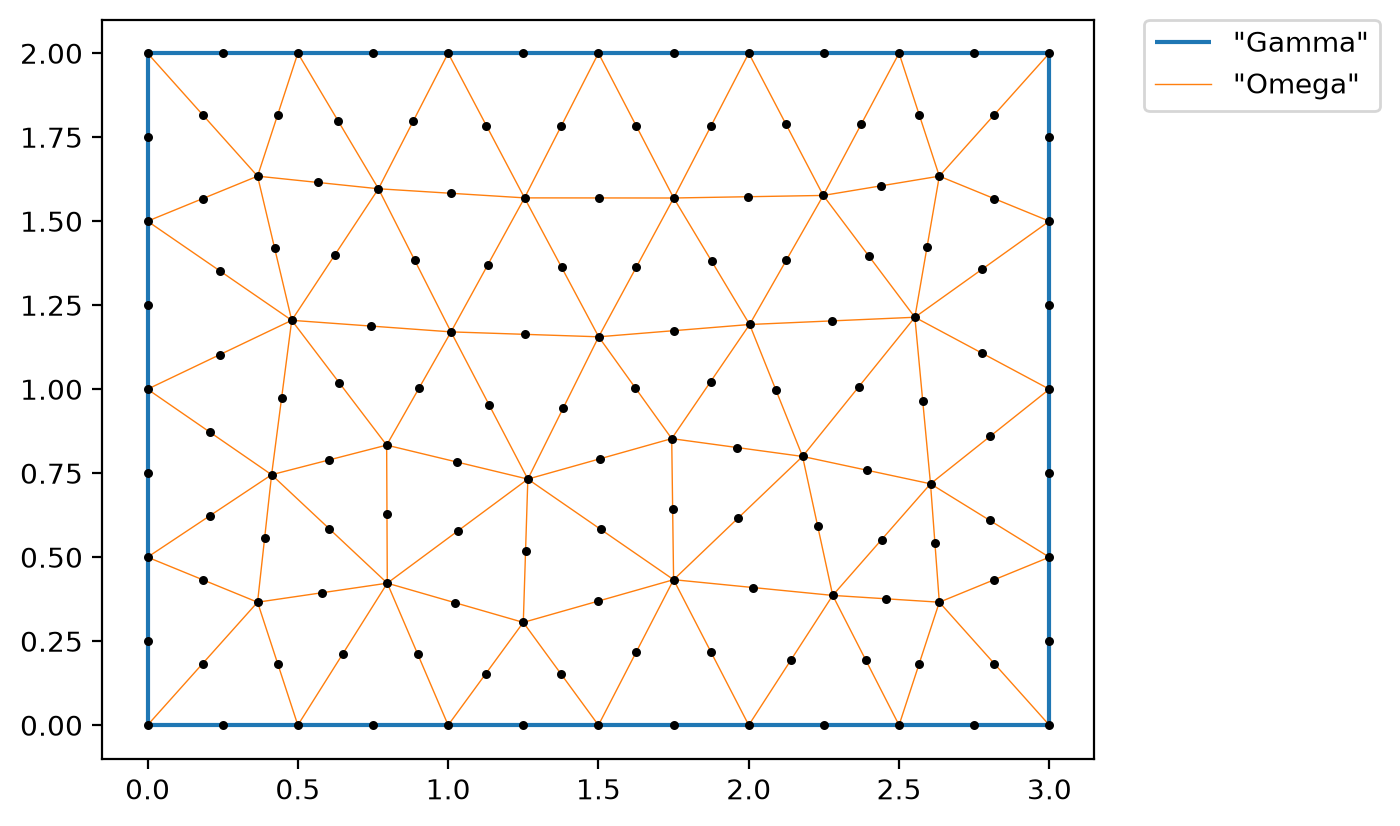

In [5]:
fig, ax = plt.subplots()
src.plot2d_mesh(ax, mesh, show_legend=True, show_nodes=True, show_nodes_indices=False)

## Calcul des matrices élémentaires par passage à l’élément fini de référence

Soit $T_\ell$ un triangle de sommets $M_1=(x_1,y_1)$, $M_2=(x_2,y_2)$ et $M_3=(x_3,y_3)$ et dont les milieux des arêtes sont $M_4=(x_4,y_4)$, $M_5=(x_5,y_5)$ et $M_6=(x_6,y_6)$. Soient $\lambda_1$, $\lambda_2$ et $\lambda_3$ les coordonnées barycentriques du triangle. Les fonctions de base locales sont les suivantes
$$
\begin{aligned}
w_1 &= \lambda_1(2\lambda_1-1), & w_4&=4\lambda_1\lambda_2,\\
w_2 &= \lambda_2(2\lambda_2-1), & w_5&=4\lambda_2\lambda_3,\\
w_3 &= \lambda_3(2\lambda_3-1), & w_6&=4\lambda_3\lambda_1.
\end{aligned}
$$
Pour calculer les matrices élémentaires associées à $T_\ell$, nous allons utiliser la méthode du
passage à l'élément fini de référence. On se ramène tout d'abord au triangle de référence $\hat T$, c’est-à-dire le triangle de sommets $\hat M_1 = (0, 0)$, $\hat M_2 = (1, 0)$ et $\hat M_3 = (0, 1)$.

<span style="color:red"><strong>Question 1.4</strong></span> - Déterminer la matrice $\boldsymbol{\mathcal{B}}_\ell\in\mathcal{M}_2(\mathbb{R})$
et le vecteur $b_\ell\in\mathbb{R}^2$ 
tels que la transformation $\mathcal{F}_\ell:\mathbb{R}^2\to\mathbb{R}^2$ définie par
$$
\mathcal{F}_\ell(\hat M) = \boldsymbol{\mathcal{B}}_\ell \hat M + b_\ell,
\qquad \hat M\in\mathbb{R}^2
$$
permettent de passer du triangle de référence $\hat T$ au triangle $T_\ell$, c'est-à-dire
$$
\forall i=1,2,3, \qquad \mathcal{F}_\ell(\hat M_i) = M_i.
$$

<hr width="50%" align="left">

<span style="color:green">__Réponse 1.4__</span> - On impose $\mathcal{F}_\ell(\hat M_1)=b_\ell=M_1$, puis $\mathcal{F}_\ell(\hat M_2)=\boldsymbol{\mathcal{B}}_\ell e_1+b_\ell=M_2$ et $\mathcal{F}_\ell(\hat M_3)=\boldsymbol{\mathcal{B}}_\ell e_2+b_\ell=M_3$. Les colonnes de $\boldsymbol{\mathcal{B}}_\ell$ sont donc $M_2-M_1$ et $M_3-M_1$ :

$$
\boldsymbol{\mathcal{B}}_\ell=\begin{bmatrix} x_2-x_1 & x_3-x_1\\ y_2-y_1 & y_3-y_1\end{bmatrix},
\qquad
b_\ell=\begin{bmatrix}x_1\\y_1\end{bmatrix}.
$$

On remarque que $\det\boldsymbol{\mathcal{B}}_\ell=(x_2-x_1)(y_3-y_1)-(y_2-y_1)(x_3-x_1)=D$, soit $|\det\boldsymbol{\mathcal{B}}_\ell|=2\,\text{aire}(T_\ell)$. Comme $\mathcal{F}_\ell$ est affine, elle envoie aussi les milieux des arêtes de $\hat T$ sur les milieux des arêtes de $T_\ell$, et $w_I\circ\mathcal{F}_\ell=\hat w_I$.

<hr width="50%" align="left">

Les intégrales de masse sur $T_\ell$ peuvent alors s'écrire
$$
\int_{T_\ell} w_I(M)w_J(M) \operatorname{d}\!\Omega
= \int_{\hat T} 
\hat w_I(\hat M)
\hat w_J(\hat M) 
\vert \det \boldsymbol{\mathcal{B}}_\ell \vert \operatorname{d}\!\hat\Omega,
\qquad 1\leq I,J\leq 6,
\tag{3}
$$
et les intégrales de rigidité
$$
\int_{T_\ell} \nabla w_I(M)\cdot\nabla w_J(M) \operatorname{d}\!\Omega
= \int_{\hat T} 
\big[(\boldsymbol{\mathcal{B}}_\ell^T)^{-1}\hat\nabla\hat w_I(\hat M)\big]
\cdot
\big[(\boldsymbol{\mathcal{B}}_\ell^T)^{-1}\hat\nabla\hat w_J(\hat M)\big]
\vert \det \boldsymbol{\mathcal{B}}_\ell \vert \operatorname{d}\!\hat\Omega,
\qquad 1\leq I,J\leq 6,
\tag{4}
$$


<span style="color:red"><strong>Question 1.5</strong></span> - Rappeler les expressions des coordonnées barycentriques $\hat\lambda_1$, $\hat\lambda_2$ et $\hat\lambda_3$ du triangle de référence $\hat T$.

<hr width="50%" align="left">

<span style="color:green">__Réponse 1.5__</span> - Sur le triangle de référence, en notant $\hat M=(\hat x,\hat y)$ :

$$
\hat\lambda_1(\hat x,\hat y)=1-\hat x-\hat y,\qquad
\hat\lambda_2(\hat x,\hat y)=\hat x,\qquad
\hat\lambda_3(\hat x,\hat y)=\hat y,
$$

de gradients constants $\hat\nabla\hat\lambda_1=(-1,-1)^T$, $\hat\nabla\hat\lambda_2=(1,0)^T$, $\hat\nabla\hat\lambda_3=(0,1)^T$.
Les gradients des fonctions de base $P^2$ s'en déduisent : $\hat\nabla\hat w_i=(4\hat\lambda_i-1)\hat\nabla\hat\lambda_i$ pour $i=1,2,3$ et $\hat\nabla(4\hat\lambda_i\hat\lambda_j)=4(\hat\lambda_j\hat\nabla\hat\lambda_i+\hat\lambda_i\hat\nabla\hat\lambda_j)$ pour les milieux.

<hr width="50%" align="left">

Les intégrales du second membre dans $(3)$ et $(4)$ pourraient être calculées analytiquement, mais il s'agit de calculs laborieux pour les éléments finis $P^2$. Pour les calculer, nous allons plutôt faire appel à une _formule de quadrature_. De façon générale, une formule de quadrature à $N_Q$ points est définie comme suit : pour $G$ une fonction continue par morceaux de $\hat T$, on fait l'approximation
$$
\int_{\hat T} G\operatorname{d}\!\hat\Omega
\simeq \sum_{q=1}^{N_Q} \hat c^q G(\hat S^q),
$$
où $\hat S^q$ sont les points de quadrature dans $\hat T$ et $\hat c^q$ les poids associés aux points de quadrature.
On dit que la formule de quadrature est d'ordre $k$ si elle est exacte pour toutes les fonctions polynomiales $G$ de degré $k$. Pour évaluer les intégrales de $(3)$ et $(4)$, on utilise donc respectivement des formules de quadrature d'ordre 4 et 2.

Pour la matrice de masse, on utilisera la formule de quadrature à 6 points de Gauss-Legendre qui est d'ordre $4$ et qui est définie sur le triangle de référence $\hat T$ par
$$
\begin{aligned}
\hat S^1 &=(0.1081030181681, 0.4459484909160),
& \hat c^1 &=0.1116907948,\\
\hat S^2 &=(0.4459484909160, 0.1081030181681),
& \hat c^2 &=0.1116907948,\\
\hat S^3 &=(0.4459484909160, 0.4459484909160),
& \hat c^3 &=0.1116907948,\\
\hat S^4 &=(0.0915762135098, 0.0915762135098),
& \hat c^4 &=0.05497587183,\\
\hat S^5 &=(0.0915762135098, 0.8168475729805),
& \hat c^5 &=0.05497587183,\\
\hat S^6 &=(0.8168475729805, 0.0915762135098),
& \hat c^6 &=0.05497587183.
\end{aligned}
$$

In [6]:
quad_p4 = src.TRIANGLE_QUAD_P4
print(quad_p4)
display(quad_p4.nodes)
display(quad_p4.weight)

order: 4
nodes            | weight
[0.1081, 0.4459] | 0.1117
[0.4459, 0.1081] | 0.1117
[0.4459, 0.4459] | 0.1117
[0.0916, 0.0916] | 0.0550
[0.0916, 0.8168] | 0.0550
[0.8168, 0.0916] | 0.0550


array([[0.10810302, 0.44594849],
       [0.44594849, 0.10810302],
       [0.44594849, 0.44594849],
       [0.09157621, 0.09157621],
       [0.09157621, 0.81684757],
       [0.81684757, 0.09157621]])

array([0.11169079, 0.11169079, 0.11169079, 0.05497587, 0.05497587,
       0.05497587])

Pour la matrice de rigidité, on utilisera la formule de quadrature à 3 points de Gauss-Legendre qui est d'ordre $2$ et qui est définie sur le triangle de référence $\hat T$ par
$$
\hat S^1 = (\tfrac{1}{6},\tfrac{1}{6}),
\
\hat S^2 = (\tfrac{1}{6},\tfrac{2}{3}),
\
\hat S^3 = (\tfrac{2}{3},\tfrac{1}{6}),
\
\hat c^1 = \hat c^2 = \hat c^3 = \tfrac{1}{6}.
$$

In [7]:
quad_p2 = src.TRIANGLE_QUAD_P2
print(quad_p2)
display(quad_p2.nodes)
display(quad_p2.weight)

order: 2
nodes            | weight
[0.1667, 0.1667] | 0.1667
[0.1667, 0.6667] | 0.1667
[0.6667, 0.1667] | 0.1667


array([[0.16666667, 0.16666667],
       [0.16666667, 0.66666667],
       [0.66666667, 0.16666667]])

array([0.16666667, 0.16666667, 0.16666667])

<span style="color:red"><strong>Question 1.6</strong></span> - Quelle est la dimension de la matrice élémentaire de masse $\mathbb{M}^\ell$ ? A l'aide des éléments ci-dessus, compléter la fonction <tt>elem_mat_M_p2</tt> qui a partir des coordonnées des trois sommets d'un triangle donne la matrice élémentaire de masse.

In [8]:
def elem_mat_M_p2(S1, S2, S3, tol=1e-8):
    """
    Calcul la matrice de masse elementaire en P2 Lagrange.

    Parameters
    ----------
    S1, S2, S3 : les 2 coordonnees des 3 sommets du triangle (vecteurs reels 1x2)

    Returns
    -------
    matrice de masse elementaire (matrice 6x6)
    """
    x1, y1 = S1
    x2, y2 = S2
    x3, y3 = S3

    D = (x2 - x1) * (y3 - y1) - (y2 - y1) * (x3 - x1)
    if abs(D) <= tol:
        raise ValueError("l'aire d'un triangle est nulle !!!")

    S_hat = quad_p4.nodes
    c_hat = quad_p4.weight
    M_elem = np.zeros((6, 6))

    for i in range(6):
        for j in range(6):
            sumq = 0
            for q in range(len(c_hat)):
                w = w_hat_p2(S_hat[q, 0], S_hat[q, 1])
                sumq += c_hat[q] * w[i] * w[j]
            M_elem[i, j] = abs(D) * sumq

    return M_elem

<span style="color:green">__Réponse 1.6__</span> - Il y a 6 fonctions de base locales par triangle (3 sommets + 3 milieux), donc $\mathbb{M}^\ell\in\mathbb{R}^{6\times6}$. D'après $(3)$, $\mathbb{M}^\ell_{ij}=|\det\boldsymbol{\mathcal{B}}_\ell|\sum_q\hat c^q\,\hat w_i(\hat S^q)\,\hat w_j(\hat S^q)$ ; l'intégrande est de degré 4, la formule à 6 points (ordre 4) est donc exacte.

<span style="color:red"><strong>Question 1.7</strong></span> - Quelle est la dimension de la matrice élémentaire de rigidité $\mathbb{K}^\ell$ ? A l'aide des éléments ci-dessus, compléter la fonction <tt>elem_mat_K_p2</tt> qui a partir des coordonnées des trois sommets d'un triangle donne la matrice élémentaire de masse.

In [9]:
def elem_mat_K_p2(S1, S2, S3, tol=1e-8):
    """
    Calcul la matrice de rigidité elementaire en P2 Lagrange.

    Parameters
    ----------
    S1, S2, S3 : les 2 coordonnees des 3 sommets du triangle (vecteurs reels 1x2)

    Returns
    -------
    matrice de rigidité elementaire (matrice 6x6)
    """
    x1, y1 = S1
    x2, y2 = S2
    x3, y3 = S3

    D = (x2 - x1) * (y3 - y1) - (y2 - y1) * (x3 - x1)
    if abs(D) <= tol:
        raise ValueError("l'aire d'un triangle est nulle !!!")

    S_hat = quad_p2.nodes
    c_hat = quad_p2.weight
    K_elem = np.zeros((6, 6))

    Bl = np.array([[x2 - x1, x3 - x1], [y2 - y1, y3 - y1]])
    inv_BlT = np.linalg.inv(Bl.T)

    for i in range(6):
        for j in range(6):
            sumq = 0
            for q in range(len(c_hat)):
                grad_w = grad_w_hat_p2(S_hat[q, 0], S_hat[q, 1])
                grad_i = inv_BlT @ grad_w[i]
                grad_j = inv_BlT @ grad_w[j]
                sumq += c_hat[q] * np.dot(grad_i, grad_j)
            K_elem[i, j] = abs(D) * sumq

    return K_elem

<span style="color:green">__Réponse 1.7__</span> - De même $\mathbb{K}^\ell\in\mathbb{R}^{6\times6}$, avec $\mathbb{K}^\ell_{ij}=|\det\boldsymbol{\mathcal{B}}_\ell|\sum_q\hat c^q\,\big[(\boldsymbol{\mathcal{B}}_\ell^T)^{-1}\hat\nabla\hat w_i(\hat S^q)\big]\cdot\big[(\boldsymbol{\mathcal{B}}_\ell^T)^{-1}\hat\nabla\hat w_j(\hat S^q)\big]$. Les gradients sont de degré 1, l'intégrande de degré 2 : la formule à 3 points (ordre 2) est exacte.

## Assemblage et validation

<span style="color:red"><strong>Question 1.8</strong></span> - Reprendre la partie assemblage du TP précédent. Compléter les fonctions <tt>mat_KM</tt> et <tt>vec_L</tt>, permettant de construire les matrices $\mathbb{K}$ et $\mathbb{M}$ et le vecteur $\vec{L}$.
Comme au TP précédent, pour une donnée $f\in \mathcal{C}^0(\overline{\Omega})$, le vecteur $\vec{L}$ sera construit à l'aide d'une technique d'interpolation.

In [10]:
def mat_KM(mesh):
    """Calcul les matrices de rigidité et de masse en P2 Lagrange.

    Parameters
    ----------
    mesh : Mesh
        le maillage

    Returns
    -------
    K la matrice de rigidité (matrice sparse de taille nb_nodes x nb_nodes)
    M la matrice de masse (matrice sparse de taille nb_nodes x nb_nodes)
    """
    # Create the sparse matrices
    K = sp.dok_array((mesh.nb_nodes, mesh.nb_nodes), dtype=np.float64)
    M = sp.dok_array((mesh.nb_nodes, mesh.nb_nodes), dtype=np.float64)

    #create array containing
    triangles = mesh.domains["Omega"]["triangle"]  #array of 6 nodes (general index) of each triangle
    for k in range(mesh.nb_elements("Omega", "triangle")):
        triangle = triangles[k, :]

        # Coordonnées des sommets du triangles
        # Réponse 1.8 - début
        nS1, nS2, nS3 = triangle[0], triangle[1], triangle[2] 
        S1, S2, S3 = mesh.nodes[nS1], mesh.nodes[nS2], mesh.nodes[nS3]

        M_elem = elem_mat_M_p2(S1, S2, S3)
        K_elem = elem_mat_K_p2(S1, S2, S3)

        for i in range(6):
            I = triangle[i]
            for j in range(6):
                J = triangle[j]
                K[I, J] += K_elem[i, j]
                M[I, J] += M_elem[i, j]
        

        # Réponse 1.8 - fin
    return (K.tocsc(), M.tocsc())

In [11]:
def vec_L(fct, mass_matrix, mesh):
    """Calcule le second membre L.

    Parameters
    ----------
    fct : la fonction `fct` prend comme argument les noeuds du maillage (tableau de taille `(nb_nodes, 2)`)
          et renvoie un vecteur de taille `nb_nodes` qui contient les valeurs de `fct` en chaque noeud. Un
          exemple de fonction `fct` est donné ci-dessous :
      ```def f(nodes):
            x, y = nodes[:, 0], nodes[:, 1]
            return np.cos(x) * np.exp(y)
      ```

    mass_matrix : matrice de masse (matrice sparse de taille nb_nodes x nb_nodes)

    mesh : le maillage

    Returns
    -------
    vecteur L (vecteur de taille nb_nodes x 1)
    """
    # Réponse 1.8 - début
    return mass_matrix @ fct(mesh.nodes)
    # Réponse 1.8 - fin

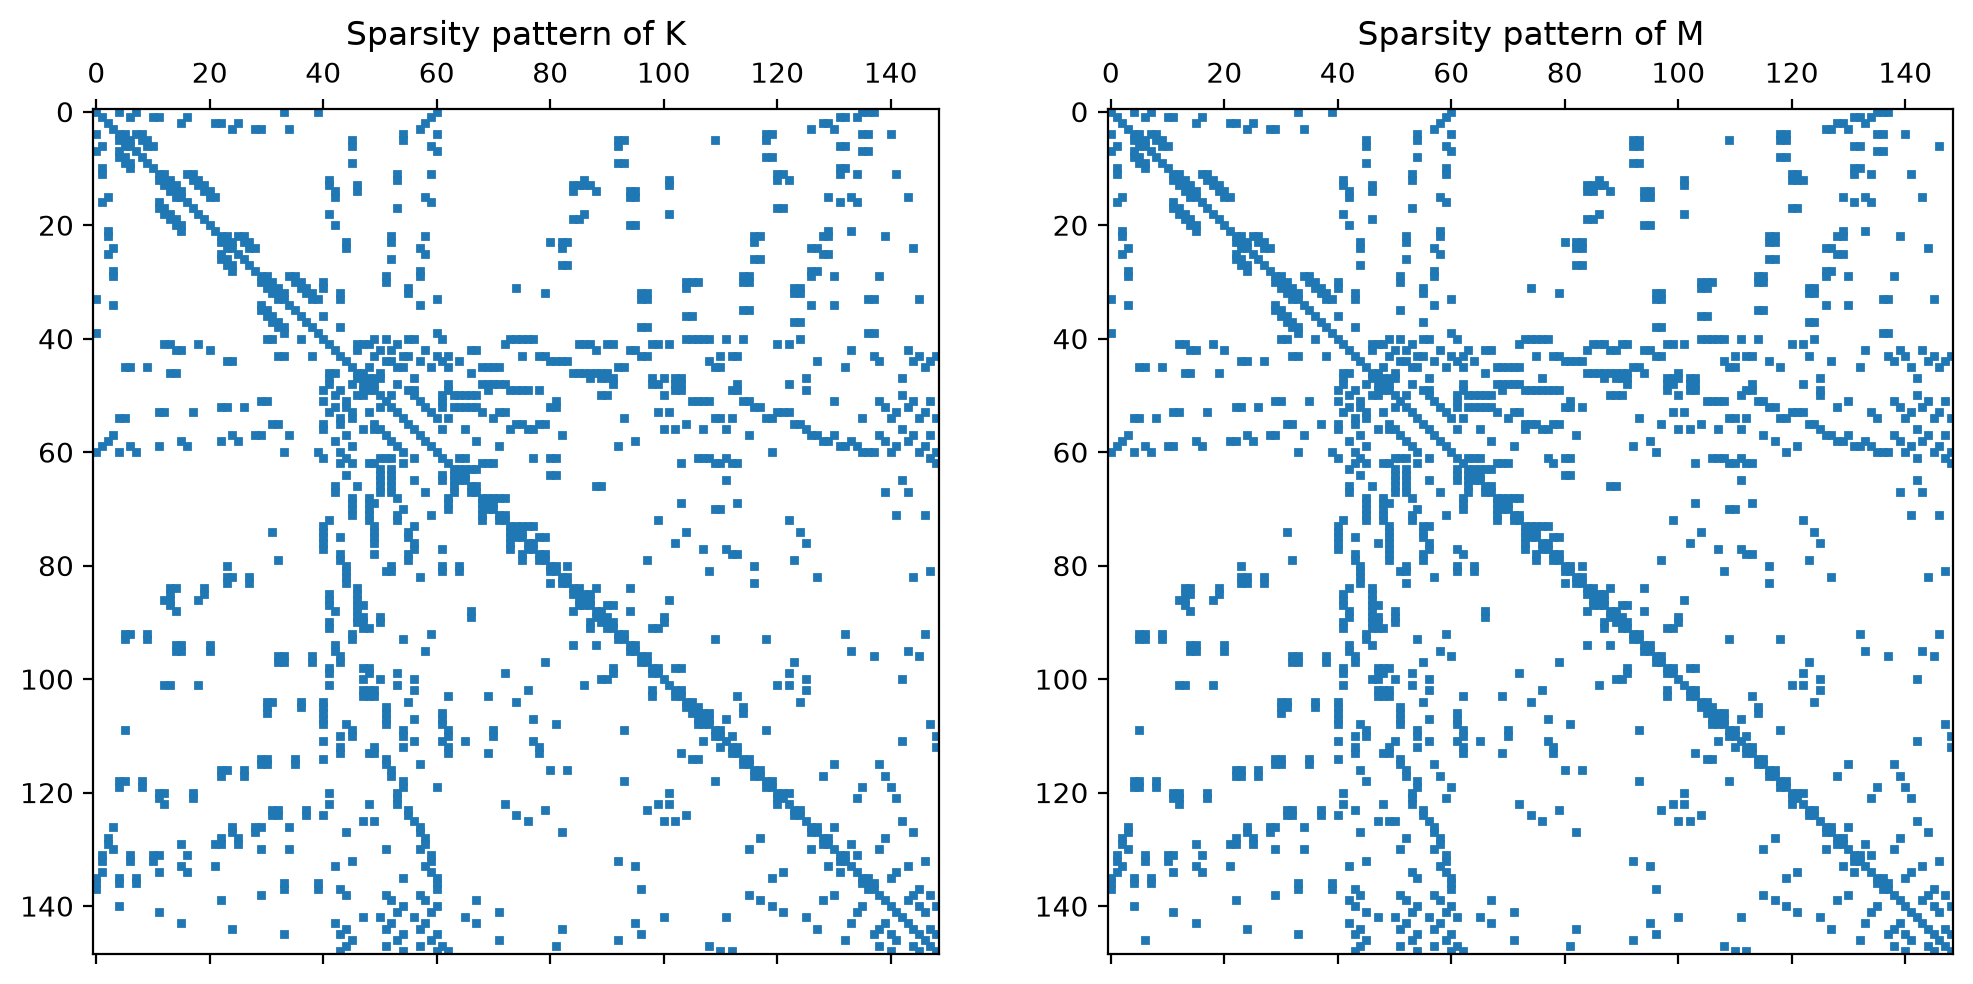

<Figure size 640x480 with 0 Axes>

In [12]:
# Calcul des matrices EF
K, M = mat_KM(mesh)

fig, axs = plt.subplots(ncols=2, figsize=(12, 6))

axs[0].set_title("Sparsity pattern of K")
axs[0].spy(K, markersize=2)

axs[1].set_title("Sparsity pattern of M")
axs[1].spy(M, markersize=2)

plt.show()
plt.savefig('images/fig_KMsparsity.png')

On veut vérifier que le code calcule une solution approchée $u_h$ correcte. Pour cela, on résout le problème $(1)$ avec une solution $u$ connue égale à 
$$
u(x, y) = 3 \cos(\pi x) \cos(2\pi y), 
\qquad (x, y)\in\bar\Omega=[0,3]\times[0,2].
$$

<span style="color:red"><strong>Question 1.9</strong></span> - Vérifier que cette fonction $u$ satisfait bien la condition au bord du problème $(1)$, calculer la donnée $f$ correspondante. Puis résoudre le problème et tracer le graphe de la solution approchée.

nodes: 783 nodes with 2 coordinates
domains:
  "Gamma": line, 50 elements, 3 nodes per element
  "Omega": triangle, 366 elements, 6 nodes per element


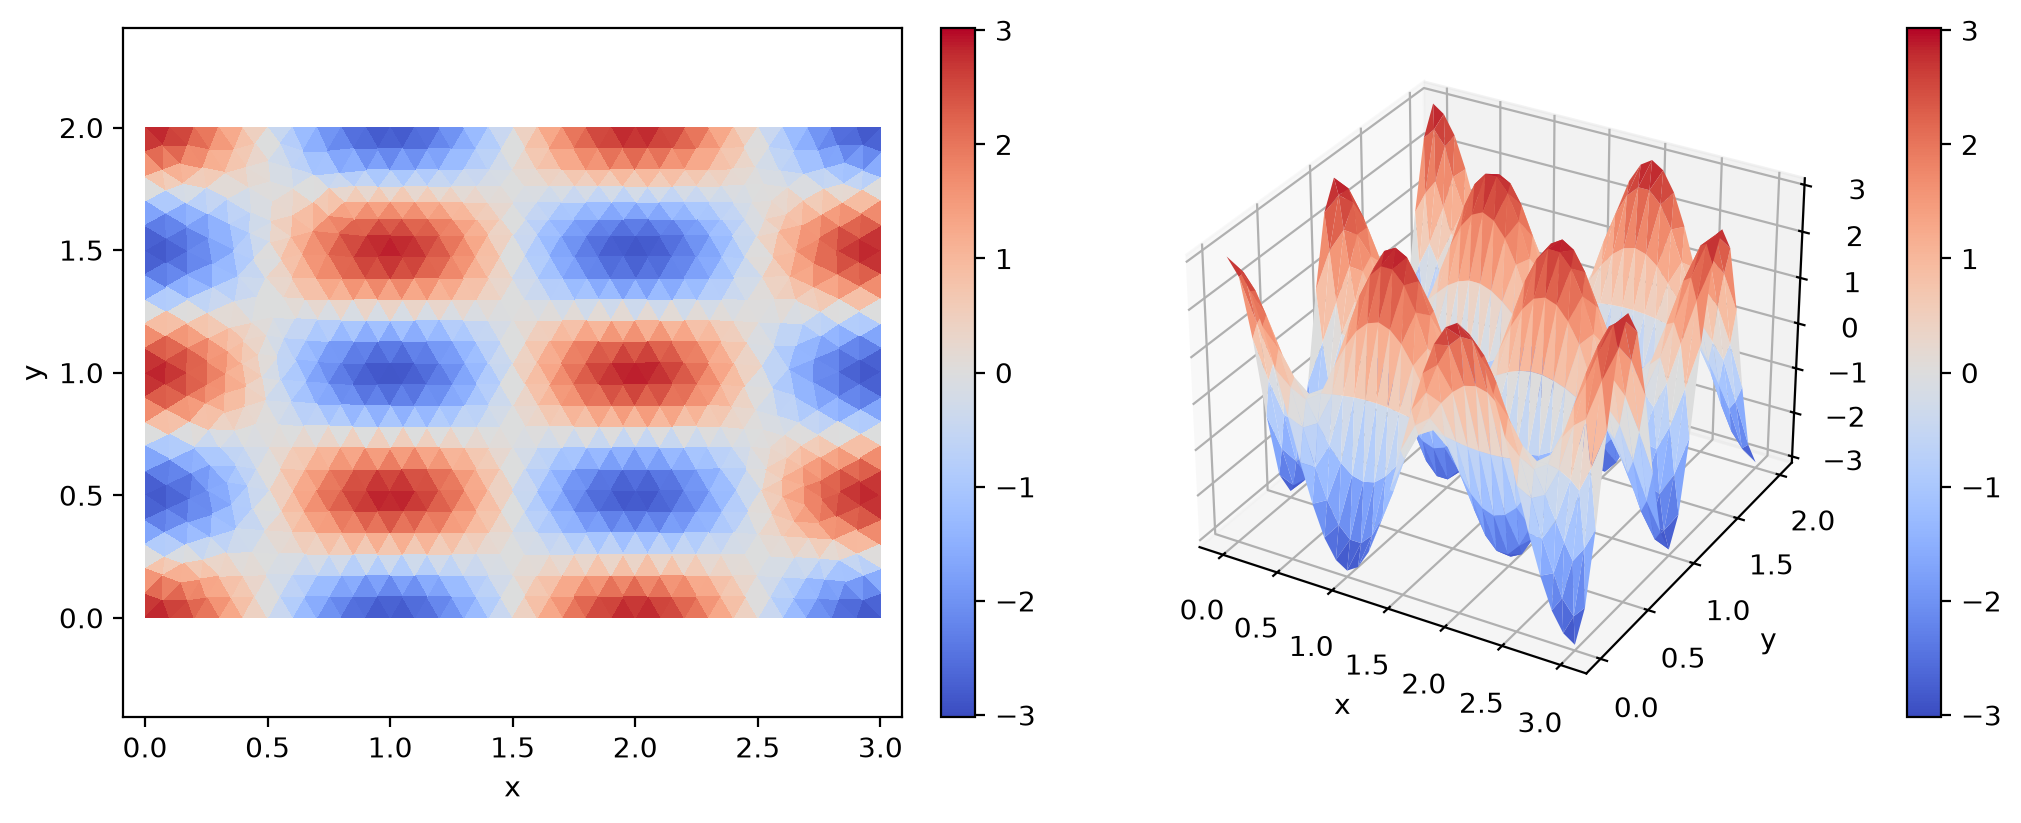

<Figure size 640x480 with 0 Axes>

In [13]:
####################################################
# REPONSE QUESTION 1.9
####################################################
def f(nodes):
    x, y = nodes[:, 0], nodes[:, 1]
    return (3 + 15 * (np.pi)**2) * np.cos(np.pi * x) * np.cos(2*np.pi * y)


# Création du maillage
# mesh = ...
a, b = 3, 2
options = src.GmshOptions(element_order=2)
h = 0.2 #pas
mesh = src.rectangle((0, 0), (a, b), h,  options)
mesh.print_info()

# Assemblage et résolution
K, M = mat_KM(mesh)
L = vec_L(f, M, mesh)

U = src.sparse_solve(K + M, L)

# Affichage de la solution
fig = plt.figure(figsize=(10, 4), layout="constrained")
axs = [fig.add_subplot(1, 2, 1), fig.add_subplot(1, 2, 2, projection="3d")]
for ax in axs:
    ax.axis("equal")
    ax.set_xlabel("x")
    ax.set_ylabel("y")

U_max = np.abs(U).max()
src.plot2d_fct_trimesh(
    ax=axs[0],
    values=U,
    mesh=mesh,
    tripcolor_kwargs={"cmap": "coolwarm", "vmin": -U_max, "vmax": U_max},
)
src.plot3d_fct_trimesh(
    ax=axs[1],
    values=U,
    mesh=mesh,
    trisurf_kwargs={"cmap": "coolwarm", "vmin": -U_max, "vmax": U_max},
)
plt.show()
plt.savefig('images/fig_exactSolution.png')

<span style="color:red"><strong>Question 1.10</strong></span> - En assimilant $u$ à son interpolée $\pi_h u$, donner une estimation de la norme $L^2$ de l'erreur $\Vert u-u_h\Vert_{L^2(\Omega)}$ faisant intervenir la matrice de masse $\mathbb{M}$. Tracer la courbe $\log(1/h)\mapsto\log(\Vert u-u_h\Vert_{L^2(\Omega)}/\Vert u\Vert_{L^2(\Omega)})$ pour différentes valeurs de $h$. Comment évolue cette erreur en fonction de $h$ ? Comparer à l'ordre de convergence obtenu dans le TP1.

<span style="color:red"><strong>Question 1.11</strong></span> - En assimilant $u$ à son interpolée $\pi_h u$, donner une estimation de la semi-norme $H^1$ de l'erreur $\vert u-u_h\vert_1 = \Vert \nabla u- \nabla u_h\Vert_{L^2(\Omega)}$ faisant intervenir la matrice de rigidité $\mathbb{K}$. Tracer la courbe $\log(1/h)\mapsto\log(\vert u-u_h\vert_{1}/\vert u\vert_{1})$ pour différentes valeurs de $h$. Comment évolue cette erreur en fonction de $h$ ? Comparer à l'ordre de convergence obtenu dans le TP1.

In [14]:
####################################################
# REPONSE QUESTION 1.10 et 1.11
####################################################

def u_function(nodes):
    x, y = nodes[:, 0], nodes[:, 1]
    return 3*np.cos(np.pi * x)*np.cos(2*np.pi*y)

def interpolate_in_nodes(fct, nodes):
    return fct(nodes)

def calculate_L2_error(M, U, U_exact):
    """
    Calcule l'erreur de norme L2 ||U - U_exact||_L2 sur un maillage donné
    """
    diff = U - U_exact
    error_sqrd = diff.T @ M @ diff
    norme_U_sqrd = U.T @ M @ U

    return np.sqrt(abs(float(np.squeeze(error_sqrd))) / abs(float(np.squeeze(norme_U_sqrd))))

def calculate_H1_error(K, U, U_exact):
    """
    Calcule l'erreur de semi-norme H1 ||U - U_exact||_H1
    = ||grad(U) - grad(U_exact)||_L2 sur un maillage donné.
    """
    diff = U - U_exact
    error_sqrd = diff.T @ K @ diff
    norme_U_sqrd = U.T @ K @ U

    return np.sqrt(abs(float(np.squeeze(error_sqrd))) / abs(float(np.squeeze(norme_U_sqrd))))

def error_study(h_list, f, U_fct, a, b):
    """
    Réalise une étude d'erreur sur un maillage rectangulaire défini par
    le sommet supérieur droit (a, b), pour les différentes tailles de
    maillage indiquées dans h_list. f définit le second membre et U_fct
    la solution de référence.
    """

    
    L2_errors = {}
    H1_errors = {}

    for h in h_list:
        # Define Mesh

        options = src.GmshOptions(element_order=2)
        mesh = src.rectangle((0, 0), (a, b), h,  options)
        
        # Define mass & rigidty matrices
        K, M = mat_KM(mesh)
        
        # Define right-hand side
        L = vec_L(f, M, mesh)

        # Calc U
        U = src.sparse_solve(K + M, L)

        # Calc U_exact
        U_exact = interpolate_in_nodes(U_fct, mesh.nodes)

        # Calc L2 error
        L2_error = calculate_L2_error(M, U, U_exact)
        H1_error = calculate_H1_error(K, U, U_exact)

        L2_errors[h] = L2_error 
        H1_errors[h] = H1_error

    return L2_errors, H1_errors

#error study
h = np.arange(0.05, 0.4, 0.05)
L2_dict, H1_dict = error_study(h, f, u_function, 3, 2)
L2_errors, H1_errors = list(L2_dict.values()), list(H1_dict.values())


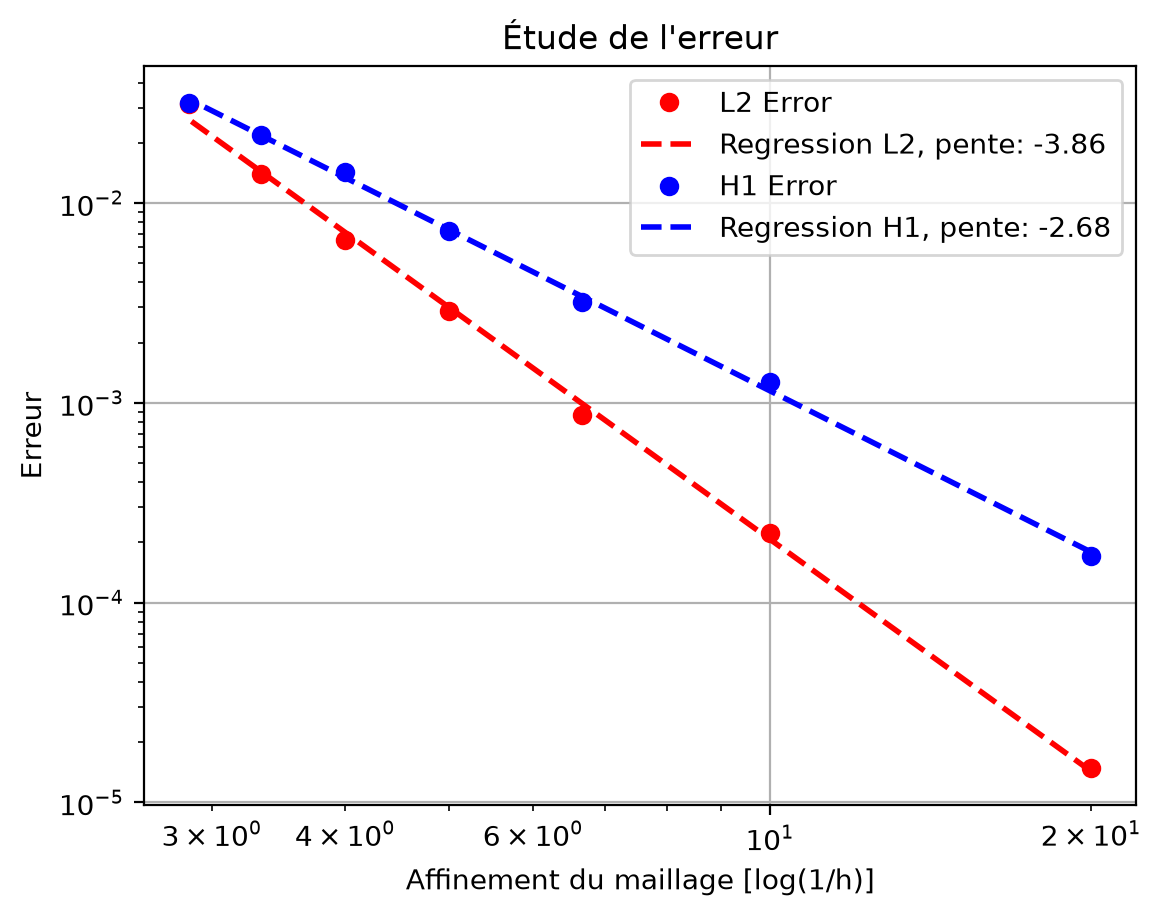

0

In [15]:
#preparation to plot
def plot_errors(L2_errors, H1_errors, figpath:str= None):

    fitL2_func = np.poly1d(np.polyfit(np.log(1/h), np.log(L2_errors), 1))
    fitH1_func = np.poly1d(np.polyfit(np.log(1/h), np.log(H1_errors), 1))

    fig, ax = plt.subplots() 

    ax.loglog(1/h, L2_errors, 'or', label='L2 Error', linewidth=2)
    ax.loglog(1/h, np.exp(fitL2_func(np.log(1/h))), '--r', label=f'Regression L2, pente: {fitL2_func[1]:.2f}', linewidth=2 )

    ax.loglog(1/h, H1_errors, 'ob', label= 'H1 Error', linewidth=2)
    ax.loglog(1/h, np.exp(fitH1_func(np.log(1/h))), '--b', label=f'Regression H1, pente: {fitH1_func[1]:.2f}', linewidth=2 )

    ax.set_xlabel('Affinement du maillage [log(1/h)]')
    ax.set_ylabel('Erreur')
    ax.grid(visible=True)
    ax.set_title("Étude de l'erreur")
    ax.legend()

    if figpath:
        plt.savefig(figpath)

    plt.show()

    return 0

plot_errors(L2_errors, H1_errors, figpath= 'images/fig_errorstudy_elementsP2.png')

<hr width="50%" align="left">

<span style="color:green">__Réponse 1.10 et 1.11__</span> - En assimilant $u$ à $\pi_h u$, l'erreur $\pi_hu-u_h\in V_h$ a pour coordonnées $\vec E=\vec U_{ex}-\vec U$ dans la base $(w_I)$, d'où

$$
\Vert u-u_h\Vert_{L^2(\Omega)}\simeq\sqrt{\vec E^T\,\mathbb{M}\,\vec E},
\qquad
\vert u-u_h\vert_{1}\simeq\sqrt{\vec E^T\,\mathbb{K}\,\vec E},
$$

et on divise par $\sqrt{\vec U_{ex}^T\mathbb{M}\vec U_{ex}}$ et $\sqrt{\vec U_{ex}^T\mathbb{K}\vec U_{ex}}$ pour obtenir les erreurs relatives.

**Théorie.** Pour une solution régulière et des éléments finis $P^k$, le lemme de Céa et les estimations d'interpolation donnent $\Vert u-u_h\Vert_{H^1}\le C h^{k}$, et un ordre de plus en norme $L^2$ (dualité d'Aubin-Nitsche) : $\Vert u-u_h\Vert_{L^2}\le Ch^{k+1}$. On attend donc $h^3$ en norme $L^2$ et $h^2$ en semi-norme $H^1$ pour les $P^2$, contre $h^2$ et $h$ pour les $P^1$ du TP1.

**Observation.** Les pentes mesurées sont d'environ $3{,}9$ en norme $L^2$ et $2{,}7$ en semi-norme $H^1$. Elles sont au moins égales aux ordres théoriques, et même un peu meilleures : on ne mesure pas $u-u_h$ mais $\pi_hu-u_h$, qui ne contient pas l'erreur d'interpolation à l'intérieur des triangles.

En comparant avec le graphe du TP1 :

<img src="images/fig_errorstudy_elementsP1.png">

on gagne un ordre de convergence sur chaque norme en passant de $P^1$ à $P^2$ (ordres théoriques $3$ contre $2$ en norme $L^2$, $2$ contre $1$ en semi-norme $H^1$) : pour un même maillage, l'erreur est beaucoup plus petite, et elle décroît plus vite quand on raffine.

<hr width="50%" align="left">

# Exercice 2 : Éléments finis $P^2$ pour le problème de Poisson avec condition de Dirichlet

Dans cet exercice, nous considérons toujours $\Omega$ un ouvert borné de $\mathbb{R}^2$ à frontière polygonale et $f\in L^2(\Omega)$.
Nous considérons maintenant un problème de Poisson avec une condition au bord de Dirichlet homogène : trouver $u \in H^1(\Omega)$ tel que 
$$
\left \{
\begin{aligned}
& u - \Delta u = f  & \text{ dans } \Omega,\\
& u = 0 & \text{ sur } \partial \Omega. 
\end{aligned}
\right.
\tag{$7$}
$$
Nous avons vu dans le cours que la formulation variationelle du problème $(7)$ s'écrit
$$
\begin{gathered}
\text{Trouver } u\in H_0^1(\Omega) \text{ qui vérifie }\\
\forall v \in H_0^1(\Omega) \quad
\int_\Omega u v \operatorname{d}\!\Omega +
\int_\Omega \nabla u\cdot \nabla v \operatorname{d}\!\Omega = \int_\Omega f v \operatorname{d}\!\Omega,
\end{gathered}
$$
et qu'elle est bien posée.

## Discrétisation

Nous reprenons les notations de l'exercice précédent. Pour définir une approximation interne $P^2$ de $H_0^1(\Omega)$, on procède de la façon suivante : si on suppose que les nœuds (sommets et milieux) de la frontière $\partial\Omega$ sont numérotés de $N_0+1$ à $N$ et que les nœuds intérieur sont numérotés de $1$ à $N_0$, on définit
$$
V_h^0 = \operatorname{Vect}(w_1, \ldots, w_{N_0}).
$$
Par construction, $V_h^0\subset H_0^1(\Omega)$.

<span style="color:red"><strong>Question 2.1</strong></span> - Quelle est la formulation variationnelle discrète vérifiée par la solution approchée $u_h$ ?

<hr width="50%" align="left">

<span style="color:green">__Réponse 2.1__</span> - 


### 1. Obtention de la formulation variationnelle continue

On considère le problème scalaire (de type Poisson / Laplace avec terme source $f$) :
$$-\nu \Delta u = f \quad \text{dans } \Omega$$

1. **Multiplication par une fonction test $v$ :**
   Soit $v \in H_0^1(\Omega)$ une fonction test. Comme $v$ appartient à $H_0^1(\Omega)$, elle s'annule sur la frontière de Dirichlet $\partial\Omega$ ($v_{|\partial\Omega} = 0$), ce qui correspond à l'imposition des conditions aux limites essentielles.
   En multipliant l'équation par $v$ :
   $$-\nu \Delta u \, v = f v$$

2. **Intégration sur le domaine $\Omega$ :**
   $$\int_\Omega -\nu \Delta u \, v \, \mathrm{d}\Omega = \int_\Omega f v \, \mathrm{d}\Omega$$

3. **Application de la formule de Green :**
   En appliquant la formule de Green (intégration par parties) au terme d'ordre 2 :
   $$\nu \int_\Omega \nabla u \cdot \nabla v \, \mathrm{d}\Omega - \nu \int_{\partial\Omega} \frac{\partial u}{\partial n} v \, \mathrm{d}\Gamma = \int_\Omega f v \, \mathrm{d}\Omega$$

4. **Annulation de l'intégrale de bord :**
   Grâce à la condition de Dirichlet essentielle imposée dans l'espace fonctionnel $v \in H_0^1(\Omega)$, on a $v_{|\partial\Omega} = 0$. L'intégrale de bord s'annule donc identiquement :
   $$\int_{\partial\Omega} \frac{\partial u}{\partial n} v \, \mathrm{d}\Gamma = 0$$

On obtient ainsi la **formulation variationnelle continue** :
$$\text{Trouver } u \in H^1(\Omega) \text{ tel que } a(u, v) = l(v), \quad \forall v \in H_0^1(\Omega)$$

où la forme bilinéaire $a(\cdot, \cdot)$ et la forme linéaire $l(\cdot)$ sont définies par :
$$a(u, v) = \nu \int_\Omega \nabla u \cdot \nabla v \, \mathrm{d}\Omega$$
$$l(v) = \int_\Omega f v \, \mathrm{d}\Omega$$

---

### 2. Discrétisation et formulation variationnelle discrète

1. **Espaces d'approximation discrète :**
   On approche l'espace fonctionnel infini $H_0^1(\Omega)$ par le sous-espace de dimension finie $V_h^0 = \operatorname{Vect}(w_1, \dots, w_{N_0}) \subset H_0^1(\Omega)$, formé par les fonctions de base $P^2$ associées aux nœuds intérieurs $1, \dots, N_0$.

2. **Décomposition de la solution approchée $u_h$ :**
   La solution approchée $u_h$ se décompose sur la base globale des nœuds $(w_J)_{J=1, \dots, N}$ :
   $$u_h = \sum_{J=1}^{N_0} U_J w_J + \sum_{J=N_0+1}^N U_J w_J$$
   où les degrés de liberté $(U_J)_{J=1, \dots, N_0}$ sont les inconnues intérieures, et les termes pour $J > N_0$ représentent le relèvement des conditions aux limites de Dirichlet connues sur le bord.

3. **Formulation variationnelle discrète :**
   La formulation variationnelle discrète consiste à chercher $u_h$ vérifiant l'égalité pour toute fonction test discrète $v_h \in V_h^0$ :

   $$\text{Trouver } u_h \text{ tel que } a(u_h, v_h) = l(v_h), \quad \forall v_h \in V_h^0$$

   Par linéarité, tester pour tout $v_h \in V_h^0$ équivaut à tester la relation sur chacune des fonctions de base de $V_h^0$ ($w_I$ pour $I = 1, \dots, N_0$) :

   $$a(u_h, w_I) = l(w_I), \quad \forall I \in \{1, \dots, N_0\}$$


<hr width="50%" align="left">

La solution approchée $u_h$ s'écrit
$$
u_h(x, y) = \sum_{J=1}^{N_0} u_h(M_J) w_J(x, y), 
\qquad \forall(x,y)\in\bar\Omega,
$$
où $M_J$ est le nœud d'indice $J$.

<span style="color:red"><strong>Question 2.2</strong></span> - Exprimer la formulation variationnelle discrète sous la forme d'un système linéaire équivalent 
$$
\mathbb{A}^0 \vec U^0 = \vec L^0,
    \tag{$8$}
$$
où la $I$-ème composante du vecteur $\vec U^0$ vaut $u_h(M_I)$ et où l'on écrira $\mathbb{A}^0 = \mathbb{M}^0 + \mathbb{K}^0$ avec $\mathbb{M}^0$ la matrice de masse et $\mathbb{K}^0$ la matrice de rigidité. Quelles sont les propriétés fondamentales de la matrice $\mathbb{A}^0$ ?

<hr width="50%" align="left">

<span style="color:green">__Réponse 2.2__</span> - 

### 1. Choix des fonctions tests dans la base de $V_h^0$

La formulation variationnelle discrète doit être vérifiée pour tout $v_h \in V_h^0 = \operatorname{Vect}(w_1, \dots, w_{N_0})$. Par linéarité par rapport à la seconde variable, il suffit de tester l'égalité sur les fonctions de base $w_I$ pour chaque nœud intérieur $I \in \{1, \dots, N_0\}$ :
$$a(u_h, w_I) = l(w_I), \quad \forall I \in \{1, \dots, N_0\}$$

---

### 2. Décomposition de $u_h$ sur la base éléments finis

La solution approchée $u_h$ se décompose sur les fonctions de base associées aux nœuds intérieurs $1, \dots, N_0$ :
$$u_h(x, y) = \sum_{J=1}^{N_0} U_J^0 w_J(x, y)$$
où $U_J^0 = u_h(M_J)$ représente la $J$-ème composante du vecteur $\vec{U}^0$.

En injectant cette expression dans la formulation variationnelle discrète et en utilisant la bilinéarité de $a(\cdot, \cdot)$ :
$$\sum_{J=1}^{N_0} a(w_J, w_I) U_J^0 = l(w_I), \quad \forall I \in \{1, \dots, N_0\}$$

---

### 3. Écriture sous forme de système linéaire matriciel

En décomposant la forme bilinéaire $a(w_J, w_I)$ en son terme de masse et son terme de rigidité :

* **Matrice de masse $\mathbb{M}^0 \in \mathbb{R}^{N_0 \times N_0}$ :**
  $$\mathbb{M}^0_{IJ} = \int_\Omega w_J w_I \, \mathrm{d}\Omega$$

* **Matrice de rigidité $\mathbb{K}^0 \in \mathbb{R}^{N_0 \times N_0}$ :**
  $$\mathbb{K}^0_{IJ} = \nu \int_\Omega \nabla w_J \cdot \nabla w_I \, \mathrm{d}\Omega$$

* **Matrice globale $\mathbb{A}^0 = \mathbb{M}^0 + \mathbb{K}^0 \in \mathbb{R}^{N_0 \times N_0}$ :**
  $$\mathbb{A}^0_{IJ} = \mathbb{M}^0_{IJ} + \mathbb{K}^0_{IJ} = a(w_J, w_I)$$

* **Vecteur second membre $\vec{L}^0 \in \mathbb{R}^{N_0}$ :**
  $$\vec{L}^0_I = l(w_I) = \int_\Omega f w_I \, \mathrm{d}\Omega$$

Le système d'équations pour $I = 1, \dots, N_0$ s'écrit alors sous la forme matricielle équivalente :
$$\mathbb{A}^0 \vec{U}^0 = \vec{L}^0$$

---

### 4. Propriétés fondamentales de la matrice $\mathbb{A}^0$

* **Symétrie :** $\mathbb{A}^0$ est symétrique ($\mathbb{A}^0_{IJ} = \mathbb{A}^0_{JI}$) car le produit scalaire et le produit vectoriel des gradients dans $\mathbb{M}^0$ et $\mathbb{K}^0$ sont commutatifs.
* **Définie positive :** $\mathbb{A}^0$ est définie positive (SPD). Pour tout vecteur non nul $\vec{X} \in \mathbb{R}^{N_0}$, $(\vec{X})^T \mathbb{A}^0 \vec{X} = a(v_h, v_h) > 0$ avec $v_h = \sum_{I=1}^{N_0} X_I w_I \neq 0$, du fait de la coercivité de la forme bilinéaire $a(\cdot, \cdot)$.
* **Creuse (*sparse*) :** Le coefficient $\mathbb{A}^0_{IJ}$ est non nul seulement si les nœuds $M_I$ et $M_J$ appartiennent à un même élément du maillage (intersection non vide des supports de $w_I$ et $w_J$).
* **Inversibilité :** Étant symétrique définie positive, la matrice $\mathbb{A}^0$ est inversible, garantissant l'existence et l'unicité de la solution approchée $\vec{U}^0$.

<hr width="50%" align="left">

Dans la pratique, plutôt que de résoudre le système linéaire $(8)$, on préfère résoudre 
$$
\tilde{\mathbb{A}}\vec U = \tilde{\vec L}
\tag{$9$}
$$
obtenu à l'aide de la technique de _pseudo-élimination_.

<span style="color:red"><strong>Question 2.3</strong></span> - Rappeler les expressions de $\tilde{\mathbb{A}}\in\mathbb{R}^{N\times N}$ et de $\tilde{\vec L}\in\mathbb{R}^N$ en fonction de $\mathbb{A}^0$ et $\vec L^0$.

<hr width="50%" align="left">

<span style="color:green">__Réponse 2.3__</span> -

La technique de **pseudo-élimination** permet d'imposer les conditions aux limites de Dirichlet (ici homogènes, $u_{|\partial\Omega} = 0$) dans le système global de taille $N \times N$, tout en préservant la taille globale et la numérotation des nœuds.

En séparant les degrés de liberté en deux blocs :
* Les $N_0$ nœuds intérieurs,
* Les $N_b = N - N_0$ nœuds situés sur le bord $\partial\Omega$,

la matrice $\tilde{\mathbb{A}} \in \mathbb{R}^{N \times N}$ et le second membre $\tilde{\vec{L}} \in \mathbb{R}^N$ s'écrivent par blocs en fonction de $\mathbb{A}^0$ et $\vec{L}^0$ :

$$\tilde{\mathbb{A}} = \begin{bmatrix} \mathbb{A}^0 & \mathbb{0}_{N_0 \times N_b} \\ \mathbb{0}_{N_b \times N_0} & \rho \mathbb{I}_{N_b} \end{bmatrix}$$

$$\tilde{\vec{L}} = \begin{bmatrix} \vec{L}^0 \\ \vec{0}_{N_b} \end{bmatrix}$$

où :
* $\mathbb{A}^0 \in \mathbb{R}^{N_0 \times N_0}$ et $\vec{L}^0 \in \mathbb{R}^{N_0}$ sont la matrice et le vecteur du système réduit (8) sur les nœuds intérieurs,
* $\mathbb{0}$ désigne les matrices de couplage nulles entre l'intérieur et le bord,
* $\mathbb{I}_{N_b}$ est la matrice identité de taille $N_b \times N_b$,
* $\rho > 0$ est un paramètre de pseudo-élimination (généralement $\rho = 1$ ou un facteur d'échelle adapté au conditionnement de $\mathbb{A}^0$).

<hr width="50%" align="left">

<span style="color:red"><strong>Question 2.4</strong></span> - Implémenter la fonction <tt>elimine</tt> afin qu'elle réalise la <i>pseudo-élimination</i> des nœuds sur la frontière. 

<div class="alert alert-block alert-info">
<strong>Information & indications</strong>

Dans le code, vous ne pouvez pas supposer que les nœuds de la frontière $\partial\Omega$ ont une numérotation spéciale : la numérotation dépend du mailleur. Vous devrez repérer les numéros des nœuds de la frontière grâce à la fonction membre <tt>domain_node_indices</tt> de l'instance <tt>mesh</tt>.
</div>

<div class="alert alert-block alert-info">
<strong>Aide</strong>

Le format <tt>dok</tt> n'est pas très adapté pour modifier les lignes et/ou les colonnes d'une matrice. Vous pourrez lui préférer le format <tt>lil</tt>.
</div>

In [16]:
def elimine(A, L, mesh, dirichlet_bound):
    """
    Effectue la pseudo-élimination sur la matrice A et le second membre L.
    Seulement por les conditions de Dirichilet Homogènes

    Parameters
    ----------
    A : ndarray
        la matrice creuse du système linéaire

    L : ndarray
        le second membre du système linéaire

    mesh : Mesh
        le maillage

    dirichlet_bound: str
        nom du bord où l'on doit faire l'élimination

    Returns
    -------
    A_tilde la matrice modifiée (matrice sparse de taille nb_nodes x nb_nodes)
    L_tilde le second membre (vecteur de taille nb_nodes)
    """

    nb_nodes = mesh.nb_nodes

    A_tilde = A.tolil()
    L_tilde = L.copy()

    nodes_indices_bord = mesh.domain_node_indices(domain_name= dirichlet_bound, element_type= 'line')
    rho = 1

    # Réponse 2.4 - début
    for i in nodes_indices_bord:

            A_tilde[i, :] = 0
            A_tilde[i, i] = rho

            L_tilde[i] = 0

    # Réponse 2.4 - fin

    return A_tilde.tocsc(), L_tilde

## Validation

<span style="color:red"><strong>Question 2.5</strong></span> - Vérifier que le code calcule une solution approchée $u_h$ correcte.
Vous pourrez choisir une solution de référence qui vérifie la condition au bord de Dirichlet homogène et calculer la donnée $f$ correspondante.

nodes: 2965 nodes with 2 coordinates
domains:
  "Gamma": line, 100 elements, 3 nodes per element
  "Omega": triangle, 1432 elements, 6 nodes per element


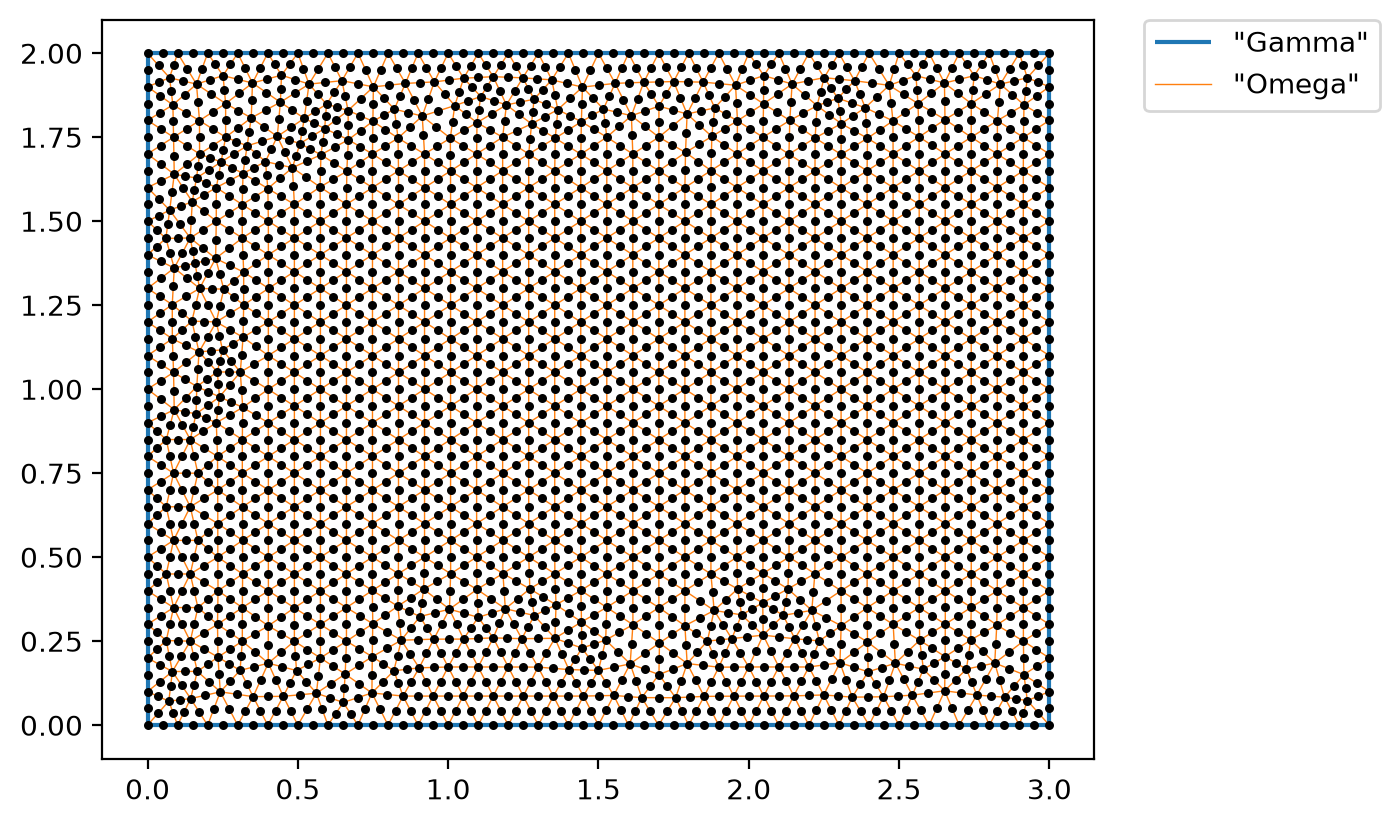

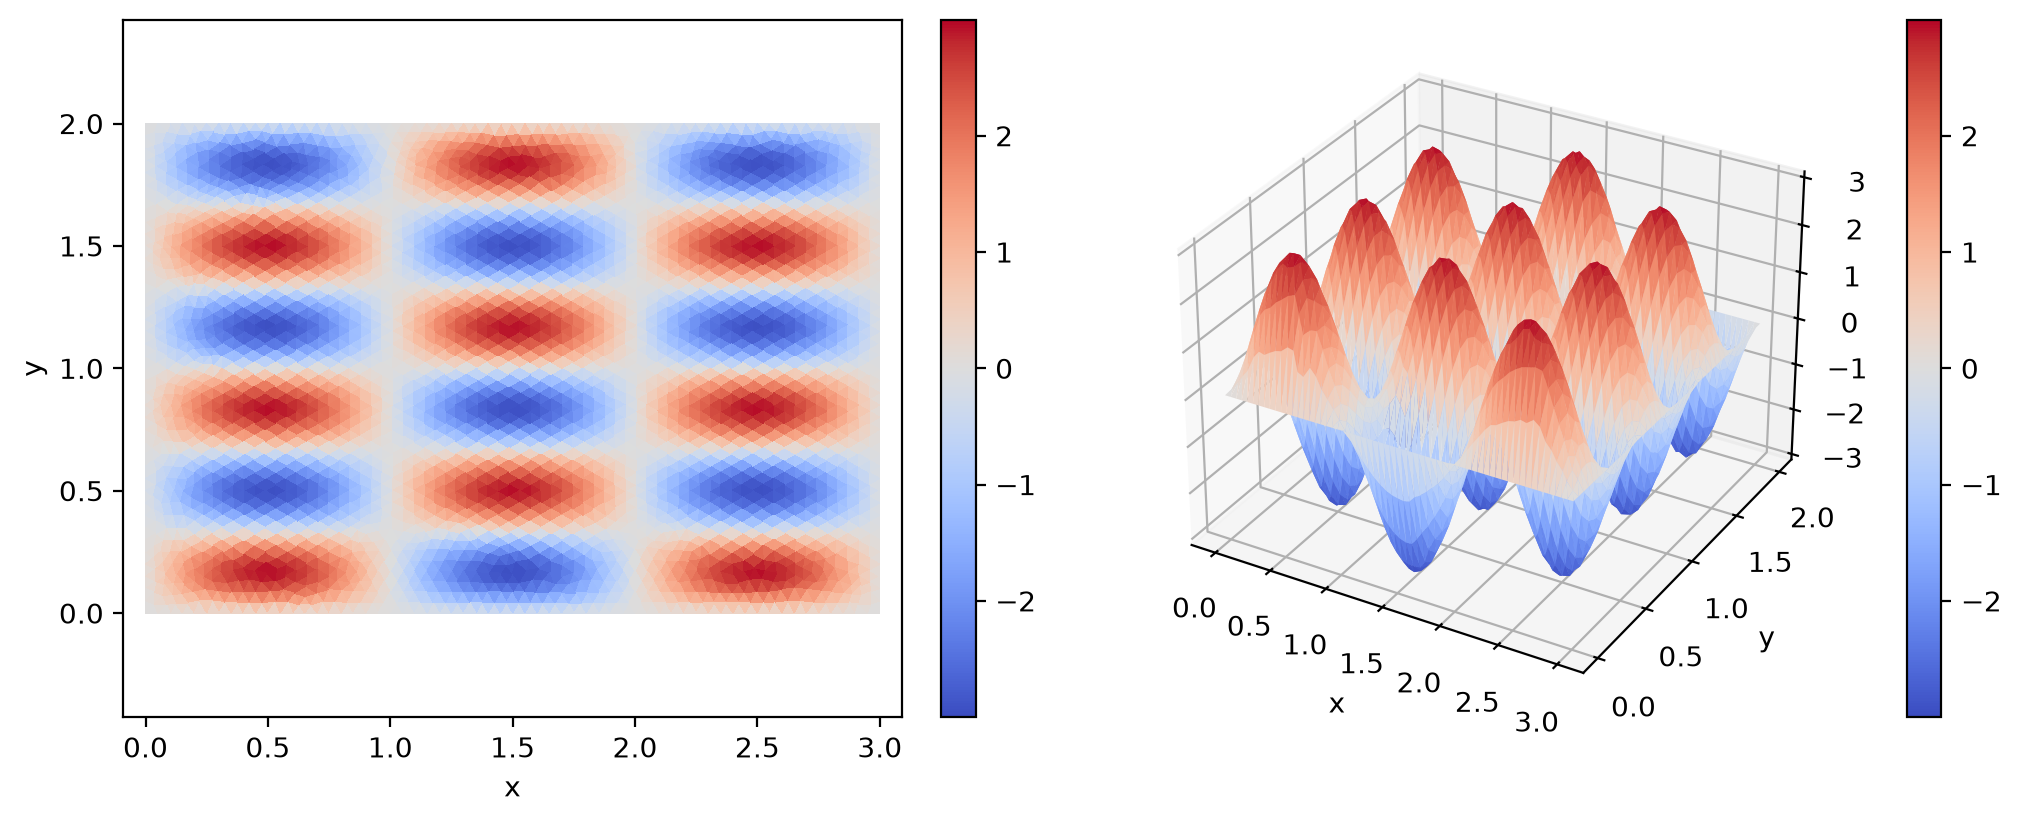

In [17]:
####################################################
# REPONSE QUESTION 2.5
####################################################

#definission du maillage
options = src.GmshOptions(element_order=2)
a, b = 3, 2
h = 0.1
mesh = src.rectangle((0, 0), (a, b), h, options)
mesh.print_info()

fig, ax = plt.subplots()

src.plot2d_mesh(ax, mesh, show_legend=True, show_nodes=True, show_nodes_indices=False)

#fonction f
def f1(nodes):
    x, y = nodes[:, 0], nodes[:, 1]
    return (3 + 30 * (np.pi)**2) * np.sin(np.pi * x) * np.sin(3*np.pi * y)

#encontrar as matrizes A e L
K1, M1 = mat_KM(mesh)
A1 = M1 + K1
L1 = vec_L(f1, M1, mesh)

#aplicar pseudo-eliminacao
A, L = elimine(A1, L1, mesh, 'Gamma')

#solucionar
U = src.sparse_solve(A, L)

# Affichage de la solution
fig = plt.figure(figsize=(10, 4), layout="constrained")
axs = [fig.add_subplot(1, 2, 1), fig.add_subplot(1, 2, 2, projection="3d")]
for ax in axs:
    ax.axis("equal")
    ax.set_xlabel("x")
    ax.set_ylabel("y")

U_max = np.abs(U).max()
src.plot2d_fct_trimesh(
    ax=axs[0],
    values=U,
    mesh=mesh,
    tripcolor_kwargs={"cmap": "coolwarm", "vmin": -U_max, "vmax": U_max},
)
src.plot3d_fct_trimesh(
    ax=axs[1],
    values=U,
    mesh=mesh,
    trisurf_kwargs={"cmap": "coolwarm", "vmin": -U_max, "vmax": U_max},
)
plt.show()

#vérifier que le résultat est conforme


<span style="color:red"><strong>Question 2.6</strong></span> - Tracer les courbes $\log(1/h)\mapsto\log(\Vert u-u_h\Vert_{L^2(\Omega)}/\Vert u\Vert_{L^2(\Omega)})$ et $\log(1/h)\mapsto\log(\vert u-u_h\vert_{1}/\vert u\vert_{1})$ pour différentes valeurs de $h$. Comment évolue cette erreur en fonction de $h$ ? Expliquer.

In [18]:
####################################################
# REPONSE QUESTION 2.6
####################################################

def u1_function(nodes):
    # Function that defines the function
    x, y = nodes[:, 0], nodes[:, 1]
    return 3 * np.sin(np.pi * x)*np.sin(3*np.pi*y)

def error_study(h_list, f, U_fct, a, b):
    """
    Effectue une étude d'erreur sur un maillage rectangulaire défini par les coordonnées
    du nœud supérieur droit (a, b), pour plusieurs tailles de maillage données dans h_list,
    en considérant une fonction f pour le second membre et une solution de référence U_fct.
    """

    
    L2_errors = {}
    H1_errors = {}

    for h in h_list:
        # Define Mesh

        options = src.GmshOptions(element_order=2)
        mesh = src.rectangle((0, 0), (a, b), h,  options)
        
        # Define mass & rigidty matrices
        K1, M1 = mat_KM(mesh)
        A1 = K1 + M1
        
        # Define right-hand side
        L1 = vec_L(f, M1, mesh)

        A, L = elimine(A1, L1, mesh, 'Gamma')

        # Calc U
        U = src.sparse_solve(A, L)

        # Calc U_exact
        U_exact = interpolate_in_nodes(U_fct, mesh.nodes)

        # Calc L2 error
        L2_error = calculate_L2_error(M1, U, U_exact)
        H1_error = calculate_H1_error(K1, U, U_exact)

        L2_errors[h] = L2_error 
        H1_errors[h] = H1_error

    return L2_errors, H1_errors

#error study
h = np.array([0.4, 0.2, 0.1, 0.05])
L2_dict, H1_dict = error_study(h, f1, u1_function, 3, 2)
L2_errors, H1_errors = list(L2_dict.values()), list(H1_dict.values())

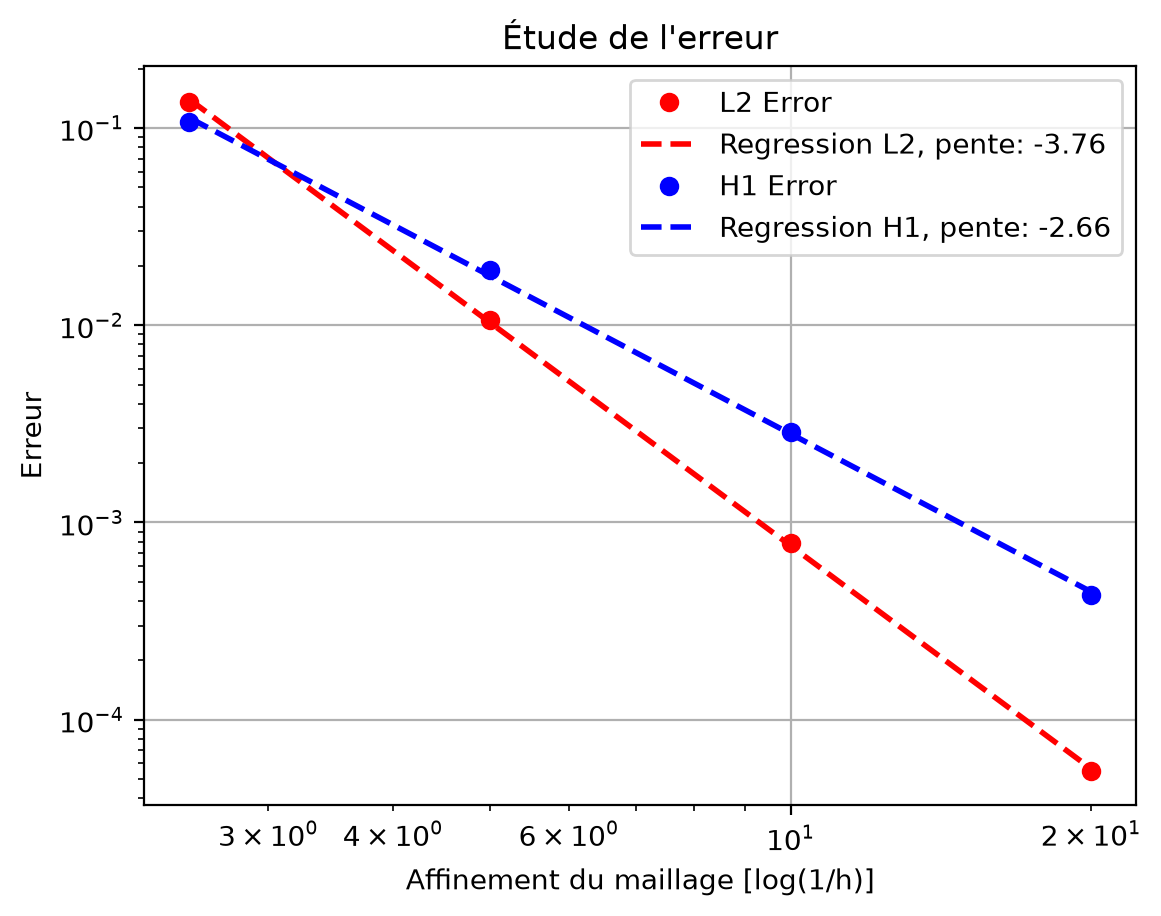

0

In [19]:
plot_errors(L2_errors, H1_errors)

<hr width="50%" align="left">

<span style="color:green">__Réponse 2.6__</span> - Les pentes mesurées sont d'environ $3{,}7$ en norme $L^2$ et $2{,}6$ en semi-norme $H^1$ : l'erreur évolue comme dans le cas des conditions aux limites de Neumann, au moins en $h^3$ en norme $L^2$ et en $h^2$ en semi-norme $H^1$. La condition de Dirichlet est imposée *exactement* aux nœuds du bord par pseudo-élimination ($V_h^0\subset H^1_0(\Omega)$, approximation conforme), elle ne dégrade donc pas l'ordre de la méthode. L'explication est la même : lemme de Céa, $\Vert u-u_h\Vert_{H^1}\le C\inf_{v_h\in V_h^0}\Vert u-v_h\Vert_{H^1}\le C\Vert u-\pi_hu\Vert_{H^1}\le Ch^2$ (ici $\pi_hu\in V_h^0$ car $u$ est nulle au bord), puis un ordre de plus en norme $L^2$ par dualité.

<hr width="50%" align="left">

## Conditions de Dirichlet non homogènes

Nous considérons maintenant un problème de Poisson avec une condition de Dirichlet non homogène. Etant données $f\in L^2(\Omega)$ et $g\in C^0(\partial\Omega)$,
trouver $u \in H^1(\Omega)$ tel que 
$$
\left \{
\begin{aligned}
& u - \Delta u = f  & \text{ dans } \Omega,\\
& u = g & \text{ sur } \partial \Omega. 
\end{aligned}
\right.
\tag{$10$}
$$
Nous avons vu dans le cours que la formulation variationelle du problème $(7)$ s'écrit
$$
\begin{gathered}
\text{Trouver } u\in H^1(\Omega) \text{ avec } u_{|\partial\Omega} \text{ qui vérifie }\\
\forall v \in H_0^1(\Omega) \quad
\int_\Omega u v \operatorname{d}\!\Omega +
\int_\Omega \nabla u\cdot \nabla v \operatorname{d}\!\Omega = \int_\Omega f v \operatorname{d}\!\Omega,
\end{gathered}
\tag{$11$}
$$
et qu'elle est bien posée.

Il est possible d'étendre la méthode de pseudo-élimination à des conditions de Dirichlet non homogènes. Pour ce faire, en supposant que les nœuds de la frontières sont numérotés en dernier, il suffit de modifier la matrice et le second-membre issus de $(11)$ assemblés avec toutes les fonctions de base
$$
\begin{bmatrix}
\mathbb{A}_{II} & \mathbb{A}_{IB} \\
\mathbb{A}_{BI} & \mathbb{A}_{BB}
\end{bmatrix}
\begin{bmatrix}
\vec{U}_{I} \\
\vec{U}_{B} 
\end{bmatrix} =
\begin{bmatrix}
\vec{L}_{I} \\
\vec{L}_{B} 
\end{bmatrix}
$$
en imposant $\mathbb{A}_{BI}=0$, $\mathbb{A}_{BB}=\mathbb{I}$ et $\vec{L}_{B}=\vec g$ où $\vec g$ est le vecteur colonne composé des valeurs prises par la fonction $g$ aux nœuds $M_J$ du bord. On remarquera que l'on n'a __pas__ imposé $\mathbb{A}_{IB}=0$.

<span style="color:red"><strong>Question 2.7</strong></span> - Modifier la fonction <tt>elimine</tt> pour qu'elle puisse traiter la condition de Dirichlet non homogène par pseudo-élimination.

<span style="color:red"><strong>Question 2.8</strong></span> - Valider votre code en choisissant une solution de référence et $f$ et $g$ calculées en conséquence. Tracer les courbes de convergence comme à la question 2.6.

In [20]:
def elimine_non_homogene(A, L, mesh, dirichlet_bound, dirichlet_fct=None):
    """
    Effectue la pseudo-élimination sur la matrice A et le second membre L.

    Parameters
    ----------
    A : ndarray
        la matrice creuse du système linéaire

    L : ndarray
        le second membre du système linéaire

    mesh : Mesh
        le maillage

    dirichlet_bound : str
        nom du bord où l'on doit faire l'élimination

    dirichlet_fct : Callable[node, float] | None, optional (default None)
        fonction utilisée pour Dirichlet non homogène S -> u
        S est un noeud, c'est-à-dire un ndarray de taille 2 contenant les coordonnées du noeud
        retourne un float correspondant à la condition de Dirichlet imposée au bord

    Returns
    -------
    A_tilde la matrice modifiée (matrice sparse de taille nb_nodes x nb_nodes)
    L_tilde le second membre (vecteur de taille nb_nodes)
    """
    A_tilde = A.tolil()
    L_tilde = L.copy()

    nodes_indices_bord = mesh.domain_node_indices(domain_name= dirichlet_bound, element_type= 'line')
    rho = 1
    # Réponse 2.7 - début

    for i in nodes_indices_bord:
        A_tilde[i, :] = 0
        A_tilde[i, i] = rho

        if dirichlet_fct is not None:
            L_tilde[i] = rho * dirichlet_fct(mesh.nodes[i]) #dirichlet_fct est le g
        else:
            L_tilde[i] = 0

    # Réponse 2.7 - fin

    return A_tilde.tocsc(), L_tilde

INFORMATIONS DU MAILLAGE
nodes: 2965 nodes with 2 coordinates
domains:
  "Gamma": line, 100 elements, 3 nodes per element
  "Omega": triangle, 1432 elements, 6 nodes per element


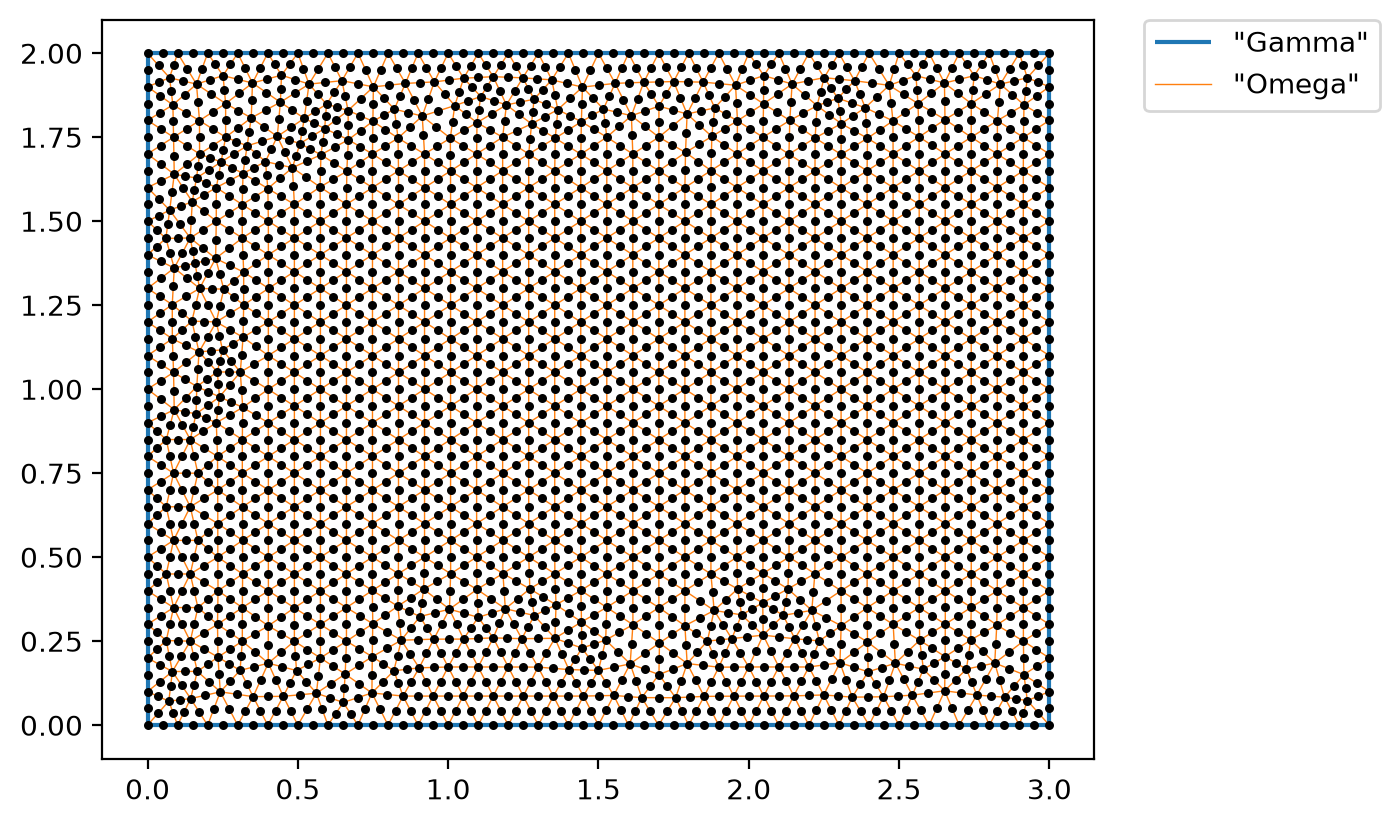

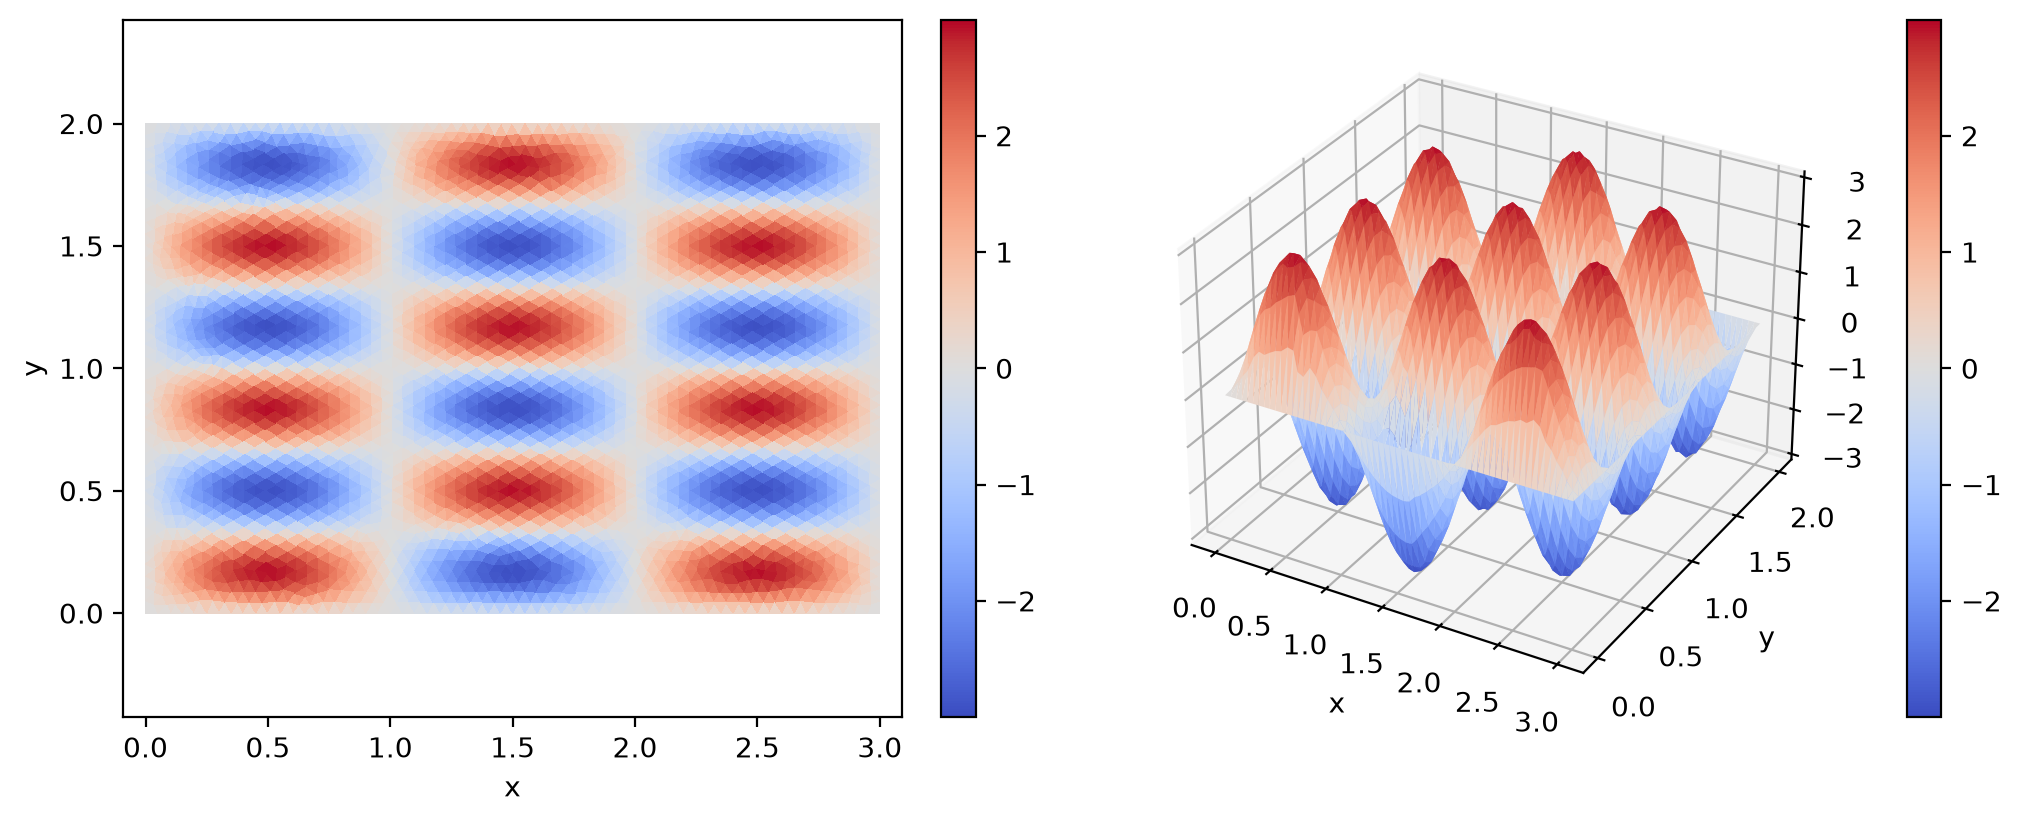

In [21]:
####################################################
# REPONSE QUESTION 2.8 (Tracé)
####################################################

# Nous avons choisit u =  3 * sin(pi * x) * sin(3*pi*y)

def u3_function(nodes):
    # Function qui define la fonction connue
    x, y = nodes[:, 0], nodes[:, 1]
    return 3 * np.sin(np.pi * x)*np.sin(3*np.pi*y)

def f3_function(nodes):
    # Fonction qui define le terme f
    x, y = nodes[:, 0], nodes[:, 1]
    return (3 + 30*np.pi**2) * np.sin(np.pi * x)*np.sin(3*np.pi*y)

def g3_function(node):
    # Fonction qui define le terme g (qui est egale a u sur les bords)
    x, y = node[0], node[1]
    return 3 * np.sin(np.pi * x)*np.sin(3*np.pi*y)

#definission du maillage
options = src.GmshOptions(element_order=2)
a, b = 3, 2
h = 0.1
mesh = src.rectangle((0, 0), (a, b), h, options)
print("INFORMATIONS DU MAILLAGE")
mesh.print_info()

fig, ax = plt.subplots()
src.plot2d_mesh(ax, mesh, show_legend=True, show_nodes=True, show_nodes_indices=False)

#solution du probleme avec conditions de Dirichlet non homogene
K3, M3 = mat_KM(mesh)
A3 = K3 + M3
L3 = vec_L(f3_function, M3, mesh)
A, L = elimine_non_homogene(A3, L3, mesh, 'Gamma', g3_function)
U = src.sparse_solve(A, L)

# Affichage de la solution
fig = plt.figure(figsize=(10, 4), layout="constrained")
axs = [fig.add_subplot(1, 2, 1), fig.add_subplot(1, 2, 2, projection="3d")]
for ax in axs:
    ax.axis("equal")
    ax.set_xlabel("x")
    ax.set_ylabel("y")

U_max = np.abs(U).max()
src.plot2d_fct_trimesh(
    ax=axs[0],
    values=U,
    mesh=mesh,
    tripcolor_kwargs={"cmap": "coolwarm", "vmin": -U_max, "vmax": U_max},
)
src.plot3d_fct_trimesh(
    ax=axs[1],
    values=U,
    mesh=mesh,
    trisurf_kwargs={"cmap": "coolwarm", "vmin": -U_max, "vmax": U_max},
)
plt.show()

In [22]:
####################################################
# REPONSE QUESTION 2.8 (convergence)
####################################################

def error_study_non_homogene(h_list, f, U_fct, g_fct, a, b):
    L2_errors = {}
    H1_errors = {}

    for h in h_list:
        options = src.GmshOptions(element_order=2)
        mesh = src.rectangle((0, 0), (a, b), h, options)

        K1, M1 = mat_KM(mesh)
        A1 = K1 + M1
        L1 = vec_L(f, M1, mesh)

        A, L = elimine_non_homogene(
            A1, L1, mesh, "Gamma", dirichlet_fct=g_fct
        )

        U = src.sparse_solve(A, L)
        U_exact = interpolate_in_nodes(U_fct, mesh.nodes)

        L2_errors[h] = calculate_L2_error(M1, U, U_exact)
        H1_errors[h] = calculate_H1_error(K1, U, U_exact)

    return L2_errors, H1_errors

#error study
h = np.array([0.4, 0.2, 0.1, 0.05])
L2_dict, H1_dict = error_study(h, f1, u1_function, 3, 2)
L2_errors, H1_errors = list(L2_dict.values()), list(H1_dict.values())

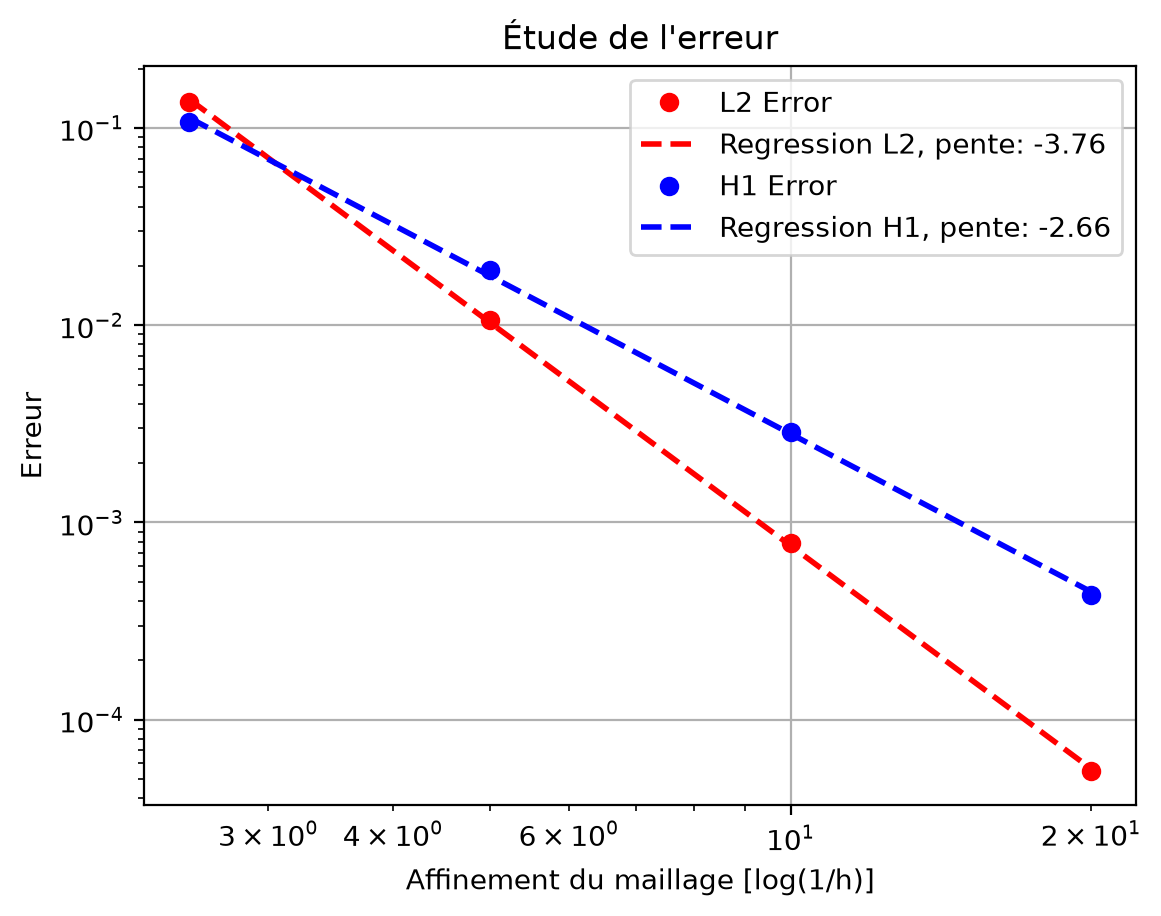

0

In [23]:
plot_errors(L2_errors, H1_errors)

<hr width="50%" align="left">

<span style="color:green">__Réponse 2.8__</span> - La solution approchée coïncide avec $g$ aux nœuds du bord (à la précision machine) et les pentes mesurées sont d'environ $3{,}7$ en norme $L^2$ et $2{,}6$ en semi-norme $H^1$ : même comportement que dans le cas homogène. Imposer $u_h(M_J)=g(M_J)$ aux nœuds du bord revient à chercher $u_h=u_h^0+r_h$ avec $u_h^0\in V_h^0$ et $r_h$ un relèvement discret de $\pi_hg$ ; le bloc $\mathbb{A}_{IB}$, que l'on ne modifie pas, fait passer la contribution $-\mathbb{A}_{IB}\,\vec g$ au second membre des équations des nœuds intérieurs. La matrice n'est plus symétrique, mais le solveur direct creux utilisé (LU) n'en a pas besoin.

<hr width="50%" align="left">

# Exercice 3 : Problème de Stokes

Nous allons à présent aborder le problème de Stokes.
Soit $\Omega$ un ouvert borné régulier de $\mathbb{R}^2$ à frontière polygonale et soit $\Gamma=\partial\Omega$.
La frontière $\Gamma$ est partitionnée en $\Gamma=\Gamma_D \cup \Gamma_N$ avec $\Gamma_D\neq\emptyset$ et $\Gamma_N\neq\emptyset$.
On impose une condition de Dirichlet sur la partie du bord $\Gamma_D$ et une condition de Neumann $\Gamma_N$.
On s'intéresse au calcul de la vitesse $\boldsymbol{u} \equiv \boldsymbol{u}(x,y)=(u_1(x,y),u_2(x,y))$ et de la pression $p\equiv p(x,y)$ solutions du problème de Stokes
$$
\begin{gathered}
\textrm{Trouver }
\boldsymbol{u}=(u_1,u_2)\in H^1(\Omega)\times H^1(\Omega)
\textrm{ et }
p\in L^2(\Omega)
\textrm{ tels que }\\
\left\lbrace
\begin{aligned}
&-\nu\Delta\boldsymbol{u} + \nabla p = 0, &\textrm{dans }\Omega,\\
&-\operatorname{div}\boldsymbol{u} = 0, &\textrm{dans }\Omega,\\
&\boldsymbol{u} = \boldsymbol{g}, &\textrm{sur }\Gamma_D,\\
&\nu\partial_{\boldsymbol{n}}\boldsymbol{u}-p\boldsymbol{n} = 0, &\textrm{sur }\Gamma_N.
\end{aligned}
\right.
\end{gathered}
\tag{$12$}
$$
Notons que les espaces fonctionnels $H^1(\Omega)$ et $L^2(\Omega)$ sont en réalité choisis une fois que la formulation variationnelle est déterminée.

Le paramètre $\nu$ est une constante qui représente la viscosité dynamique du fluide. La fonction $\boldsymbol{g}=(g_1,g_2)$ est une fonction donnée sur le bord $\Gamma_D$ supposée suffisamment régulière. Comme d'habitude, $\boldsymbol{n}=(n_1,n_2)$ est la normale unitaire extérieure à $\Gamma$.

Le problème $(12)$ peut se récrire composante par composante de la façon suivante
$$
\left\lbrace
\begin{aligned}
&-\nu\Delta u_1 + \partial_x p = 0, &\textrm{dans }\Omega,\\
&-\nu\Delta u_2 + \partial_y p = 0, &\textrm{dans }\Omega,\\
&-\partial_xu_1 - \partial_yu_2 = 0, &\textrm{dans }\Omega,\\
&u_1=g_1, &\textrm{sur }\Gamma_D,\\
&u_2=g_2, &\textrm{sur }\Gamma_D,\\
&\nu\partial_{\boldsymbol{n}} u_1-pn_1 = 0, &\textrm{sur }\Gamma_N,\\
&\nu\partial_{\boldsymbol{n}} u_2-pn_2 = 0, &\textrm{sur }\Gamma_N.
\end{aligned}
\right.
\tag{$13$}
$$

## Formulation variationnelle

<span style="color:red"><strong>Question 3.1</strong></span> - Montrer que la formulation variationnelle du problème $(12)$ s'écrit
$$
\begin{gathered}
\textrm{Trouver } \boldsymbol{u}=(u_1,u_2)\in H^1_{g_1,D}(\Omega)\times H^1_{g_2,D}(\Omega)
\textrm{ et } p\in L^2(\Omega) \textrm{ tels que} \\
    \left\lbrace
    \begin{aligned}
    &\nu \int_\Omega \nabla\boldsymbol{u}:\nabla\boldsymbol{v} \operatorname{d}\!\Omega
    - \int_\Omega p \operatorname{div}\boldsymbol{v} \operatorname{d}\!\Omega = 0,
    && \forall \boldsymbol{v}=(v_1,v_2)\in (H^1_{0,D}(\Omega))^2,\\
    &-\int_\Omega \operatorname{div}\boldsymbol{u}\;q \operatorname{d}\!\Omega = 0, 
    && \forall q\in L^2(\Omega).
    \end{aligned}
    \right.
\end{gathered}
\tag{$14$}
$$

Dans la formulation variationnelle, nous avons noté
$$ 
\nabla\boldsymbol{u}:\nabla\boldsymbol{v} = \nabla u_1\cdot\nabla v_1 + \nabla u_2\cdot\nabla v_2.
$$
Les espaces fonctionnels sont définis ainsi
$$
H^1_{\phi,D}(\Omega) = \Bigl\lbrace
u\in H^1(\Omega) \textrm{ tel que } u_{|\Gamma_D}=\phi
\Bigr\rbrace
\textrm{ pour } \phi\in\lbrace 0,g_1,g_2\rbrace.
$$

<div class="alert alert-block alert-info">
<strong>Indication</strong>

Multiplier la première équation de (13) par $v_1$ et intégrer par partie les deux
termes. Puis faire de même en multipliant la seconde équation de (13) par $v_2$.
</div>

<hr width="50%" align="left">

<span style="color:green">__Réponse 3.1__</span> - 

### Étape 1 : Multiplication par les fonctions tests $v_1$ et $v_2$

Les équations scalaires de la quantité de mouvement associées au problème (13) s'écrivent dans $\Omega$ :
$$-\nu \Delta u_1 + \frac{\partial p}{\partial x_1} = 0$$
$$-\nu \Delta u_2 + \frac{\partial p}{\partial x_2} = 0$$

Soient $v_1 \in H_{0,D}^1(\Omega)$ et $v_2 \in H_{0,D}^1(\Omega)$. En multipliant respectivement la première équation par $v_1$ et la seconde par $v_2$, on obtient :
$$-\nu \Delta u_1 v_1 + \frac{\partial p}{\partial x_1} v_1 = 0$$
$$-\nu \Delta u_2 v_2 + \frac{\partial p}{\partial x_2} v_2 = 0$$

---

### Étape 2 : Intégration sur le domaine $\Omega$

En intégrant chaque équation sur le domaine $\Omega$ :
$$\int_\Omega \left( -\nu \Delta u_1 v_1 + \frac{\partial p}{\partial x_1} v_1 \right) \mathrm{d}\Omega = 0$$
$$\int_\Omega \left( -\nu \Delta u_2 v_2 + \frac{\partial p}{\partial x_2} v_2 \right) \mathrm{d}\Omega = 0$$

---

### Étape 3 : Application de la formule de Green et réarrangement

En appliquant la formule de Green (intégration par parties en plusieurs dimensions) à chacun des termes de la première équation ($i = 1$) :
$$-\nu \int_\Omega \Delta u_1 v_1 \, \mathrm{d}\Omega = \nu \int_\Omega \nabla u_1 \cdot \nabla v_1 \, \mathrm{d}\Omega - \nu \int_{\partial\Omega} \frac{\partial u_1}{\partial n} v_1 \, \mathrm{d}\Gamma$$
$$\int_\Omega \frac{\partial p}{\partial x_1} v_1 \, \mathrm{d}\Omega = -\int_\Omega p \frac{\partial v_1}{\partial x_1} \, \mathrm{d}\Omega + \int_{\partial\Omega} p n_1 v_1 \, \mathrm{d}\Gamma$$

En regroupant les termes volumiques et surfaciques :
$$\nu \int_\Omega \nabla u_1 \cdot \nabla v_1 \, \mathrm{d}\Omega - \int_\Omega p \frac{\partial v_1}{\partial x_1} \, \mathrm{d}\Omega + \int_{\partial\Omega} \left( -\nu \frac{\partial u_1}{\partial n} + p n_1 \right) v_1 \, \mathrm{d}\Gamma = 0$$

De la même manière, pour la seconde équation ($i = 2$) :
$$\nu \int_\Omega \nabla u_2 \cdot \nabla v_2 \, \mathrm{d}\Omega - \int_\Omega p \frac{\partial v_2}{\partial x_2} \, \mathrm{d}\Omega + \int_{\partial\Omega} \left( -\nu \frac{\partial u_2}{\partial n} + p n_2 \right) v_2 \, \mathrm{d}\Gamma = 0$$

---

### Étape 4 : Décomposition des intégrales de bord ($\Gamma_D$ et $\Gamma_N$)

La frontière totale du domaine se décompose en $\partial\Omega = \Gamma_D \cup \Gamma_N$. Pour chaque composante $i \in \{1, 2\}$, l'intégrale de bord se sépare ainsi :
$$\int_{\partial\Omega} \left( -\nu \frac{\partial u_i}{\partial n} + p n_i \right) v_i \, \mathrm{d}\Gamma = \int_{\Gamma_D} \left( -\nu \frac{\partial u_i}{\partial n} + p n_i \right) v_i \, \mathrm{d}\Gamma + \int_{\Gamma_N} \left( -\nu \frac{\partial u_i}{\partial n} + p n_i \right) v_i \, \mathrm{d}\Gamma$$

* **Sur la frontière de Dirichlet ($\Gamma_D$) :** Par définition de l'espace fonctionnel $v_i \in H_{0,D}^1(\Omega)$, la fonction test s'annule sur ce bord ($v_{i|\Gamma_D} = 0$). L'intégrale sur $\Gamma_D$ est donc nulle.
* **Sur la frontière de Neumann ($\Gamma_N$) :** D'après les conditions de bord définies dans (13), le terme de contrainte vérifie $-\nu \frac{\partial u_i}{\partial n} + p n_i = 0$ sur $\Gamma_N$. L'intégrale sur $\Gamma_N$ s'annule donc également.

Les deux intégrales de bord s'annulent complètement et les équations se réduisent aux termes volumiques :
$$\nu \int_\Omega \nabla u_1 \cdot \nabla v_1 \, \mathrm{d}\Omega - \int_\Omega p \frac{\partial v_1}{\partial x_1} \, \mathrm{d}\Omega = 0$$
$$\nu \int_\Omega \nabla u_2 \cdot \nabla v_2 \, \mathrm{d}\Omega - \int_\Omega p \frac{\partial v_2}{\partial x_2} \, \mathrm{d}\Omega = 0$$

---

### Étape 5 : Addition des équations et écriture vectorielle

En sommant membre à membre les équations pour $u_1$ et $u_2$ :
$$\nu \int_\Omega \left( \nabla u_1 \cdot \nabla v_1 + \nabla u_2 \cdot \nabla v_2 \right) \mathrm{d}\Omega - \int_\Omega p \left( \frac{\partial v_1}{\partial x_1} + \frac{\partial v_2}{\partial x_2} \right) \mathrm{d}\Omega = 0$$

En utilisant les définitions du produit doublement contracté et de la divergence :
$$\nabla \mathbf{u} : \nabla \mathbf{v} = \nabla u_1 \cdot \nabla v_1 + \nabla u_2 \cdot \nabla v_2$$
$$\operatorname{div} \mathbf{v} = \frac{\partial v_1}{\partial x_1} + \frac{\partial v_2}{\partial x_2}$$

On obtient l'équation vectorielle :
$$\nu \int_\Omega \nabla \mathbf{u} : \nabla \mathbf{v} \, \mathrm{d}\Omega - \int_\Omega p \operatorname{div} \mathbf{v} \, \mathrm{d}\Omega = 0, \quad \forall \mathbf{v} \in (H_{0,D}^1(\Omega))^2$$

---

### Étape 6 : Formulation variationnelle globale

Pour l'équation d'incompressibilité $\operatorname{div} \mathbf{u} = 0$, on multiplie par une fonction test $q \in L^2(\Omega)$ puis on intègre sur $\Omega$ :
$$-\int_\Omega \operatorname{div} \mathbf{u} \, q \, \mathrm{d}\Omega = 0, \quad \forall q \in L^2(\Omega)$$

En associant les espaces fonctionnels définis pour $\mathbf{u} = (u_1, u_2) \in H_{g_1,D}^1(\Omega) \times H_{g_2,D}^1(\Omega)$, la formulation variationnelle du problème (12) s'écrit :

Trouver $\mathbf{u} = (u_1, u_2) \in H_{g_1,D}^1(\Omega) \times H_{g_2,D}^1(\Omega)$ et $p \in L^2(\Omega)$ tels que :
$$
\begin{cases}
\nu \displaystyle\int_\Omega \nabla \mathbf{u} : \nabla \mathbf{v} \, \mathrm{d}\Omega - \int_\Omega p \operatorname{div} \mathbf{v} \, \mathrm{d}\Omega = 0, & \forall \mathbf{v} = (v_1, v_2) \in (H_{0,D}^1(\Omega))^2, \\
-\displaystyle\int_\Omega \operatorname{div} \mathbf{u} \, q \, \mathrm{d}\Omega = 0, & \forall q \in L^2(\Omega).
\end{cases}
$$

On ne peut pas utiliser le théorème de Lax-Milgram, mais on pourrait démontrer que
la formulation variationnelle $(14)$ est bien posée. Si cette question théorique vous intéresse,
vous pouvez la traiter en justifiant.

## Maillage

<span style="color:red"><strong>Question 3.2</strong></span> - Utiliser la fonction <tt>src.polygon</tt> pour créer un maillage d'ordre 2 du domaine $\Omega=]0,3[\times]0,2[$ avec
\begin{align}
    \Gamma_D &= [0,3]\times\lbrace0\rbrace \cup \lbrace0\rbrace\times[0,2] \cup [0,3]\times\lbrace2\rbrace,
    \\
    \Gamma_N &= \lbrace3\rbrace\times]0,2[.
\end{align}
Afficher ensuite le maillage et vérifier que les différentes parties du bord sont bien traitées.

nodes: 525 nodes with 2 coordinates
domains:
  "Vertices": point, 4 elements, 1 nodes per element
  "Gamma": line, 40 elements, 3 nodes per element
  "Omega": triangle, 242 elements, 6 nodes per element


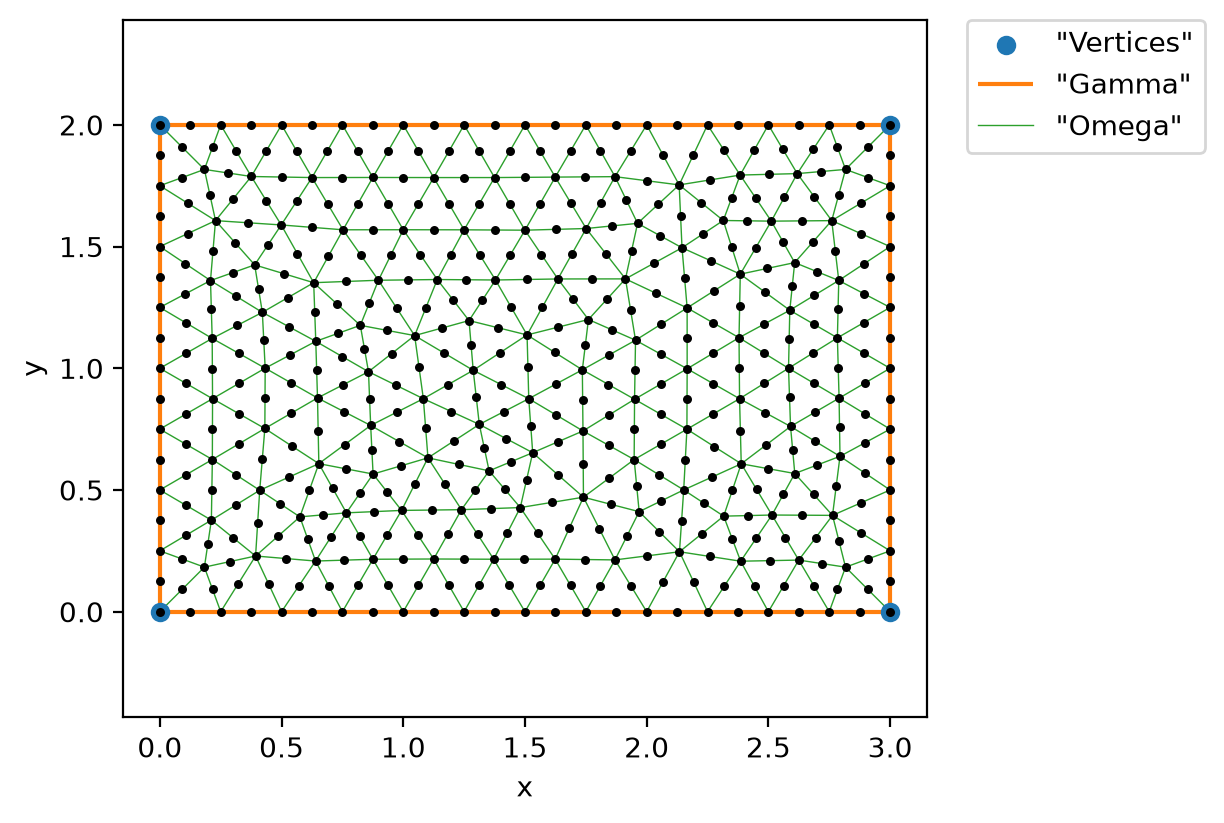

In [24]:
options = src.GmshOptions(element_order=2)
a, b = 3, 2
mesh_size = 0.25
mesh = src.polygon(point_coords= [(0, 0), (a, 0), (a, b), (0, b)], mesh_size= mesh_size, gmsh_options= options)
mesh.print_info()

fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
ax.axis("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
src.plot2d_mesh(ax, mesh, show_nodes_indices=False, show_nodes=True)
plt.show()

## Discrétisation

Nous discrétisons _chaque composante de la vitesse_ par des éléments finis $P^2$ et la _pression_ par des éléments finis $P^1$. Cette paire d'éléments finis est notée $P^2{-}P^1$ et s'appelle _éléments finis de Taylor-Hood_.

Si l'on suppose que les sommets des triangles sont numérotés de $1$ à $N_s$ et les milieux des arêtes de $N_s{+}1$ à $N$, le vecteur $\vec U$ des inconnues du système linéaire issu de la discrétisation de $(14)$ est un vecteur de $\mathbb{R}^{2N+N_s}$ qui s'écrit
$$
\vec U = [
u_{1,h}(M_1),\ldots,u_{1,h}(M_N),
u_{2,h}(M_1),\ldots,u_{2,h}(M_N),
p_h(M_1), \ldots, p_h(M_{N_s})
]^T,
$$
constitué des inconnues relatives à la première composante de la vitesse, puis à la seconde composante de la vitesse, puis à la pression. La matrice du système linéaire peut alors s’écrire par blocs sous la forme
$$
\mathbb{A} = \begin{bmatrix}
\nu\mathbb{K} & 0 & \mathbb{E} \\
0 & \nu\mathbb{K} & \mathbb{F} \\
\mathbb{G} & \mathbb{H} & 0
\end{bmatrix} \in \mathbb{R}^{(2N+N_s)\times(2N+N_s)}
$$
où
- les deux blocs $\nu\mathbb{K}\in\mathbb{R}^{N\times N}$ contiennent les contributions issues de la discrétisation des termes $\nu\int_\Omega \nabla u_1\cdot\nabla v_1\operatorname{d}\!\Omega$ et $\nu\int_\Omega \nabla u_2\cdot\nabla v_2\operatorname{d}\!\Omega$. En d'autres termes, on a
  $$ \mathbb{K}_{IJ} = \int_\Omega \nabla w_J\cdot\nabla w_I \operatorname{d}\!\Omega ,$$
  avec $(w_I)_{I=1,N}$ les fonctions de base $P^2$ utilisées dans les parties précédentes ;
- le bloc rectangulaire $\mathbb{E}\in\mathbb{R}^{N\times N_s}$ contient les contributions issues de la discrétisation du terme $-\int_\Omega p\partial_x v_1\operatorname{d}\!\Omega$, soit
  $$ \mathbb{E}_{I\tilde J} = -\int_\Omega \tilde w_{\tilde J} \frac{\partial w_I}{\partial x} \operatorname{d}\!\Omega,$$
  avec $(\tilde w_{\tilde J})_{\tilde J=1,N_s}$ les fonctions de base $P^1$ utilisées dans le TP1 ;
- le bloc rectangulaire $\mathbb{F}\in\mathbb{R}^{N\times N_s}$ contient les contributions issues de la discrétisation du terme $-\int_\Omega p\partial_y v_2\operatorname{d}\!\Omega$, à savoir
  $$ \mathbb{F}_{I\tilde J} = -\int_\Omega \tilde w_{\tilde J} \frac{\partial w_I}{\partial y} \operatorname{d}\!\Omega.$$

<span style="color:red"><strong>Question 3.3</strong></span> - De la discrétisation de quels termes les blocs rectangulaires $\mathbb{G}\in\mathbb{R}^{N_s\times N}$ et $\mathbb{H}\in\mathbb{R}^{N_s\times N}$ sont-ils issus ?
Exprimer $\mathbb{G}$ et $\mathbb{H}$ en fonction de $\mathbb{E}$ et $\mathbb{F}$.

<hr width="50%" align="left">

<span style="color:green">__Réponse 3.3__</span> - 

### 1. Origine des blocs $\mathbb{G}$ et $\mathbb{H}$

Les blocs $\mathbb{G}$ et $\mathbb{H}$ proviennent de la discrétisation de l'équation de continuité (incompressibilité) sous sa forme variationnelle :
$$-\int_\Omega \operatorname{div}(\mathbf{u}) \, q \, \mathrm{d}\Omega = 0, \quad \forall q \in L^2(\Omega)$$

En développant la divergence de la vitesse $\operatorname{div}(\mathbf{u}) = \frac{\partial u_1}{\partial x} + \frac{\partial u_2}{\partial y}$, l'intégrale se sépare en deux termes :
$$-\int_\Omega \frac{\partial u_1}{\partial x} q \, \mathrm{d}\Omega - \int_\Omega \frac{\partial u_2}{\partial y} q \, \mathrm{d}\Omega = 0$$

Ainsi :
* Le bloc rectangulaire $\mathbb{G} \in \mathbb{R}^{N_s \times N}$ provient de la discrétisation du terme $-\int_\Omega \frac{\partial u_1}{\partial x} q \, \mathrm{d}\Omega$.
* Le bloc rectangulaire $\mathbb{H} \in \mathbb{R}^{N_s \times N}$ provient de la discrétisation du terme $-\int_\Omega \frac{\partial u_2}{\partial y} q \, \mathrm{d}\Omega$.

---

### 2. Discrétisation par éléments finis

On exprime la fonction test de pression $q$ dans la base $P^1$ des fonctions de forme $(\tilde{w}_{\tilde{I}})_{\tilde{I}=1, N_s}$, et les composantes de la vitesse $u_1, u_2$ dans la base $P^2$ des fonctions de forme $(w_J)_{J=1, N}$ :
$$q(x,y) = \tilde{w}_{\tilde{I}}(x,y)$$
$$u_1(x,y) = \sum_{J=1}^N U_{1,J} w_J(x,y), \quad u_2(x,y) = \sum_{J=1}^N U_{2,J} w_J(x,y)$$

---

### 3. Définitions des coefficients $\mathbb{G}_{\tilde{I} J}$ et $\mathbb{H}_{\tilde{I} J}$

En injectant ces décompositions dans les deux intégrales volumiques pour chaque ligne $\tilde{I} \in \{1, \dots, N_s\}$ et chaque colonne $J \in \{1, \dots, N\}$, on définit les coefficients élémentaires :
$$\mathbb{G}_{\tilde{I} J} = -\int_\Omega \tilde{w}_{\tilde{I}} \frac{\partial w_J}{\partial x} \, \mathrm{d}\Omega$$
$$\mathbb{H}_{\tilde{I} J} = -\int_\Omega \tilde{w}_{\tilde{I}} \frac{\partial w_J}{\partial y} \, \mathrm{d}\Omega$$
A
---

### 4. Expression de $\mathbb{G}$ et $\mathbb{H}$ en fonction de $\mathbb{E}$ et $\mathbb{F}$

Rappelons les définitions des coefficients des matrices $\mathbb{E} \in \mathbb{R}^{N \times N_s}$ et $\mathbb{F} \in \mathbb{R}^{N \times N_s}$ :
$$\mathbb{E}_{I \tilde{J}} = -\int_\Omega \tilde{w}_{\tilde{J}} \frac{\partial w_I}{\partial x} \, \mathrm{d}\Omega$$
$$\mathbb{F}_{I \tilde{J}} = -\int_\Omega \tilde{w}_{\tilde{J}} \frac{\partial w_I}{\partial y} \, \mathrm{d}\Omega$$

En comparant terme à terme, on remarque que les indices des fonctions de base de pression $\tilde{w}$ et de vitesse $w$ sont permutés :
$$\mathbb{G}_{\tilde{I} J} = \mathbb{E}_{J \tilde{I}} \implies \mathbb{G} = \mathbb{E}^T$$
$$\mathbb{H}_{\tilde{I} J} = \mathbb{F}_{J \tilde{I}} \implies \mathbb{H} = \mathbb{F}^T$$

## Matrices élémentaires

<span style="color:red"><strong>Question 3.4</strong></span> - Compléter les deux fonctions <tt>elem_mat_E_p2p1</tt> et <tt>elem_mat_F_p2p1</tt> qui à partir des coordonnées des 3 sommets d’un triangle $T_\ell$ donnent respectivement les matrices élémentaires $\mathbb{E}^\ell\in\mathbb{R}^{6\times3}$ et $\mathbb{F}^\ell\in\mathbb{R}^{6\times3}$. On pourra utiliser des formules de quadrature adaptées.

In [25]:
def elem_mat_E_p2p1(S1, S2, S3, tol=1e-8):
    """
    Calcul la matrice de couplage elementaire en x en P2-P1.

    Parameters
    ----------
    S1, S2, S3 : les 2 coordonnees des 3 sommets du triangle (vecteurs reels 1x2)

    Returns
    -------
    matrice de couplage elementaire en x (matrice de taille 6x3)
    """
    x1, y1 = S1
    x2, y2 = S2
    x3, y3 = S3
    D = (x2 - x1) * (y3 - y1) - (y2 - y1) * (x3 - x1)

    Bl = np.array([[x2 - x1, x3 - x1], [y2 - y1, y3 - y1]])
    inv_BlT = np.linalg.inv(Bl.T)
    E_elem = np.zeros((6, 3))

    for i in range(6):
        for j in range(3):
            sumq = 0
            for q in range(len(quad_p2.weight)):
                xq, yq = quad_p2.nodes[q]
                grad_w_hat = grad_w_hat_p2(xq, yq)
                w_p1 = w_hat_p1(xq, yq)
                grad_w_x = (inv_BlT @ grad_w_hat[i])[0]
                sumq += quad_p2.weight[q] * w_p1[j] * grad_w_x
            E_elem[i, j] = -abs(D) * sumq

    return E_elem

In [26]:
def elem_mat_F_p2p1(S1, S2, S3, tol=1e-8):
    """
    Calcul la matrice de couplage elementaire en y en P2-P1.

    Parameters
    ----------
    S1, S2, S3 : les 2 coordonnees des 3 sommets du triangle (vecteurs reels 1x2)

    Returns
    -------
    matrice de couplage elementaire en y (matrice de taille 6x3)
    """
    x1, y1 = S1
    x2, y2 = S2
    x3, y3 = S3
    D = (x2 - x1) * (y3 - y1) - (y2 - y1) * (x3 - x1)

    Bl = np.array([[x2 - x1, x3 - x1], [y2 - y1, y3 - y1]])
    inv_BlT = np.linalg.inv(Bl.T)
    F_elem = np.zeros((6, 3))

    for i in range(6):
        for j in range(3):
            sumq = 0
            for q in range(len(quad_p2.weight)):
                xq, yq = quad_p2.nodes[q]
                grad_w_hat = grad_w_hat_p2(xq, yq)
                w_p1 = w_hat_p1(xq, yq)
                grad_w_y = (inv_BlT @ grad_w_hat[i])[1]
                sumq += quad_p2.weight[q] * w_p1[j] * grad_w_y
            F_elem[i, j] = -abs(D) * sumq

    return F_elem

## Assemblage de la matrice

<span style="color:red"><strong>Question 3.5</strong></span> - Complétez la fonction <tt>mat_A_Stokes</tt> qui assemble par blocs et retourne la matrice $\mathbb{A}$ de Stokes avant la pseudo-élimination.

<div class="alert alert-block alert-info">
<strong>Remarque</strong>

pour l’assemblage des blocs rectangulaires $P^2{−}P^1$, faire attention au fait que
dans <tt>mesh.nodes</tt> les sommets ne sont pas numérotés avant les milieux. Pour déterminer
les sommets parmi les nœuds, nous utilisons la structure <tt>mesh.triangles</tt> donnée par
<tt>gmsh</tt> : dans un triangle, les sommets sont les 3 premiers éléments et les milieux des
arêtes sont les 3 suivants.<br>
Vous pourrez ainsi utiliser la fonction <tt>numerotation_sommets</tt> qui vous indique une
numérotation des sommets dans le maillage. Des exemples d'utilisation sont données.
</div>

In [27]:
def numerotation_sommets_noeuds(mesh):
    r"""
    Propose une numérotation des sommets d'un maillage

    Dans le cas où le maillage d'entrée 'mesh' contient Ns sommets parmi N noeuds,
    les sommets ont un indice entre 0 et Ns-1 (numérotation d'un maillage d'ordre 1)
    et un indice entre 0 et N-1 (numérotation du noeud dans le maillage d'ordre >= 1)

    La fonction retourne deux tableaux
    - indN_to_indS de taille N (nombre de noeuds) et
    - indS_to_indN de taille Ns (nombre de sommets)
    permettant de faire la correspondance noeuds - sommets


    Exemple

    7 ----1---- 0    0 --------- 1
    | \         |    | \         |
    |   \       |    |   \       |
    8     6     3    |     \     |
    |       \   |    |       \   |
    |         \ |    |         \ |
    2 ----4---- 5    2 --------- 3

    indN_to_indS = [ 1 -1  2 -1 -1  3 -1  0 -1]
    indS_to_indN = [ 7  0  2  5]

    Parameters
    ----------

    mesh : Mesh
        le maillage

    Returns
    -------

    indN_to_indS : ndarray
        les indices des sommets

    indS_to_indN : ndarray (taille Ns)
        le numéro des sommets dans la numérotation des noeuds

    Example
    -------

    >>> options = src.GmshOptions(
            element_order=2
        )
    >>> mesh = src.rectangle((0, 0), (1, 1), 0.25, options)
    >>> indN_to_indS, indS_to_indN = numerotation_sommets(mesh)
    >>> print(indN_to_indS)

            [ 0  1  2  3  4 -1 -1  5 -1 -1  6 -1 -1  7 -1 -1  8  9 10 11 -1 -1 -1 -1
             -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1]

    >>> print(indS_to_indN)

            [ 0  1  2  3  4  7 10 13 16 17 18 19]

    """
    nb_nodes = mesh.nb_nodes  # nombre de noeuds dans le maillage
    triangles = mesh.domains["Omega"]["triangle"]  # les triangles du maillage
    indS_to_indN = np.unique(triangles[:, :3])  # les sommets des triangles
    nb_vertices = len(indS_to_indN)  # nombre de sommets dans le maillage
    indN_to_indS = np.full( nb_nodes, -1, dtype=int)  # ndarray de taille nb_nodes rempli de -1
    indN_to_indS[indS_to_indN] = np.arange(nb_vertices)  # puis on indique la correspondance
    
    return indN_to_indS, indS_to_indN

p2_to_p1: [ 0  1  2  3  4 -1 -1  5 -1 -1  6 -1 -1  7 -1 -1  8  9 10 11 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1]
vertex_indices: [ 0  1  2  3  4  7 10 13 16 17 18 19]
List of (node_index, vertex_index): [(0, 0), (1, 1), (2, 2), (3, 3), (4, 4), (7, 5), (10, 6), (13, 7), (16, 8), (17, 9), (18, 10), (19, 11)]


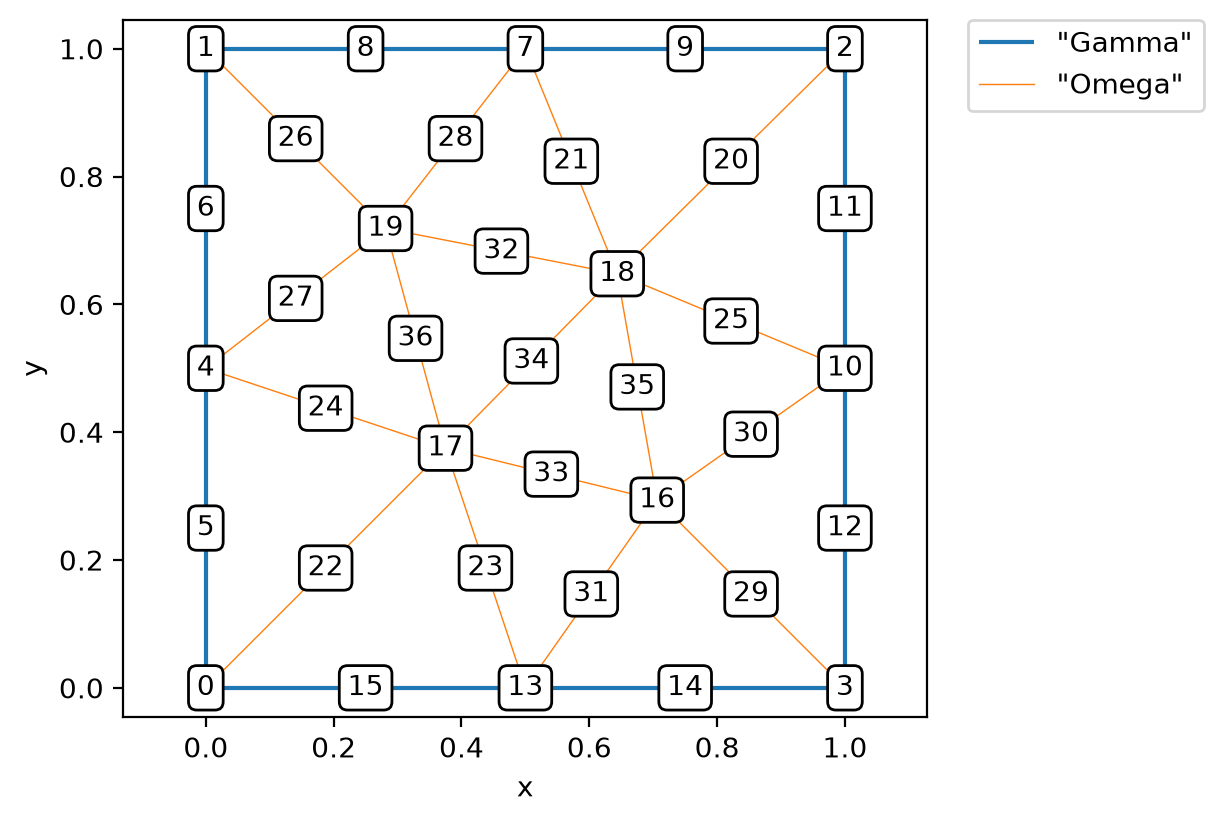

In [28]:
options = src.GmshOptions(element_order=2)
mesh = src.rectangle((0, 0), (1, 1), 0.5, options)
p2_to_p1, vertex_indices = numerotation_sommets_noeuds(mesh)
print("p2_to_p1:", p2_to_p1)
print("vertex_indices:", vertex_indices)
print("List of (node_index, vertex_index):", [(k, int(p22p1k)) for k, p22p1k in enumerate(p2_to_p1) if p22p1k != -1])

fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
ax.axis("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
src.plot2d_mesh(ax, mesh, show_nodes_indices=True, show_nodes=True)
plt.show()

In [29]:
def mat_A_Stokes(mesh, nu):
    """
    Calcul la matrice du problème de Stokes en P2-P1 Taylor-Hood.

    Parameters
    ----------
    mesh : Mesh
        le maillage

    Returns
    -------
    A la matrice de Stokes (matrice sparse de taille (2nb_nodes_P1+nb_nodes_P1) x (2nb_nodes_P1+nb_nodes_P1))
    """
    nb_nodes = mesh.nb_nodes  # nombre de noeuds dans le maillage
    triangles = mesh.domains["Omega"]["triangle"]  # les triangles du maillage

    # Les tableaux indN_to_indS et indS_to_indN permettent de passer de la numérotation des noeuds à celle des sommets
    indN_to_indS, indS_to_indN = numerotation_sommets_noeuds(mesh)
    nb_vertices = len(indS_to_indN)  # nombre de sommets dans le maillage
    size = 2 * nb_nodes + nb_vertices

    K = sp.dok_array((nb_nodes, nb_nodes), dtype=float)
    E = sp.dok_array((nb_nodes, nb_vertices), dtype=float)
    F = sp.dok_array((nb_nodes, nb_vertices), dtype=float)

    # Réponse 3.5 - début
    for k in range(mesh.nb_elements("Omega", "triangle")):
            triangle = triangles[k, :] #list avec les 3 indices des noeuds
    
            # Coordonnées des sommets du triangles
            nS1, nS2, nS3 = triangle[0], triangle[1], triangle[2] 
            S1, S2, S3 = mesh.nodes[nS1], mesh.nodes[nS2], mesh.nodes[nS3]
    
            K_elem = elem_mat_K_p2(S1, S2, S3) #6x6
            E_elem = elem_mat_E_p2p1(S1, S2, S3) #6x3
            F_elem = elem_mat_F_p2p1(S1, S2, S3) #6x3

            vertices = indN_to_indS[triangle[:3]] 
    
            for i in range(6):
                I = triangle[i]

                for j in range(6):
                    J = triangle[j]
                    K[I, J] += K_elem[i, j]

                for j in range(3):
                    J = vertices[j]
                    E[I, J] += E_elem[i, j]
                    F[I, J] += F_elem[i, j]

    K = K.tocsc()
    E = E.tocsc()
    F = F.tocsc()

    # Réponse 3.5 - fin
    A = sp.bmat(
        [
            [nu * K, None, E],
            [None, nu * K, F],
            [E.T, F.T, None],
        ],
        format="lil",
    )
    return A

<span style="color:red"><strong>Question 3.6</strong></span> - Complétez la fonction <tt>elimine_Stokes</tt> qui retourne la matrice $\mathbb{A}$ et le vecteur second-membre $\vec L$ modifiés après la méthode de pseudo-élimination. Vous prendrez soin de ne faire la pseudo-élimination que sur la partie $\Gamma_D$ du bord mais sur les deux composantes de la vitesse.

In [30]:
def elimine_Stokes(A, L, mesh, noeuds_dirichlet, dirichlet_fct=None):
    """
    Effectue la pseudo-élimination sur la matrice A et le second membre L.

    Parameters
    ----------
    A : ndarray
        la matrice creuse du système linéaire pour le problème de Stokes

    L : ndarray
        le second membre du système linéaire pour le problème de Stokes

    mesh : Mesh
        le maillage

    noeuds_dirichlet : list
        list avec noeuds sur lesquelles on doit faire l'élimination

    dirichlet_fct : Callable[node, tuple[float, float]] | None, optional (default None)
        fonction utilisée pour Dirichlet non homogène S -> (ux,uy)
        S est un noeud, c'est-à-dire un ndarray de taille 2 contenant les coordonnées du noeud
        retourne deux floats correspondant aux deux coordonnées de la vitesse imposée au bord

    Returns
    -------
    A_tilde la matrice modifiée (matrice sparse de taille (2N + Ns)²)
    L_tilde le second membre (vecteur de taille (2N + Ns))
    """

    A_tilde = A.tolil()
    L_tilde = L.copy()
    nb_nodes = mesh.nb_nodes  # nombre de noeuds dans le maillage

    # Réponse 3.6 - début
    rho = 1

    #loop sur les noeuds de condition de Dirichlet
    
    for i in noeuds_dirichlet:

        if dirichlet_fct is not None:
            gx, gy = dirichlet_fct(mesh.nodes[i])
        else:
            gx, gy = 0.0, 0.0

        A_tilde[i, :] = 0
        A_tilde[i, i] = rho
        A_tilde[nb_nodes + i, :] = 0
        A_tilde[nb_nodes + i, nb_nodes + i] = rho

        L_tilde[i] = rho * gx
        L_tilde[nb_nodes + i] = rho * gy

    # Réponse 3.6 - fin

    return A_tilde.tocsc(), L_tilde

## Applications numériques

<span style="color:red"><strong>Question 3.7</strong></span> - On veut vérifier que le code calcule une solution approchée $(u_{1h}, u_{2h}, p_h)$ correcte.
On pourra utiliser comme solution de référence un écoulement de Poiseuille dans un tube.
Afficher la solution approchée, en particulier afficher la vitesse comme un champ vectoriel 
sous forme de flèches à l’aide de la fonction <tt>quiver</tt> du module <tt>matplotlib</tt>.
Ensuite représenter, dans trois graphiques séparés, les différences $u_1−u_{1h}$ , 
$u_2−u_{2h}$ et $p−p_h$ dans le domaine de calcul, pour comparer chaque composante de la 
solution exacte et de la solution approchée. Discuter le résultat.

On a consideré une tube avec le domain $\Omega = [0, L_x] \times [0, H]$ avec un gradient de pression G. La solution analytique de Poiseuille est:

$u_1 = \frac{G}{2\nu}y(H-y)$   ,    $u_2 = 0$   ,   $ p = G(L_x)- x $

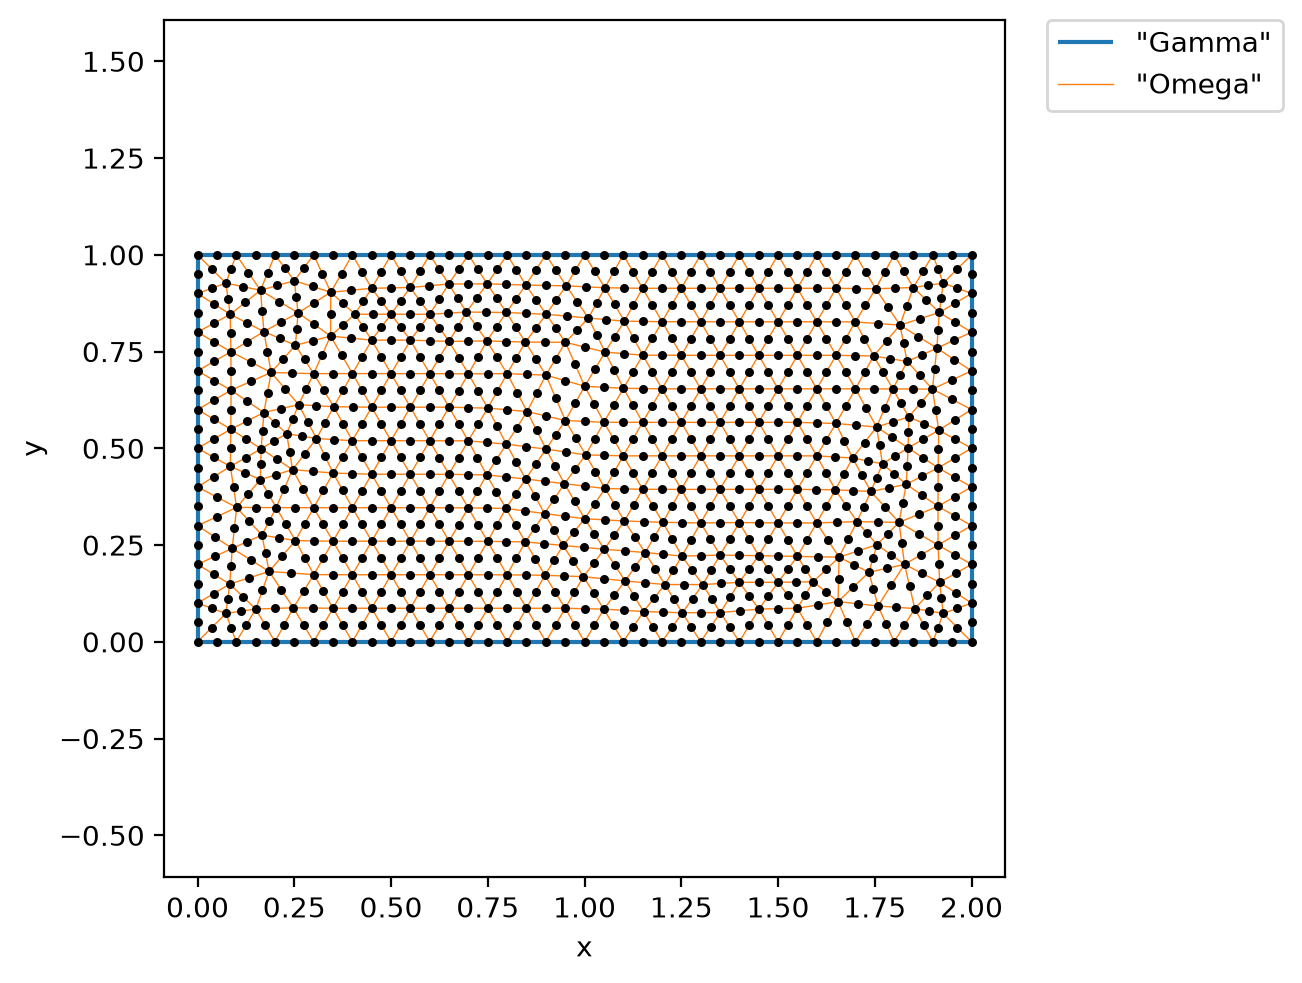

101 noeuds Dirichlet, 19 noeuds Neumann


In [31]:
##########################################################################
# Poiseuille
##########################################################################

#parametres du maillage
nu, G = 1.0, 1.0
Lx, H = 2.0, 1.0
tol = 1e-10
options = src.GmshOptions(element_order=2)
mesh = src.rectangle((0, 0), (Lx, H), 0.1, options)


def plot_mesh(mesh, show_nodes_indices= False):

    fig, ax = plt.subplots(layout="constrained")
    ax.axis("equal")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    src.plot2d_mesh(ax, mesh, show_nodes_indices= show_nodes_indices, show_nodes=True)
    plt.show()
    return fig, ax

plot_mesh(mesh)

# solution exacte
def u1_ex(x, y): return G / (2 * nu) * y * (H - y)
def p_ex(x, y):  return G * (Lx - x)
def g(S):        return (u1_ex(S[0], S[1]), 0.0)

N = mesh.nb_nodes
indN_to_indS, indS_to_indN = numerotation_sommets_noeuds(mesh)
Ns = len(indS_to_indN)  

#Assemblage de la matrice du probleme de Stokes
A = mat_A_Stokes(mesh, nu)
L = np.zeros(2 * N + Ns)
noeuds_Gamma = mesh.domain_node_indices(domain_name="Gamma", element_type="line")
xg, yg = mesh.nodes[noeuds_Gamma, 0], mesh.nodes[noeuds_Gamma, 1]

est_sortie = (abs(xg - Lx) < tol) & (yg > tol) & (yg < H - tol) #pour verifier si les noeuds sont en sortie

#Identifier les noeuds des conditions de bord
noeuds_D = noeuds_Gamma[~est_sortie] #Dirichlet
noeuds_N = noeuds_Gamma[est_sortie] #Neumann en sortie
print(len(noeuds_D), "noeuds Dirichlet,", len(noeuds_N), "noeuds Neumann")

#elimination des noeuds de bord avec des conditions de Dirichlet
A, L = elimine_Stokes(A, L, mesh, noeuds_D, g)

#solution du système
U = src.sparse_solve(A.tocsc(), L)
u1h, u2h, ph = U[:N], U[N:2*N], U[2*N:]


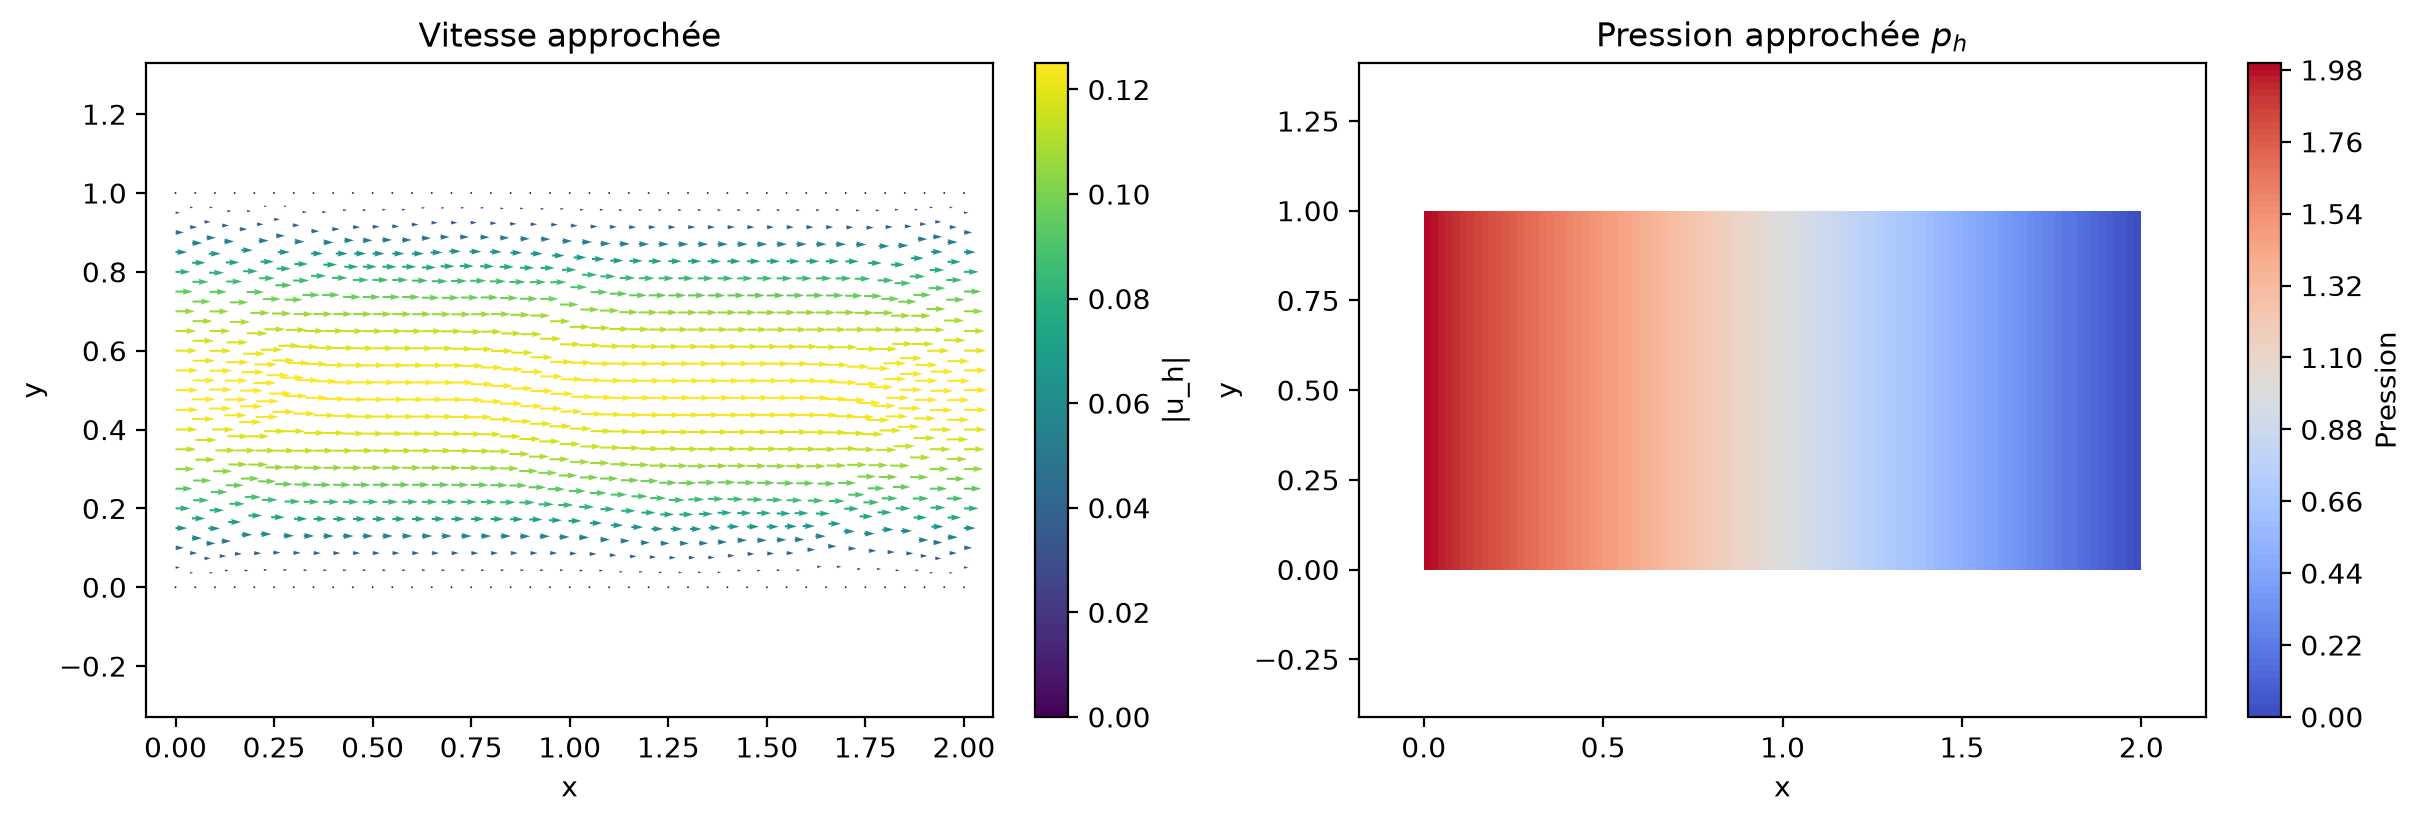

(<Figure size 1200x400 with 4 Axes>,
 array([<Axes: title={'center': 'Vitesse approchée'}, xlabel='x', ylabel='y'>,
        <Axes: title={'center': 'Pression approchée $p_h$'}, xlabel='x', ylabel='y'>],
       dtype=object))

In [32]:
def plot_stokes_solution(mesh, u1h, u2h, ph):
    """Trace le champ de vitesse et la pression approchée de Stokes."""

    _, indS_to_indN = numerotation_sommets_noeuds(mesh)

    # La pression P1 est defini que aux sommets des triangles
    vertices = mesh.nodes[indS_to_indN]
    triangles = mesh.domains["Omega"]["triangle"]
    tri_s = np.searchsorted(indS_to_indN, triangles[:, :3])
    triangulation = mtri.Triangulation(
        vertices[:, 0], vertices[:, 1], tri_s
    )

    fig, axs = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")

    # Vitesse P2
    x, y = mesh.nodes[:, 0], mesh.nodes[:, 1]
    speed = np.hypot(u1h, u2h)
    q = axs[0].quiver(x, y, u1h, u2h, speed, cmap="viridis")
    fig.colorbar(q, ax=axs[0], label="|u_h|")
    axs[0].set_title("Vitesse approchée")
    axs[0].set_xlabel("x")
    axs[0].set_ylabel("y")
    axs[0].axis("equal")

    # Pression P1
    contour = axs[1].tricontourf(triangulation, ph, levels=100, cmap="coolwarm")
    fig.colorbar(contour, ax=axs[1], label="Pression")
    axs[1].set_title("Pression approchée $p_h$")
    axs[1].set_xlabel("x")
    axs[1].set_ylabel("y")
    axs[1].axis("equal")

    plt.show()
    return fig, axs

plot_stokes_solution(mesh, u1h, u2h, ph)

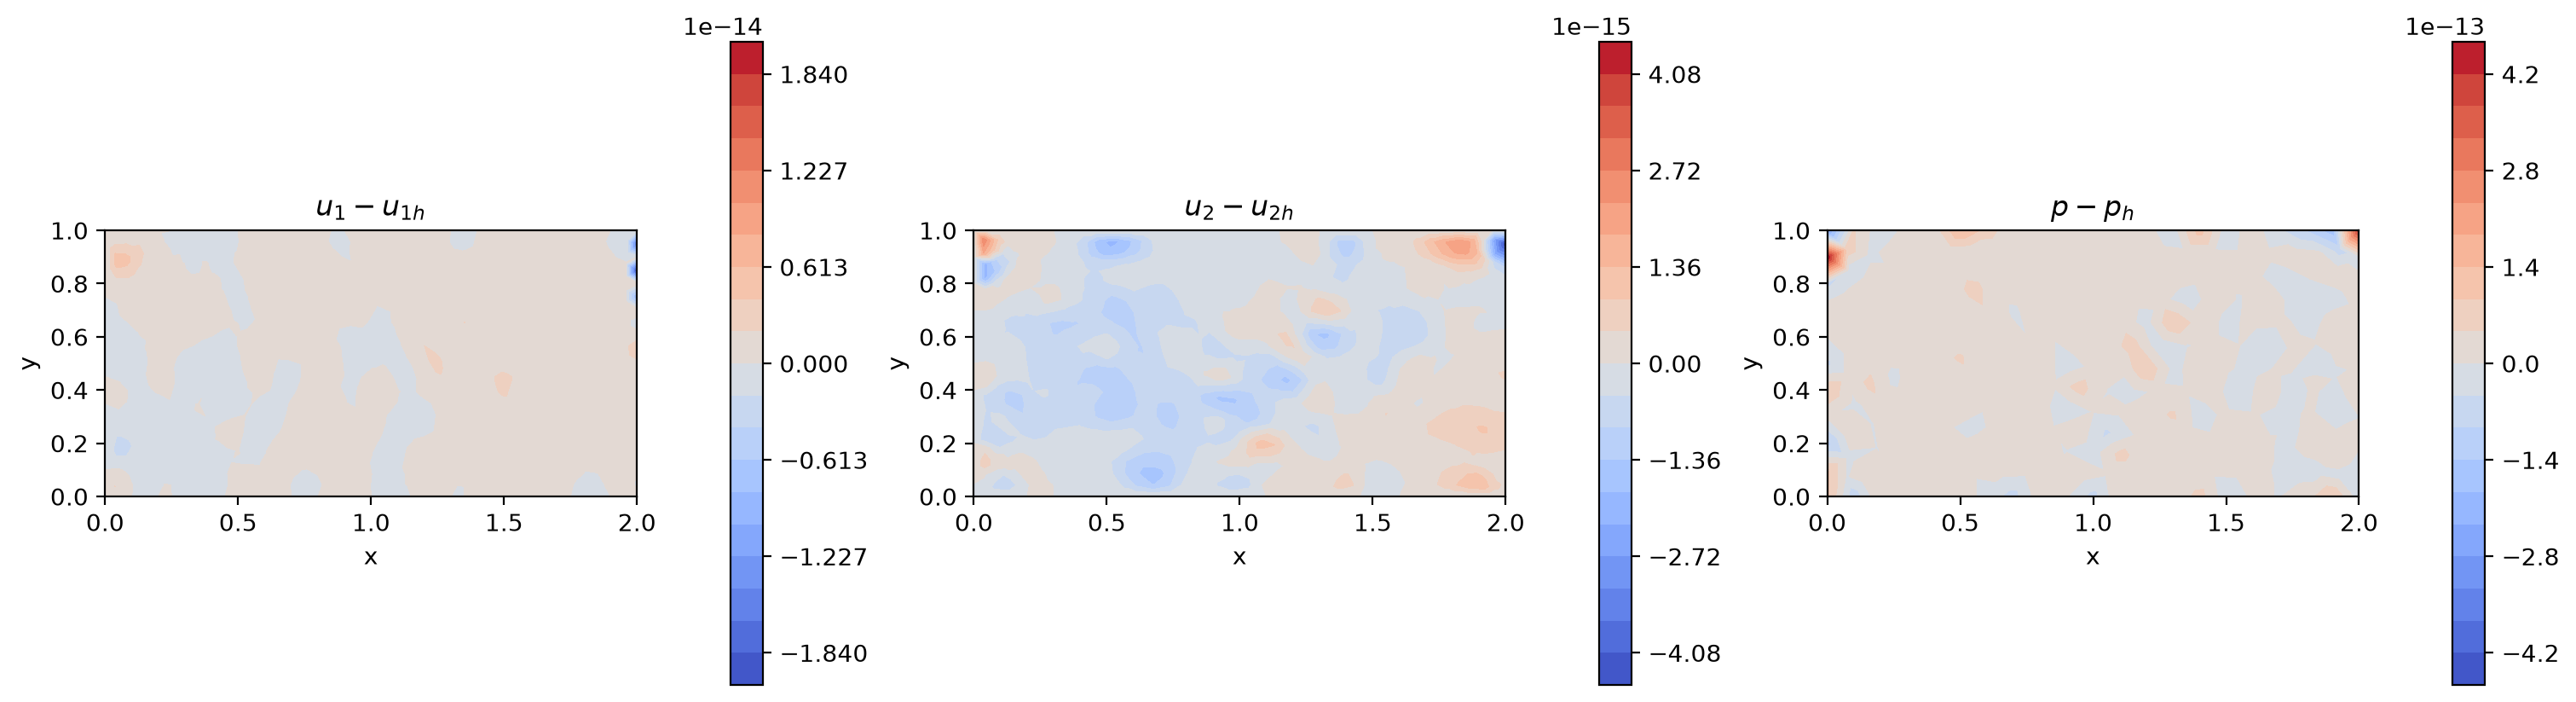

max |u1-u1h| = 2.044e-14
max |u2-u2h| = 4.533e-15
max |p-ph|   = 4.667e-13


(<Figure size 1500x400 with 6 Axes>,
 array([<Axes: title={'center': '$u_1-u_{1h}$'}, xlabel='x', ylabel='y'>,
        <Axes: title={'center': '$u_2-u_{2h}$'}, xlabel='x', ylabel='y'>,
        <Axes: title={'center': '$p-p_h$'}, xlabel='x', ylabel='y'>],
       dtype=object))

In [33]:
def plot_stokes_errors(mesh, u1h, u2h, ph, u1_exact, u2_exact, p_exact):
    """Trace les erreurs u1-u1h, u2-u2h et p-ph pour une solution d'un problème de Stokes."""

    triangles = mesh.domains["Omega"]["triangle"].astype(int)

    # Erreurs de la vitesse aux noeuds P2
    x_nodes, y_nodes = mesh.nodes[:, 0], mesh.nodes[:, 1]
    err_u1 = u1_exact(x_nodes, y_nodes) - u1h
    err_u2 = u2_exact(x_nodes, y_nodes) - u2h

    # Subdivision des elements P2 en outres 4 triangles internes.
    # L'ordre des noeuds dans un element P2 est: 3 sommets puis 3 points en millieux des aretes.
    p2_triangles = np.vstack([
        triangles[:, [0, 3, 5]],
        triangles[:, [3, 1, 4]],
        triangles[:, [5, 4, 2]],
        triangles[:, [3, 4, 5]],
    ])
    tri_velocity = mtri.Triangulation(x_nodes, y_nodes, p2_triangles)

    # Erreur pression P1
    indN_to_indS, indS_to_indN = numerotation_sommets_noeuds(mesh)
    vertex_triangles = indN_to_indS[triangles[:, :3]]
    x_vertices, y_vertices = mesh.nodes[indS_to_indN].T
    err_p = p_exact(x_vertices, y_vertices) - ph
    tri_pressure = mtri.Triangulation(x_vertices, y_vertices, vertex_triangles)

    errors = [err_u1, err_u2, err_p]
    triangulations = [tri_velocity, tri_velocity, tri_pressure]
    titles = [r"$u_1-u_{1h}$", r"$u_2-u_{2h}$", r"$p-p_h$"]

    fig, axs = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")

    for ax, error, triangulation, title in zip(
        axs, errors, triangulations, titles
    ):
        limit = np.max(np.abs(error))
        if limit == 0:
            limit = 1e-14

        contour = ax.tricontourf(
            triangulation,
            error,
            levels=np.linspace(-limit, limit, 21),
            cmap="coolwarm",
        )
        fig.colorbar(contour, ax=ax)
        ax.set_title(title)
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.set_aspect("equal")

    plt.show()

    print(f"max |u1-u1h| = {np.max(np.abs(err_u1)):.3e}")
    print(f"max |u2-u2h| = {np.max(np.abs(err_u2)):.3e}")
    print(f"max |p-ph|   = {np.max(np.abs(err_p)):.3e}")

    return fig, axs

def u2_ex(x, y):
    return np.zeros_like(np.asarray(x, dtype=float))

plot_stokes_errors(mesh, u1h, u2h, ph, u1_ex, u2_ex, p_ex)

<hr width="50%" align="left">

<span style="color:green">__Réponse 3.7__</span> - On retrouve le profil parabolique de Poiseuille, invariant le long du canal, et une pression affine en $x$ qui s'annule en sortie. Les trois différences sont de l'ordre de $10^{-14}$ pour la vitesse et de $10^{-13}$ pour la pression, c'est-à-dire **l'erreur d'arrondi**. Ce n'est pas un hasard : la solution exacte a une vitesse *quadratique* et une pression *affine*, elle appartient donc à l'espace discret $P^2{-}P^1$. Comme le problème discret est bien posé (éléments de Taylor-Hood) et que les formules de quadrature sont exactes pour les degrés mis en jeu, la solution discrète *est* la solution exacte. Ce cas valide donc l'assemblage, la numérotation sommets/nœuds, la pseudo-élimination sur les deux composantes de la vitesse et la condition de Neumann naturelle.

<hr width="50%" align="left">

<span style="color:red"><strong>Question 3.8</strong></span> - On s’intéresse maintenant à l’écoulement d’un fluide dans des canaux avec une géométrie plus quelconque. On pourra changer la géométrie du canal, les conditions aux limites, les profils de vitesse en entrée et la viscosité pour étudier visuellement leur influence sur l’écoulement.

In [34]:

def solve_stokes(mesh, noeuds_dirichlet , g, nu, u1_exact= None, u2_exact= None, p_exact= None, plot= True):
    """
    Résout le problème de Stokes sur un maillage donné en utilisant
    une discrétisation P2-P1 (Taylor-Hood).

    Paramètres
    ----------
    mesh : Mesh
        Maillage du domaine.
    noeuds_dirichlet : list
        Nœuds du bord sur lesquels la condition de Dirichlet est imposée.
        Le reste de Gamma est traité comme condition de Neumann.
    g : callable
        Donnée de Dirichlet sur le bord, de la forme g(node) -> (ux, uy).
    nu : float
        Viscosité dynamique du fluide.
    u1_exact, u2_exact, p_exact : callable or None, optional
        Solutions exactes éventuelles utilisées uniquement pour tracer les erreurs.
    plot : bool, optional
        Si True, affiche le maillage et la solution.

    Retourne
    --------
    u1h, u2h, ph : ndarray
        Les composantes de la vitesse et la pression approchées.

    Remarques
    ---------
    La fonction réalise les étapes suivantes :
    1. affichage des caractéristiques du maillage et tracé du maillage en 2D ;
    2. numérotation des sommets et des nœuds pour les éléments P2 et P1 ;
    3. repérage des nœuds de Dirichlet et de Neumann sur le bord ;
    4. pseudo-élimination des nœuds Dirichlet ;
    5. résolution du système linéaire ;
    6. tracé de la solution et, si demandé, des erreurs par rapport aux solutions exactes.
    """

    #print caracteristiques du maillage et plot maillage en 2D pour visualization
    if plot:        plot_mesh(mesh)

    #traiter la numerotation de sommets et nodes du maillage (elements P2 e P1)
    N = mesh.nb_nodes
    indN_to_indS, indS_to_indN = numerotation_sommets_noeuds(mesh)
    Ns = len(indS_to_indN)  

    #Assemblage de la matrice du probleme de Stokes
    A = mat_A_Stokes(mesh, nu)
    L = np.zeros(2 * N + Ns)
    noeuds_bord = mesh.domain_node_indices(domain_name="Gamma", element_type="line")

    est_dirichlet = np.isin(noeuds_bord, noeuds_dirichlet)
    noeuds_D = noeuds_bord[est_dirichlet]
    noeuds_N = noeuds_bord[~est_dirichlet]
    print(f"Infos du Maillage sur le bord: \n Noeuds Dirichlet: {len(noeuds_D)} \n Noeuds Neumann: {len(noeuds_N)}")

    #elimination des noeuds de bord avec des conditions de Dirichlet
    A, L = elimine_Stokes(A, L, mesh, noeuds_D, g)

    #solution du système
    U = src.sparse_solve(A.tocsc(), L)
    u1h, u2h, ph = U[:N], U[N:2*N], U[2*N:]

    #tracer solution
    if plot:        plot_stokes_solution(mesh, u1h, u2h, ph)

    # Tracer les erreurs seulement si les trois solutions exactes sont fournies
    if all(fct is not None for fct in (u1_exact, u2_exact, p_exact)) and plot:
        plot_stokes_errors(mesh, u1h, u2h, ph, u1_exact, u2_exact, p_exact)


    return u1h, u2h, ph


## TEST CASES:

Pour les géométries qui suivent, on utilise `src.polygon` (un seul bord `"Gamma"`) et, comme pour Poiseuille, on repère géométriquement les nœuds de la sortie (condition de Neumann) ; tous les autres nœuds du bord portent une condition de Dirichlet : profil imposé sur l'entrée, adhérence ($\boldsymbol u=0$) sur les parois.

### a) Marche descendante

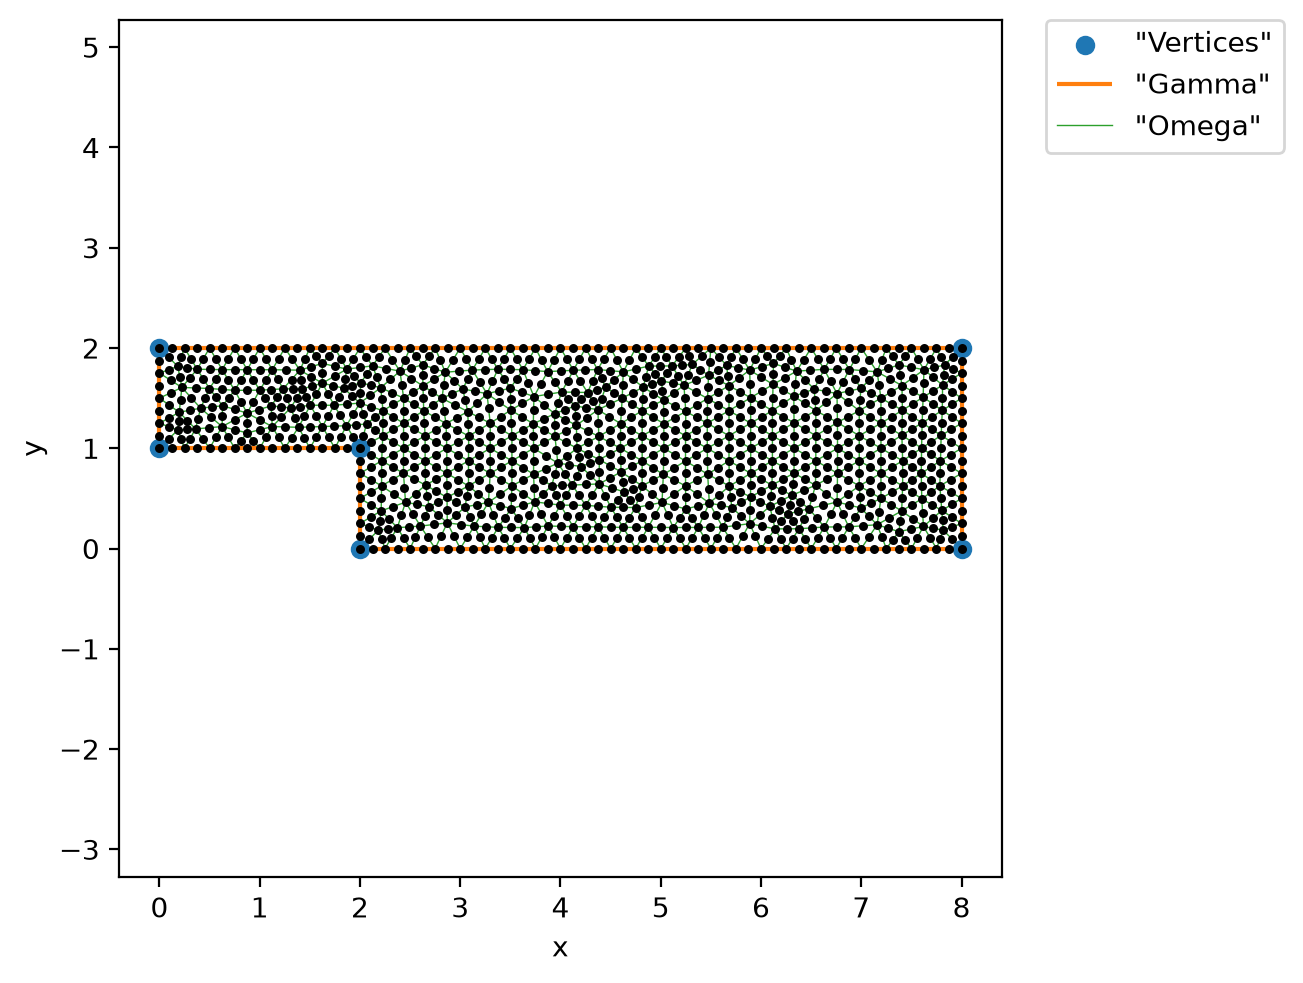

Infos du Maillage sur le bord: 
 Noeuds Dirichlet: 145 
 Noeuds Neumann: 15


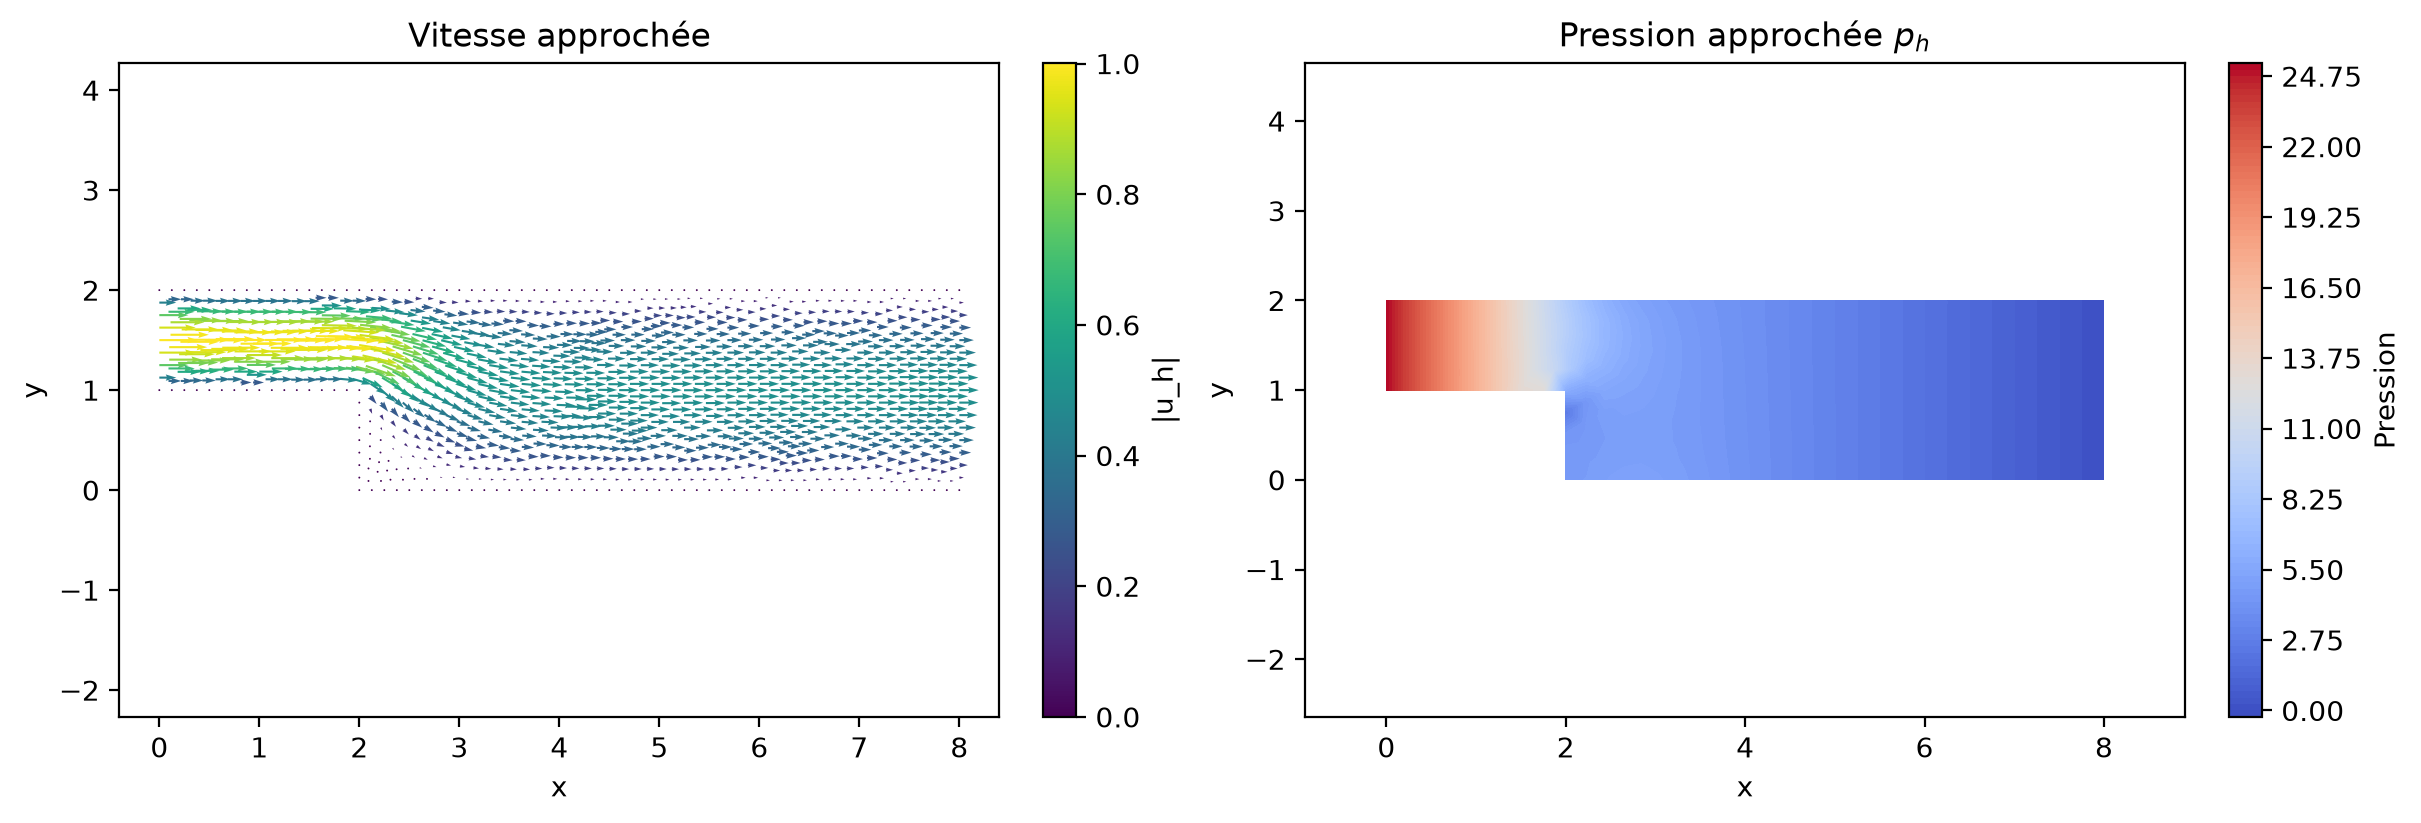

débit entrant = 0.6666666666666666    débit sortant ≈ 0.6640624999965419


In [35]:
def noeuds_dirichlet_hors_sortie(mesh, est_sortie):
    '''Noeuds de Dirichlet = tous les noeuds du bord sauf ceux de la sortie (Neumann).
    est_sortie(x, y) renvoie un tableau de booléens.'''
    noeuds_bord = mesh.domain_node_indices(domain_name="Gamma", element_type="line")
    x, y = mesh.nodes[noeuds_bord, 0], mesh.nodes[noeuds_bord, 1]
    return noeuds_bord[~est_sortie(x, y)]


# Canal d'entrée de hauteur 1 (1 < y < 2) qui débouche dans un canal de hauteur 2
options = src.GmshOptions(element_order=2)
mesh_marche = src.polygon(
    point_coords=[(0, 1), (2, 1), (2, 0), (8, 0), (8, 2), (0, 2)], mesh_size=0.25, gmsh_options=options
)


def g_marche(S):
    # entrée x = 0 : profil parabolique de vitesse maximale 1 ; parois : adhérence
    if S[0] < tol:
        return (4 * (S[1] - 1) * (2 - S[1]), 0.0)
    return (0.0, 0.0)


noeuds_D_marche = noeuds_dirichlet_hors_sortie(
    mesh_marche, lambda x, y: (abs(x - 8) < tol) & (y > tol) & (y < 2 - tol)
)
u1_m, u2_m, p_m = solve_stokes(mesh_marche, noeuds_D_marche, g_marche, 1.0)


############## VERIFICATIONS DE LA SOLUTION ##############

# Conservation du débit : débit entrant = int_1^2 4 (y-1)(2-y) dy = 2/3
tri_m = mesh_marche.domains["Omega"]["triangle"].astype(int)
tri_m = mtri.Triangulation(
    mesh_marche.nodes[:, 0], mesh_marche.nodes[:, 1],
    np.vstack([tri_m[:, [0, 3, 5]], tri_m[:, [3, 1, 4]], tri_m[:, [5, 4, 2]], tri_m[:, [3, 4, 5]]]),
)
yy = np.linspace(0, 2, 401)
u1_sortie = mtri.LinearTriInterpolator(tri_m, u1_m)(np.full_like(yy, 8 - 1e-9), yy)
print("débit entrant =", 2 / 3, "   débit sortant ≈", np.sum((u1_sortie[1:] + u1_sortie[:-1]) / 2 * np.diff(yy)))

### b) Canal avec chicanes et influence de la viscosité


=========== viscosité nu = 1.0 ===========


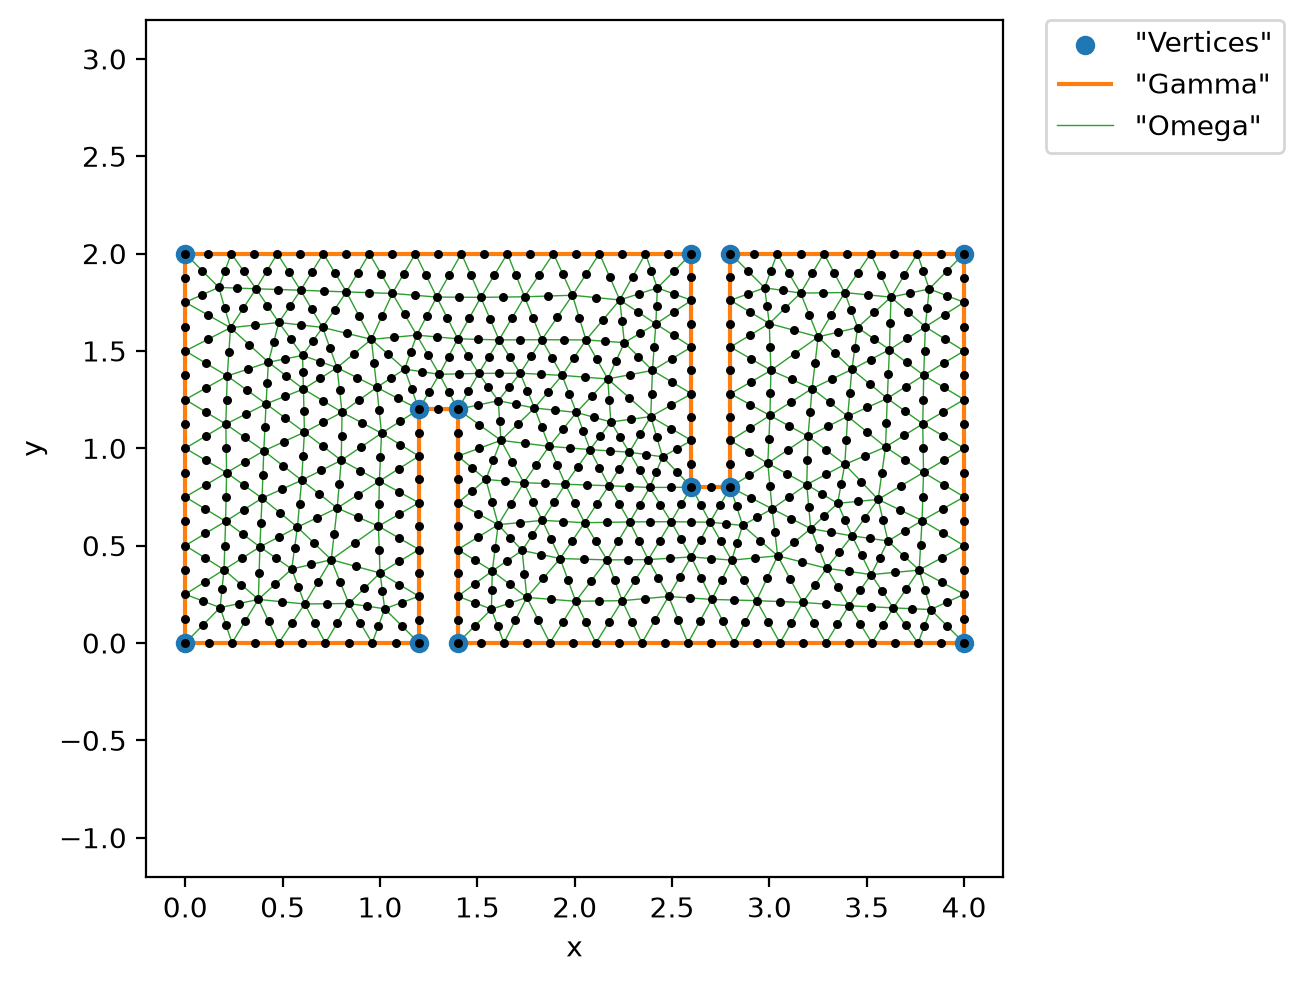

Infos du Maillage sur le bord: 
 Noeuds Dirichlet: 125 
 Noeuds Neumann: 15


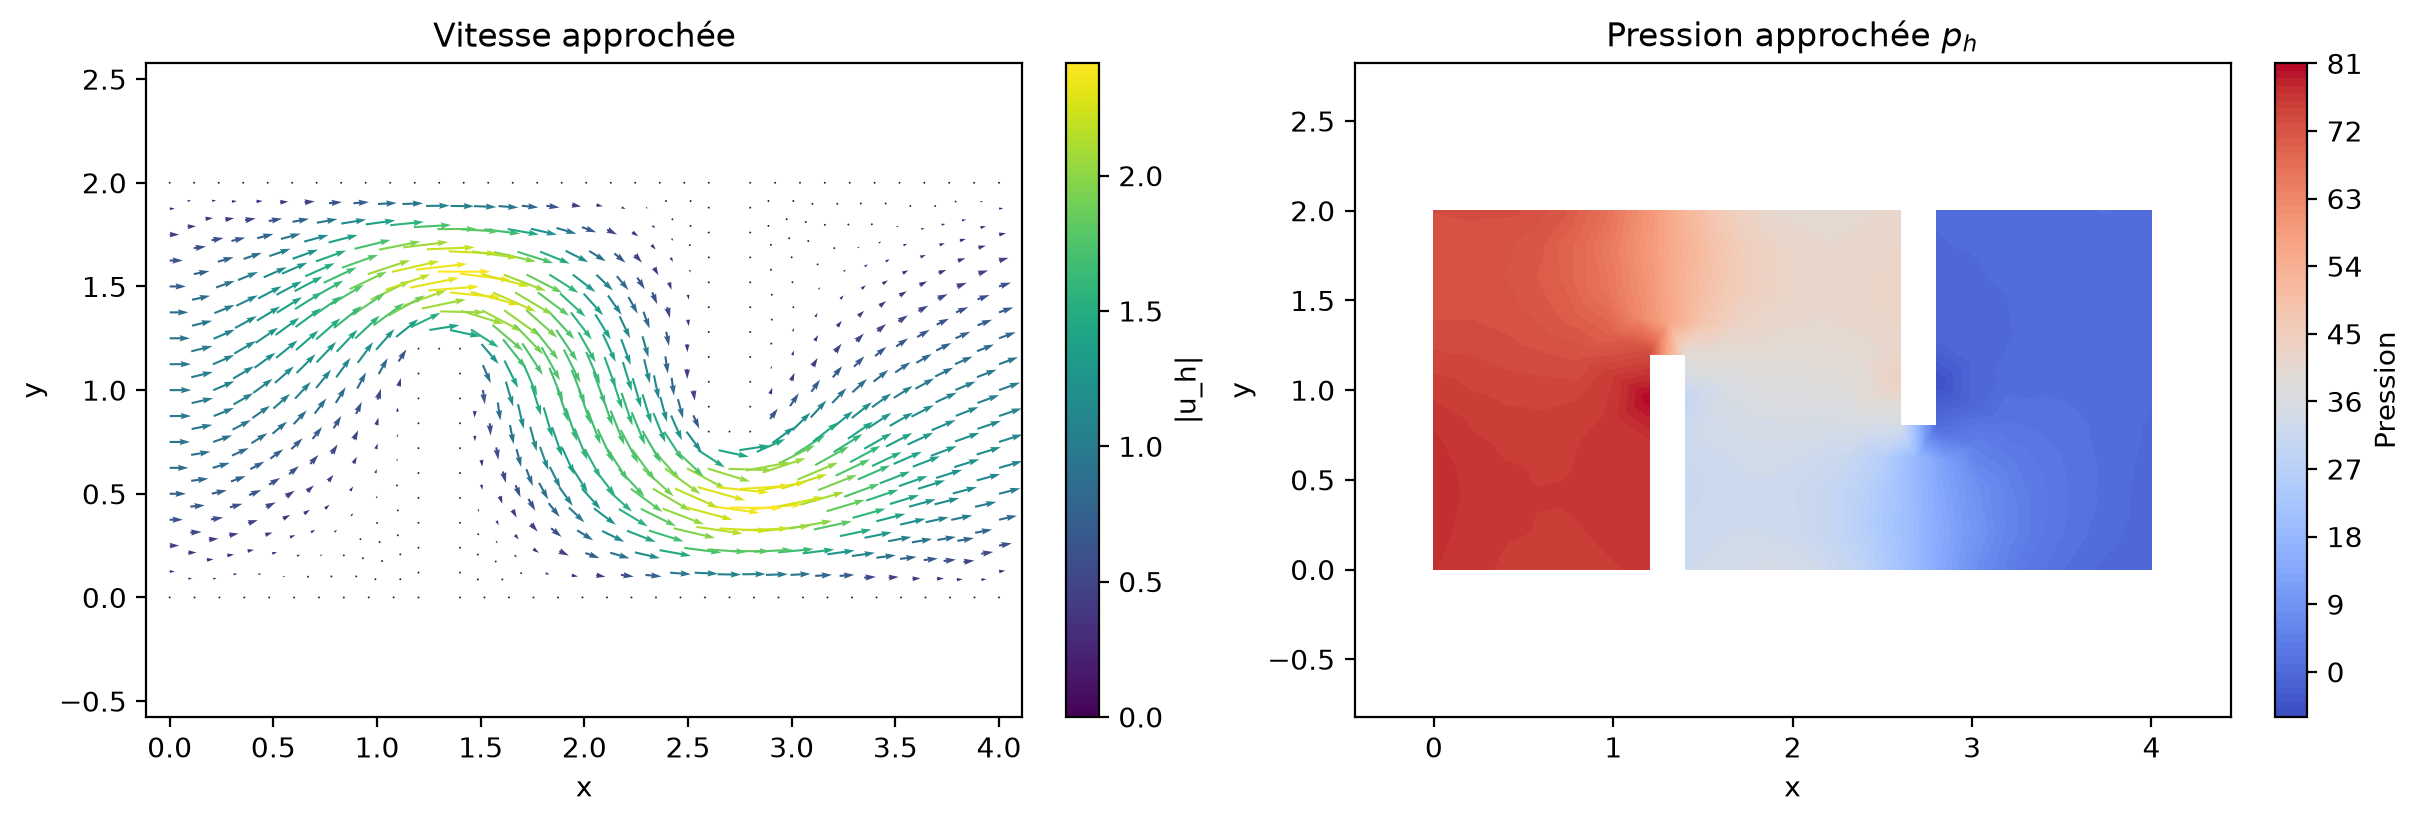


=========== viscosité nu = 0.01 ===========


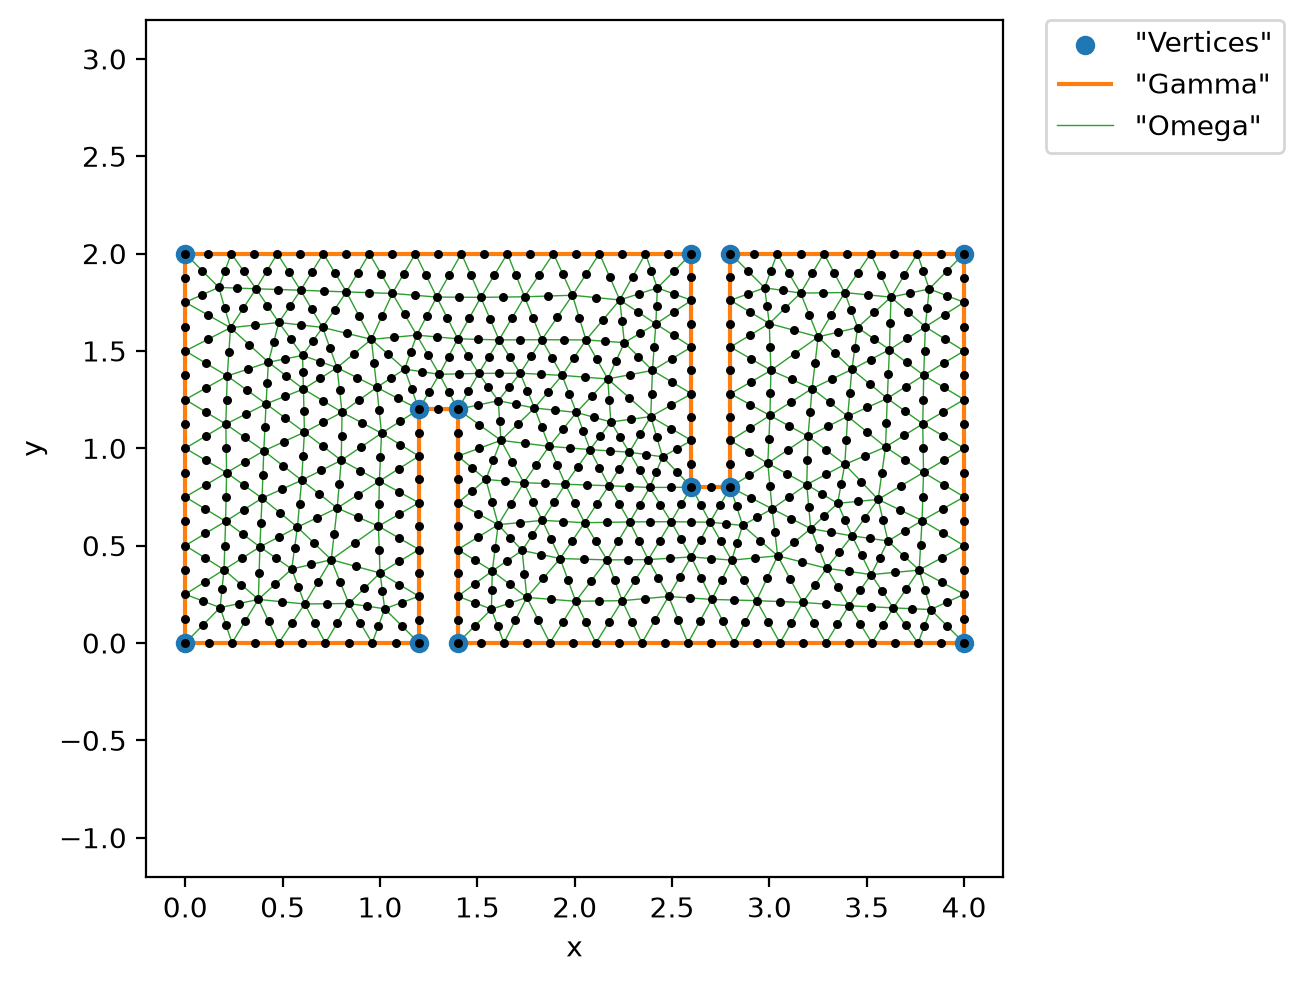

Infos du Maillage sur le bord: 
 Noeuds Dirichlet: 125 
 Noeuds Neumann: 15


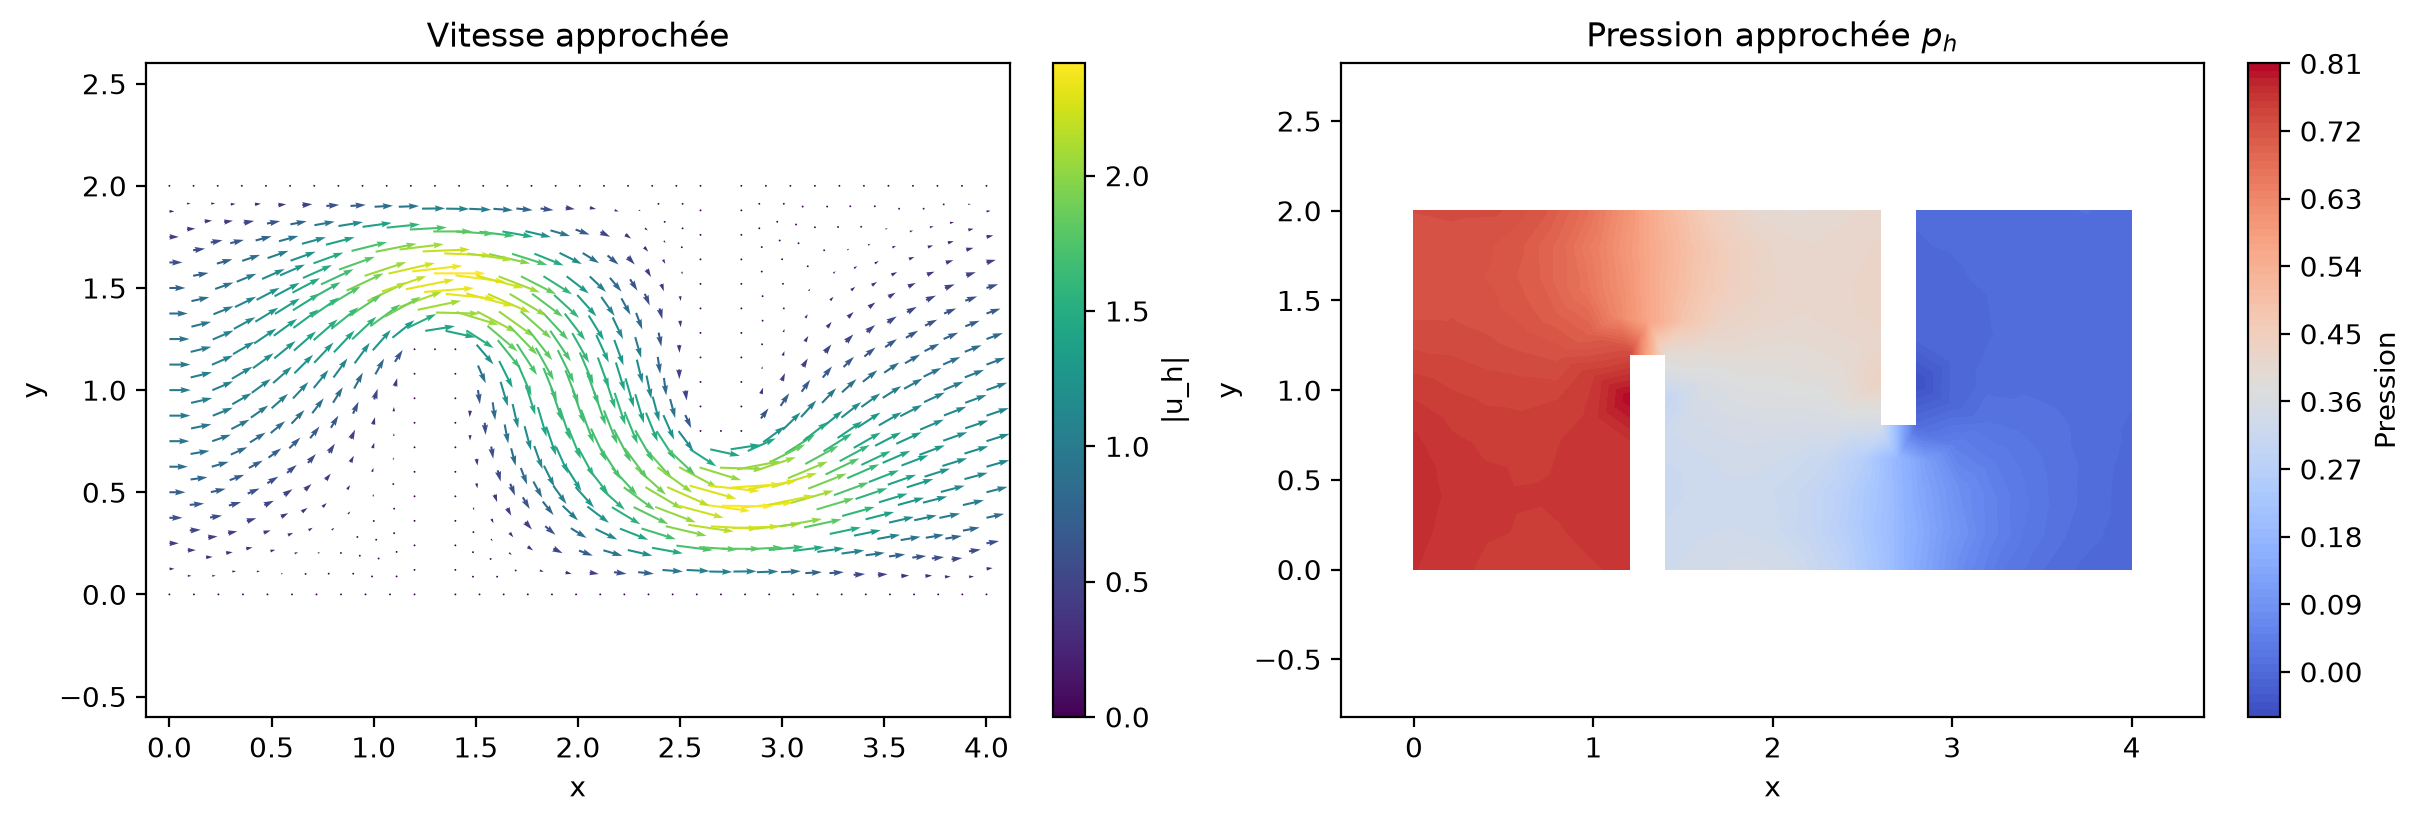

max |u(nu=1) - u(nu=0.01)|     = 4.0044356719448615e-14
max |p(nu=1) - 100 p(nu=0.01)| = 1.4068746168049984e-12  (max |p| = 80.73987121591274 )


In [36]:
points_chicane = [
    (0, 0), (1.2, 0), (1.2, 1.2), (1.4, 1.2), (1.4, 0), (4, 0),  # paroi basse + 1er obstacle
    (4, 2), (2.8, 2), (2.8, 0.8), (2.6, 0.8), (2.6, 2), (0, 2),  # paroi haute + 2e obstacle
]
mesh_chicane = src.polygon(point_coords=points_chicane, mesh_size=0.25, gmsh_options=options)


def g_chicane(S):
    # entrée x = 0 : profil parabolique y (2 - y) ; parois et obstacles : adhérence
    if S[0] < tol:
        return (S[1] * (2 - S[1]), 0.0)
    return (0.0, 0.0)


noeuds_D_chicane = noeuds_dirichlet_hors_sortie(
    mesh_chicane, lambda x, y: (abs(x - 4) < tol) & (y > tol) & (y < 2 - tol)
)

resultats = {}
for viscosite in [1.0, 0.01]:
    print(f"\n=========== viscosité nu = {viscosite} ===========")
    resultats[viscosite] = solve_stokes(mesh_chicane, noeuds_D_chicane, g_chicane, viscosite)

(u1_a, u2_a, p_a), (u1_b, u2_b, p_b) = resultats[1.0], resultats[0.01]
print("max |u(nu=1) - u(nu=0.01)|     =", max(np.abs(u1_a - u1_b).max(), np.abs(u2_a - u2_b).max()))
print("max |p(nu=1) - 100 p(nu=0.01)| =", np.abs(p_a - 100 * p_b).max(), " (max |p| =", np.abs(p_a).max(), ")")

### c) Domaine en L et variation de vitesse


=========== Vitesse d'entrée U = 1.0 ===========


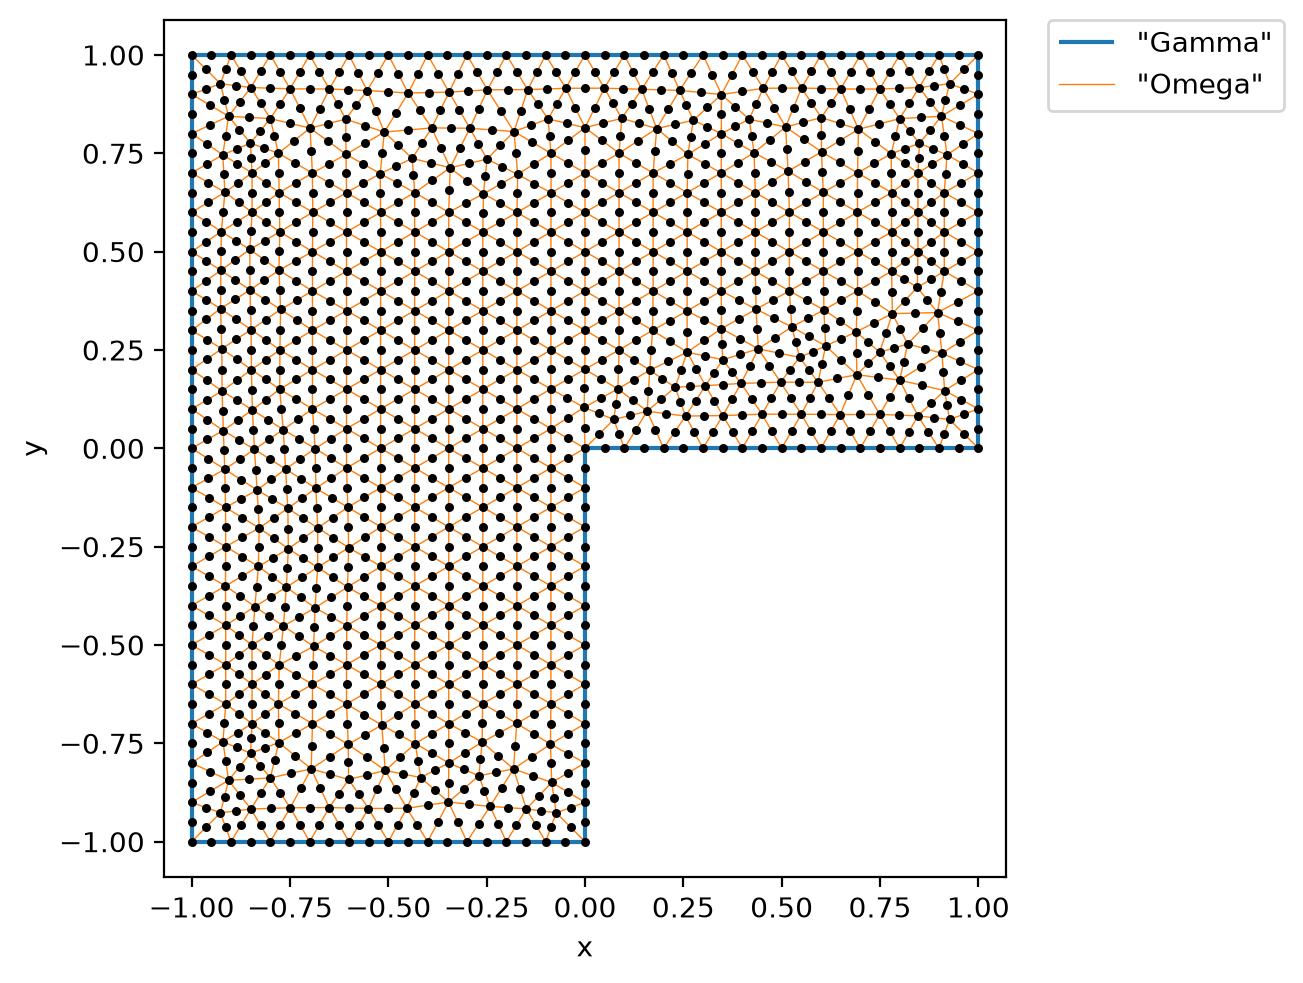

Infos du Maillage sur le bord: 
 Noeuds Dirichlet: 141 
 Noeuds Neumann: 19


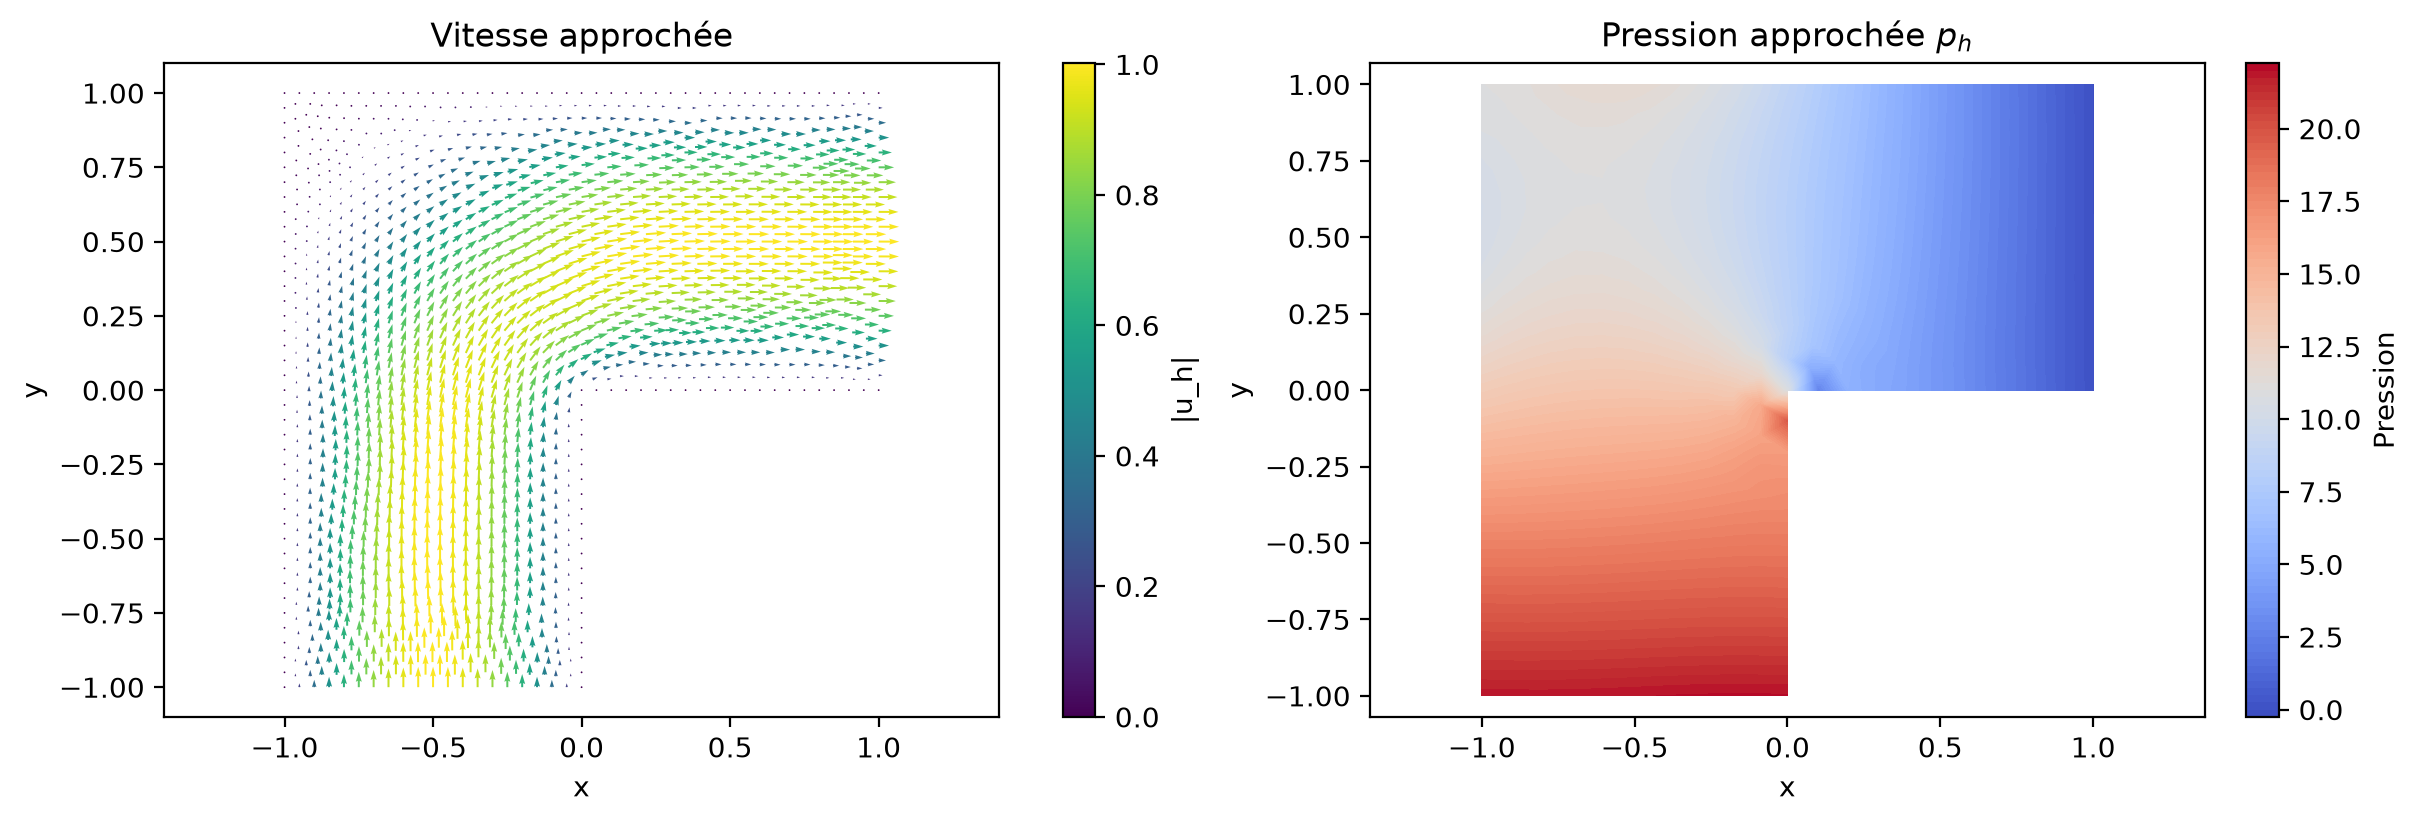


=========== Vitesse d'entrée U = 2.0 ===========


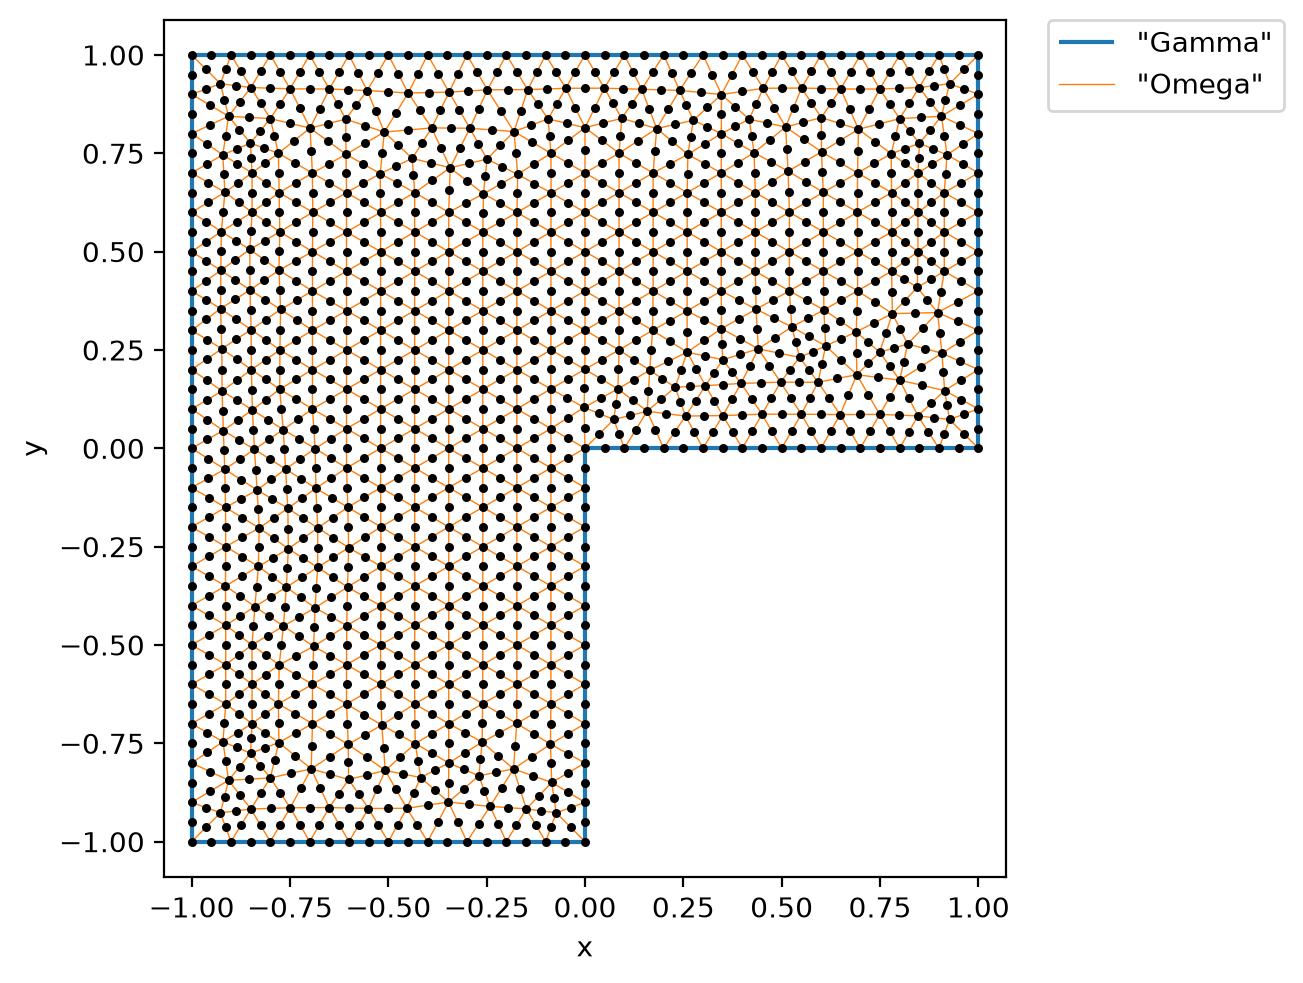

Infos du Maillage sur le bord: 
 Noeuds Dirichlet: 141 
 Noeuds Neumann: 19


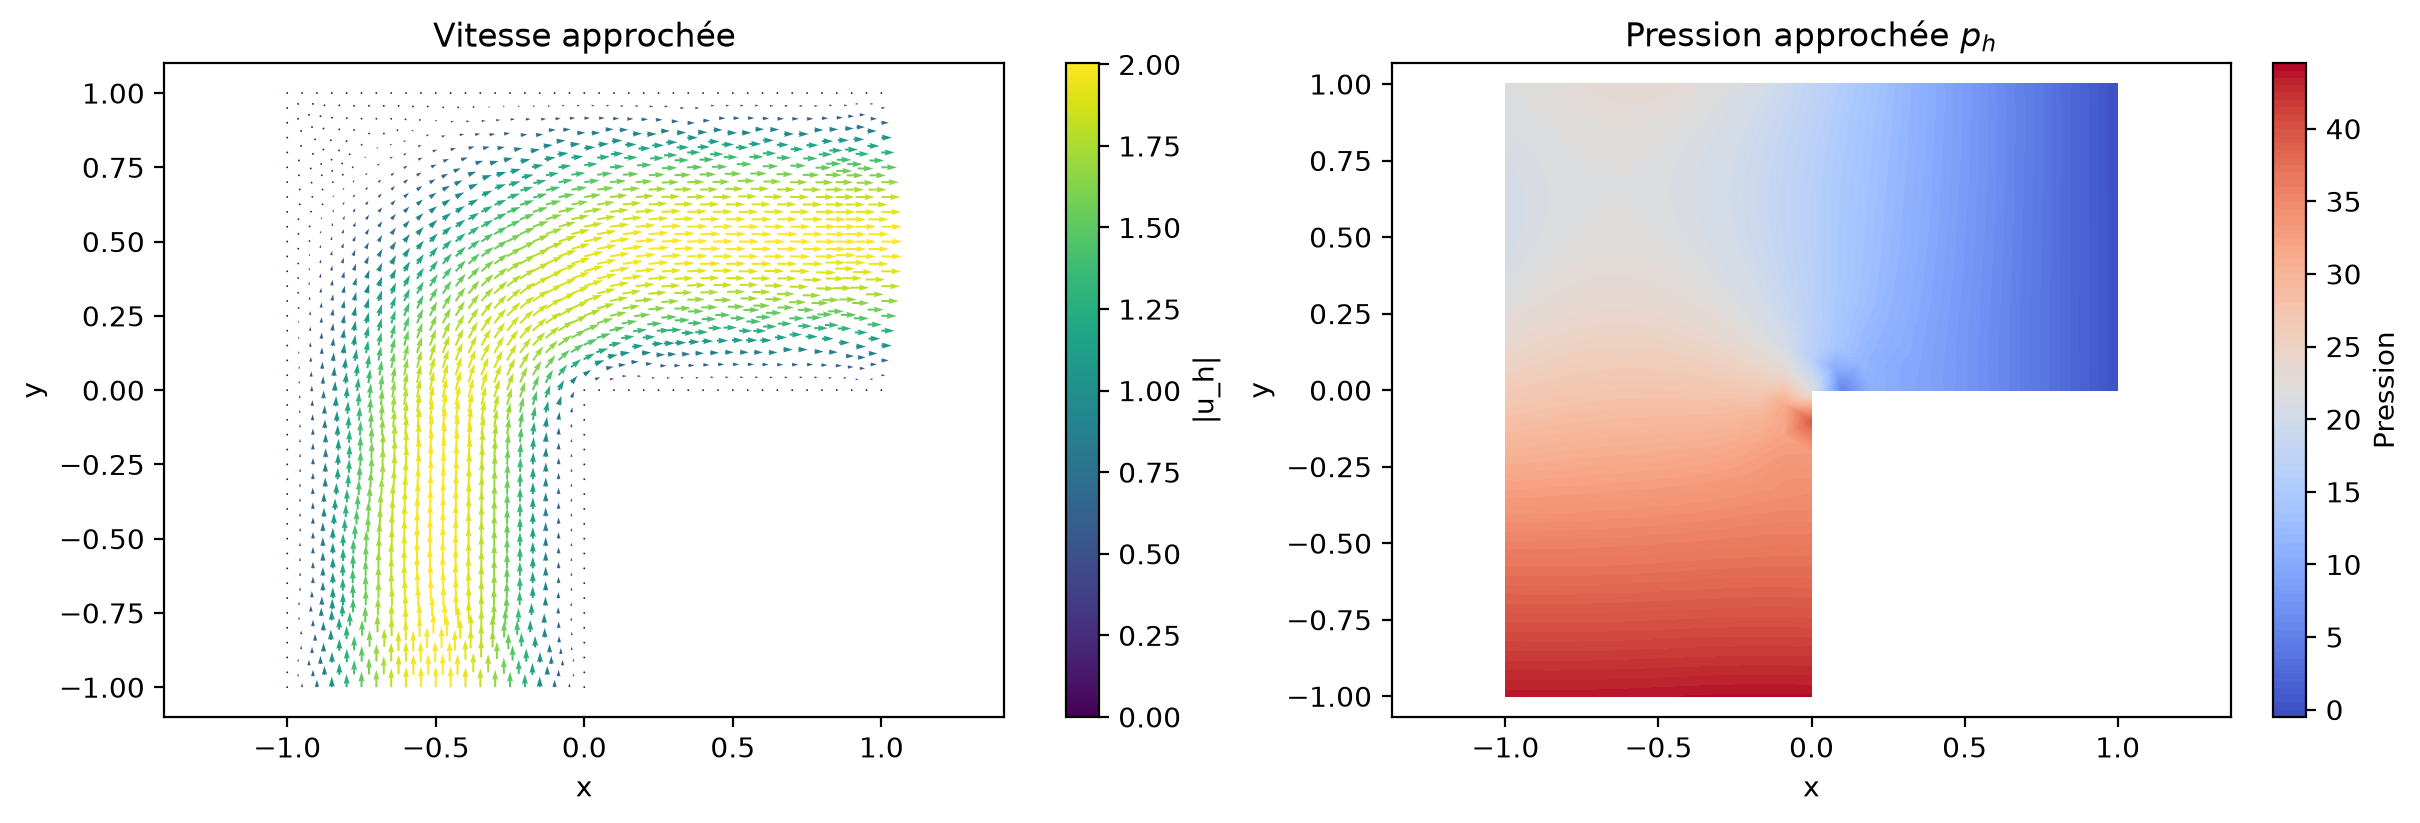


--- Teste de Linearidade do Sistema ---
max |u(U=2) - 2*u(U=1)| = 0.0
max |p(U=2) - 2*p(U=1)| = 0.0

--- Bilan de Débit ---
U = 1.0 | débit entrée = 0.665000 | débit sortie = 0.665000 | attendu = 0.666667
U = 2.0 | débit entrée = 1.330000 | débit sortie = 1.330000 | attendu = 1.333333


In [37]:
################################
#        L - SHAPE TEST        #
################################

tol = 1e-10
options = src.GmshOptions(element_order=2)

# L : (-1,-1) -> (0,-1) -> (0,0) -> (1,0) -> (1,1) -> (-1,1)
mesh_L = src.L_shape(0.1, gmsh_options=options)


def create_g_L(U_val):
    """Génère la fonction de condition aux limites pour une vitesse maximale U_val."""

    def g_L(S):
        # entrée y = -1, -1 < x < 0 : profil parabolique ; parois : adhérence
        x, y = S[0], S[1]
        if abs(y + 1) < tol and -1 < x < 0:
            return (0.0, 4 * U_val * (x + 1) * (-x))
        return (0.0, 0.0)

    return g_L



# sortie : x = 1, 0 < y < 1 (sans les coins)
noeuds_D_L = noeuds_dirichlet_hors_sortie(
    mesh_L, lambda x, y: (abs(x - 1) < tol) & (y > tol) & (y < 1 - tol)
)


def flux(mesh, u1h, u2h, noeuds, axe):
    """Débit sur un segment droit : axe=0 -> sortie verticale (u1 en fonction de y),
    axe=1 -> entrée horizontale (u2 en fonction de x)."""
    t = mesh.nodes[noeuds, 1 - axe]          # coordonnée le long du segment
    v = (u1h if axe == 0 else u2h)[noeuds]
    o = np.argsort(t)
    return np.trapezoid(v[o], t[o])          # np.trapz -> np.trapezoid


# Viscosité constante
viscosite_fixe = 1.0
resultats_L = {}
perfis_U = [1.0, 2.0]

for U_val in perfis_U:
    print(f"\n=========== Vitesse d'entrée U = {U_val} ===========")
    g_L_actuel = create_g_L(U_val)
    resultats_L[U_val] = solve_stokes(
        mesh_L, noeuds_D_L, g_L_actuel, viscosite_fixe
    )

(u1_a, u2_a, p_a), (u1_b, u2_b, p_b) = resultats_L[1.0], resultats_L[2.0]

# Validation de la linéarité : u(2U) = 2*u(U) et p(2U) = 2*p(U)
print("\n--- Teste de Linearidade do Sistema ---")
print(
    "max |u(U=2) - 2*u(U=1)| =",
    max(np.abs(u1_b - 2 * u1_a).max(), np.abs(u2_b - 2 * u2_a).max()),
)
print("max |p(U=2) - 2*p(U=1)| =", np.abs(p_b - 2 * p_a).max())

# Bilan de débit (attendu : 2U/3 para cada U)
nb = mesh_L.domain_node_indices(domain_name="Gamma", element_type="line")
x, y = mesh_L.nodes[nb, 0], mesh_L.nodes[nb, 1]
n_in = nb[(abs(y + 1) < tol) & (x > -1 - tol) & (x < tol)]
n_out = nb[(abs(x - 1) < tol) & (y > -tol) & (y < 1 + tol)]

print("\n--- Bilan de Débit ---")
for U_val in perfis_U:
    u1h, u2h, _ = resultats_L[U_val]
    deb_in = flux(mesh_L, u1h, u2h, n_in, 1)
    deb_out = flux(mesh_L, u1h, u2h, n_out, 0)
    print(
        f"U = {U_val:<3.1f} | débit entrée = {deb_in:.6f} | débit sortie ="
        f" {deb_out:.6f} | attendu = {2 * U_val / 3:.6f}"
    )

<hr width="50%" align="left">

- <span style="color:green">__Réponse 3.8__</span> Quelques observations :

- **Géométrie et Écoulement.** Dans les trois configurations (marche descendante, canal avec ailettes et domaine en L), la vitesse est maximale au centre du canal / dans les rétrécissements et quasi nulle sur les parois en raison des conditions d'adhérence. 
  - Pour la **marche descendante**, le fluide s'étale après la marche et retrouve un profil de Poiseuille plus en aval.
  - Pour le **canal avec ailettes**, le fluide contourne les deux obstacles en serpentant et accélère à leur passage.
  - Pour le **domaine en L**, le fluide entre verticalement avec un profil parabolique, effectue le virage à $90^\circ$ et ressort horizontalement.
  
  Dans l'ensemble des cas, la conservation du débit est vérifiée (le débit sortant égalant le débit entrant $2U/3$, à l'erreur d'interpolation près). Sans terme de convection dans les équations de Stokes, on n'observe aucune zone de recirculation (derrière la marche, les ailettes ou dans le coude du L), contrairement à un écoulement à grand nombre de Reynolds.

- **Singularités Géométriques.** La pression chute globalement entre l'entrée et la sortie mais présente des pics et des gradients très marqués aux coins réentrants (coin de la marche, extrémités des ailettes et origine $(0,0)$ du domaine en L). Ce sont des singularités géométriques théoriques (où le gradient de vitesse et la pression divergent) : la solution y est moins régulière et il faudrait y raffiner localement le maillage.

- **Viscosité et Linéarité du Système.** 
  - *Effet de la viscosité $\nu$ (étudié sur le canal avec ailettes) :* Le champ de vitesse ne dépend pas de $\nu$ et la pression lui est directement proportionnelle. Si $(\boldsymbol u, p)$ est solution pour $\nu=1$, alors $(\boldsymbol u, \nu p)$ est solution pour la viscosité $\nu$ (avec $\boldsymbol f=\mathbf{0}$).
  - *Effet du profil d'entrée $U$ (étudié sur le domaine en L) :* La linéarité du système est tout aussi confirmée : doubler l'amplitude $U$ de la vitesse d'entrée multiplie exactement par $2$ le champ de vitesse $\boldsymbol u$ et la pression $p$ dans l'ensemble du domaine (écarts numériques de l'ordre de la précision machine $\sim 10^{-14}$).

<hr width="50%" align="left">

<span style="color:red"><strong>Extra - Étude d'erreur du problème de Stokes en P2-P1</strong></span>

**Objectif.** La validation par Poiseuille (question 3.7) ne permet pas de mesurer une vitesse de convergence, car la solution exacte appartient à l'espace d'éléments finis et l'erreur est de l'ordre de la précision machine. On s'inspire ici des questions 1.10 et 2.6 : on choisit une solution *non polynomiale* et on trace l'erreur en fonction de $h$.

**Solution manufacturée sur $\Omega=]0,1[^2$.** On prend la fonction de courant $\psi(x,y)=\sin^2(\pi x)\,\sin^2(\pi y)$ et
$$
u_1=\partial_y\psi,\qquad u_2=-\partial_x\psi,\qquad p=\sin(\pi x)\cos(\pi y).
$$
- $\operatorname{div}\boldsymbol u=0$ est vérifiée par construction, et $\boldsymbol u=\boldsymbol 0$ sur tout le bord, donc $\Gamma_D=\Gamma$ avec $\boldsymbol g=\boldsymbol 0$ et $\Gamma_N=\emptyset$
- Le second membre $\boldsymbol f=-\nu\Delta\boldsymbol u+\nabla p$ est calculé symboliquement (`sympy`) puis interpolé aux nœuds : $\vec L_{u_i}=\mathbb M\,\vec f_i$, avec la matrice de masse $P^2$ de l'exercice 1.
- Comme $\Gamma_N=\emptyset$, la pression n’intervient que par son gradient : $p$ et $p+c$ sont solutions et $\mathbb A$ est singulière. On fixe donc $p_h$ en un sommet, et on compare $p$ et $p_h$ après avoir retiré leur moyenne.

**Erreurs mesurées** (en assimilant $\boldsymbol u$ à son interpolée, comme aux questions 1.10 et 1.11) :
$$
\frac{\Vert \boldsymbol u-\boldsymbol u_h\Vert_{L^2}}{\Vert \boldsymbol u\Vert_{L^2}},\qquad
\frac{\vert \boldsymbol u-\boldsymbol u_h\vert_{1}}{\vert \boldsymbol u\vert_{1}},\qquad
\frac{\Vert p-p_h\Vert_{L^2}}{\Vert p\Vert_{L^2}},
$$
calculées avec $\mathbb M$ et $\mathbb K$, pour $h\in\{0.2,\,0.1,\,0.05,\,0.025\}$.

**Résultat attendu.** Pour des éléments de Taylor-Hood et une solution régulière, on s'attend à des pentes (en échelle log-log) égales à $3$ pour la vitesse en norme $L^2$, $2$ pour la vitesse en semi-norme $H^1$ et $2$ pour la pression en norme $L^2$. Une concordance avec ces ordres valide l'ensemble de la chaîne (matrices élémentaires $\mathbb K,\mathbb E,\mathbb F$, assemblage, pseudo-élimination), ce que le test de Poiseuille ne peut pas faire.

$\|u-u_h\|_{L^2}/\|u\|_{L^2}$: ordre estimé = 3.68, ordres locaux = [3.57 3.65 3.81]
$|u-u_h|_{1}/|u|_{1}$: ordre estimé = 2.55, ordres locaux = [2.49 2.36 2.84]
$\|p-p_h\|_{L^2}/\|p\|_{L^2}$: ordre estimé = 2.58, ordres locaux = [2.89 2.31 2.65]


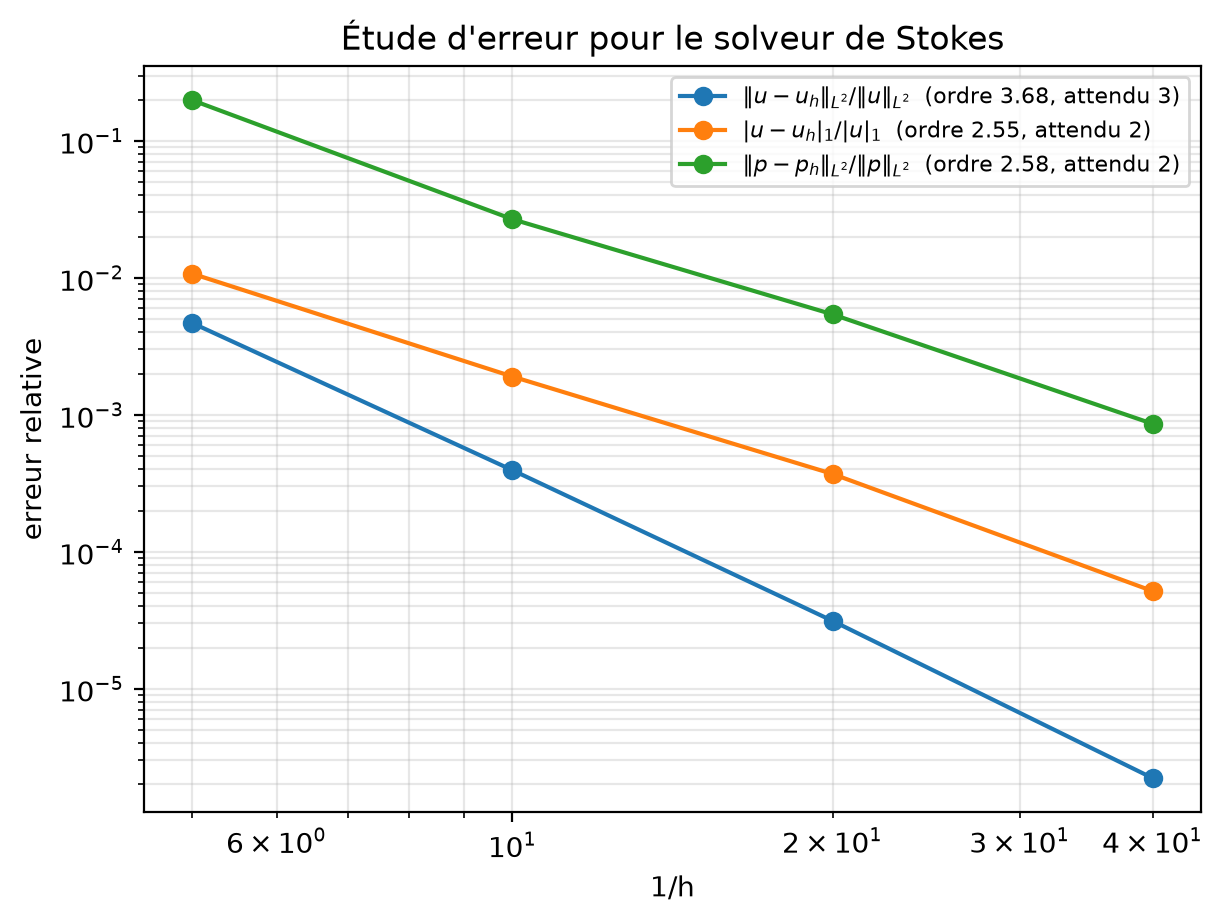

In [38]:
# calcul de la solution exacte 
xs, ys = sy.symbols("x y")
nu_conv = 1.0
psi = sy.sin(sy.pi*xs)**2 * sy.sin(sy.pi*ys)**2
u1s, u2s = sy.diff(psi, ys), -sy.diff(psi, xs)
ps = sy.sin(sy.pi*xs) * sy.cos(sy.pi*ys)
lap = lambda w: sy.diff(w, xs, 2) + sy.diff(w, ys, 2)
f1s = -nu_conv*lap(u1s) + sy.diff(ps, xs)
f2s = -nu_conv*lap(u2s) + sy.diff(ps, ys)

u1_ex, u2_ex, p_ex, f1, f2 = [sy.lambdify((xs, ys), e, "numpy") for e in (u1s, u2s, ps, f1s, f2s)]


def p_P1_vers_P2(mesh, ph, indS_to_indN):
    """Étend la pression P1 (sommets) aux N noeuds P2 (milieux d'arêtes = moyenne)."""
    tri = mesh.domains["Omega"]["triangle"].astype(int)
    pn = np.zeros(mesh.nb_nodes)
    pn[indS_to_indN] = ph
    pn[tri[:, 3]] = 0.5 * (pn[tri[:, 0]] + pn[tri[:, 1]])   # milieu de S1S2
    pn[tri[:, 4]] = 0.5 * (pn[tri[:, 1]] + pn[tri[:, 2]])   # milieu de S2S3
    pn[tri[:, 5]] = 0.5 * (pn[tri[:, 2]] + pn[tri[:, 0]])   # milieu de S3S1
    return pn


def error_study_stokes(h, nu=nu_conv):

    options = src.GmshOptions(element_order=2)
    mesh = src.rectangle((0, 0), (1, 1), h, options)
    N = mesh.nb_nodes
    indN_to_indS, indS_to_indN = numerotation_sommets_noeuds(mesh)
    Ns = len(indS_to_indN)
    x, y = mesh.nodes[:, 0], mesh.nodes[:, 1]

    #construction des matrices
    K, M = mat_KM(mesh)
    A = mat_A_Stokes(mesh, nu)
    L = np.concatenate([M @ f1(x, y), M @ f2(x, y), np.zeros(Ns)])

    # Dirichlet homogène sur tout le bord (g = 0)
    noeuds_D = mesh.domain_node_indices(domain_name="Gamma", element_type="line")
    A, L = elimine_Stokes(A, L, mesh, noeuds_D)

    # pression fixée au sommet 0 (Gamma_N vide)
    k0, n0 = 2 * N, indS_to_indN[0]
    A = A.tolil()

    #ligne identité
    A[k0, :] = 0
    A[k0, k0] = 1.0
    L[k0] = p_ex(x[n0], y[n0])

    #obtenir la solution
    U = src.sparse_solve(A.tocsc(), L)
    u1h, u2h, ph = U[:N], U[N:2*N], U[2*N:]

    #obtenir les erreurs par rapport aux solutions exactes
    e1, e2 = u1_ex(x, y) - u1h, u2_ex(x, y) - u2h
    v1, v2 = u1_ex(x, y), u2_ex(x, y)

    #calculer les erreurs L2 et H1 avec les matrices M et K respectivement
    L2_u = np.sqrt(e1 @ (M @ e1) + e2 @ (M @ e2)) / np.sqrt(v1 @ (M @ v1) + v2 @ (M @ v2))
    H1_u = np.sqrt(e1 @ (K @ e1) + e2 @ (K @ e2)) / np.sqrt(v1 @ (K @ v1) + v2 @ (K @ v2))

    # pression P1 évaluée dans les éléments P2
    pn = p_P1_vers_P2(mesh, ph, indS_to_indN)
    pe = p_ex(x, y)
    un = np.ones(N)

    # constante choosie: moyenne de (pex - ph) pour minimiser l'erreur
    e = pe - pn
    e = e - (un @ (M @ e)) / (un @ (M @ un)) #moyenne de e
    pe0 = pe - (un @ (M @ pe)) / (un @ (M @ un))
    L2_p = np.sqrt(e @ (M @ e)) / np.sqrt(pe0 @ (M @ pe0))

    return L2_u, H1_u, L2_p


hs = np.array([0.2, 0.1, 0.05, 0.025])
solution = np.array([error_study_stokes(h) for h in hs])     # colonnes : L2(u), H1(u), L2(p)

noms = [r"$\|u-u_h\|_{L^2}/\|u\|_{L^2}$", r"$|u-u_h|_{1}/|u|_{1}$", r"$\|p-p_h\|_{L^2}/\|p\|_{L^2}$"]

pentes_attendus = [3, 2, 2]

fig, ax = plt.subplots(figsize=(6, 4.5), layout="constrained")
for j, (nom, att) in enumerate(zip(noms, pentes_attendus)):

    #calcul de la pente avec interpolation
    ordre = np.polyfit(np.log(1/hs), np.log(solution[:, j]), 1)[0] * -1

    #plot loglog
    ax.loglog(1/hs, solution[:, j], "o-", label=f"{nom}  (ordre {ordre:.2f}, attendu {att})")

    print(f"{nom}: ordre estimé = {ordre:.2f}, ordres locaux =",
          np.round(np.log(solution[:-1, j]/solution[1:, j]) / np.log(hs[:-1]/hs[1:]), 2))
    
ax.set_xlabel("1/h"); ax.set_ylabel("erreur relative"); ax.legend(fontsize=8); ax.grid(True, which="both", alpha=.3)
ax.set_title("Étude d'erreur pour le solveur de Stokes")

plt.show()

<span style="color:green"><strong>Réponse Extra - Étude d'erreur du problème de Stokes en P2-P1</strong></span>

**Résultats.** Pour $h\in\{0.2,\,0.1,\,0.05,\,0.025\}$, les pentes estimées en échelle log-log sont :

| Erreur relative | Ordre estimé | Ordre théorique |
|---|---|---|
| $\Vert \boldsymbol u-\boldsymbol u_h\Vert_{L^2}$ | $3.68$ | $3$ |
| $\vert \boldsymbol u-\boldsymbol u_h\vert_{1}$ | $2.55$ | $2$ |
| $\Vert p-p_h\Vert_{L^2}$ | $2.58$ | $2$ |

**Interprétation.** Les trois erreurs décroissent comme des puissances de $h$, avec des ordres estimés (en moyenne sur les quatre maillages) au moins égaux aux ordres théoriques des éléments de Taylor-Hood ($3$, $2$ et $2$). Cela valide l'ensemble de la chaîne de calcul (matrices élémentaires, assemblage, pseudo-élimination, second membre $\mathbb M\vec f$). Les ordres observés sont légèrement supérieurs aux ordres théoriques : la théorie fournit des ordres **garantis** (majorations), et la solution manufacturée est très régulière. Pour la pression, l'erreur est mesurée *à une constante près* (moyenne retirée), car $\Gamma_N=\emptyset$.

<span style="color:red"><strong>Question 3.9</strong></span> - À l’aide des routines du TP 1, modifier les codes pour discrétiser le problème de Stokes avec des éléments finis $P^1-P^1$ au lieu des éléments finis $P^2−P^1$ implémentés précédemment. Expliquer.

Poiseuille en P1-P1, erreurs maximales aux noeuds (pression exacte comprise entre 0 et 2.0)
     h       noeuds     u1          u2          p
   0.200       80    9.40e-03    9.40e-03    3.18e+00
   0.100      273    9.98e-04    5.63e-04    3.40e-01
   0.050      996    3.29e-04    4.11e-04    5.54e-01
   0.025     3819    1.29e-04    1.31e-04    3.31e-01


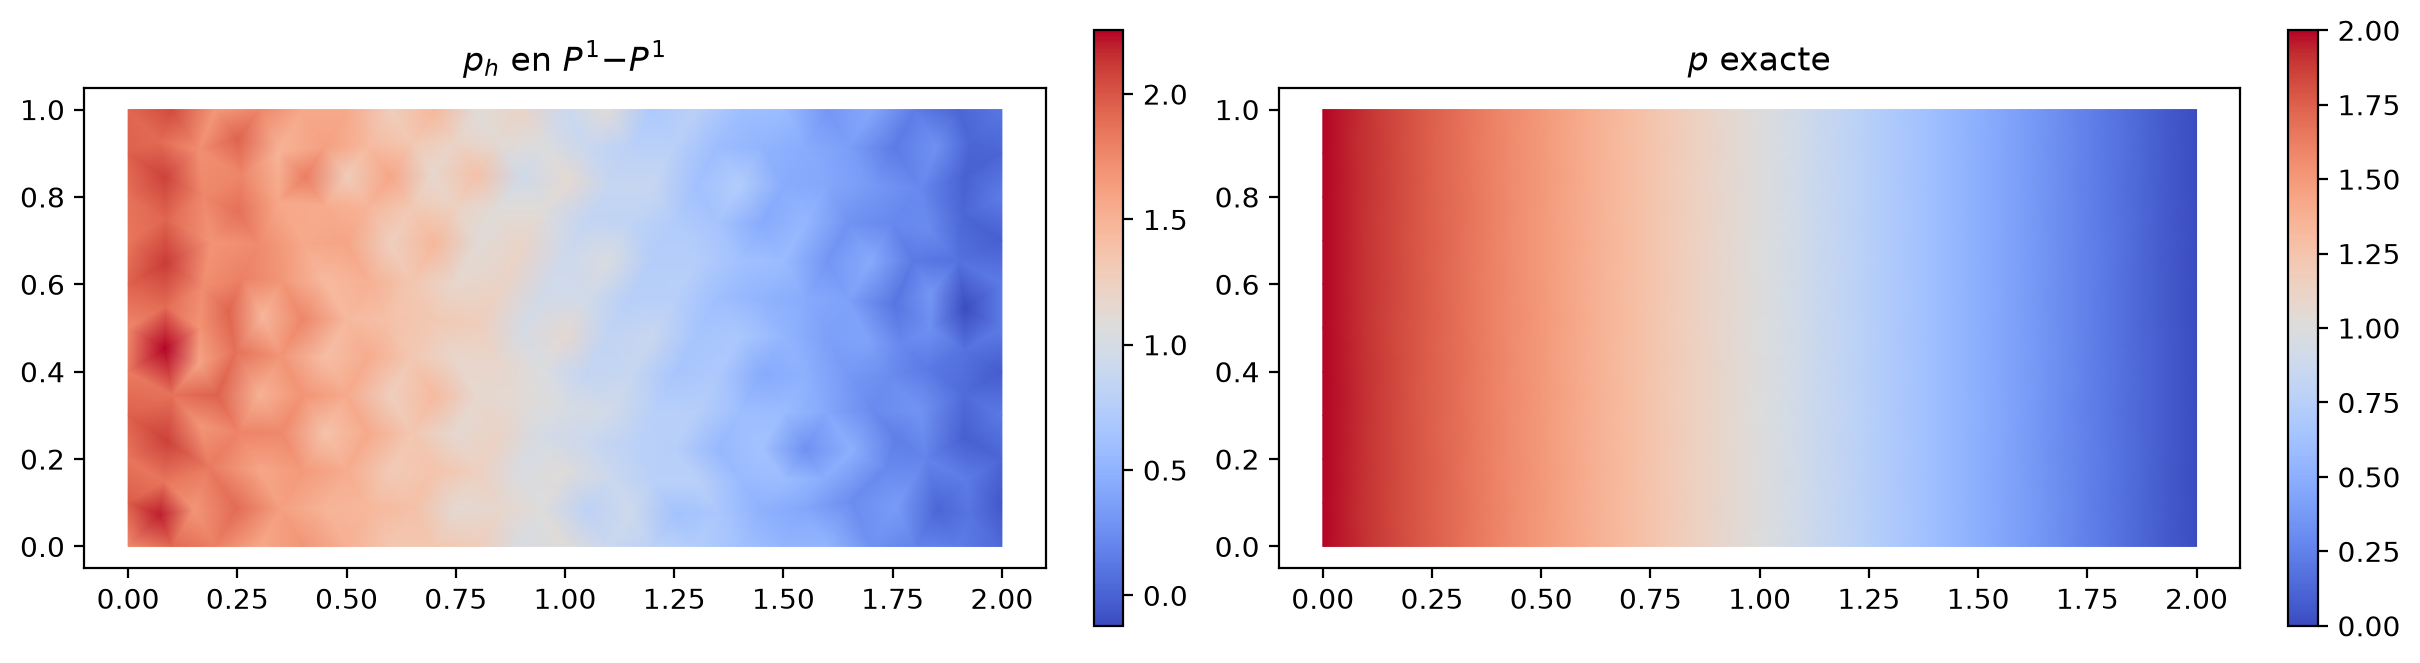

P1-P1 : plus petite valeur singulière / plus grande = 5.2e-07
P2-P1 : plus petite valeur singulière / plus grande = 3.2e-05


In [39]:
##########################################################################
# Question 3.9 : éléments finis P1-P1
##########################################################################
# Les fonctions de base P1 sont les coordonnées barycentriques lambda_i, de
# gradients constants sur le triangle (formules du TP1) :
#   grad lambda_1 = (y2 - y3, x3 - x2) / D,  grad lambda_2 = (y3 - y1, x1 - x3) / D,
#   grad lambda_3 = (y1 - y2, x2 - x1) / D.

nu, G = 1.0, 1.0
Lx, H = 2.0, 1.0

def u1_ex(x, y): return G / (2 * nu) * y * (H - y)
def p_ex(x, y):  return G * (Lx - x)


def grad_lambda_p1(S1, S2, S3):
    x1, y1 = S1
    x2, y2 = S2
    x3, y3 = S3
    D = (x2 - x1) * (y3 - y1) - (y2 - y1) * (x3 - x1)
    grad = np.array([[y2 - y3, x3 - x2], [y3 - y1, x1 - x3], [y1 - y2, x2 - x1]]) / D
    return grad, abs(D) / 2  # gradients (3x2) et aire du triangle


def elem_mat_K_p1(S1, S2, S3):
    # rigidité P1 (3x3) : aire * grad lambda_i . grad lambda_j
    grad, aire = grad_lambda_p1(S1, S2, S3)
    return aire * grad @ grad.T


def elem_mat_E_p1p1(S1, S2, S3):
    # E_ij = - int_T lambda_j d(lambda_i)/dx = - (aire / 3) d(lambda_i)/dx   (3x3)
    grad, aire = grad_lambda_p1(S1, S2, S3)
    return -aire / 3 * np.outer(grad[:, 0], np.ones(3))


def elem_mat_F_p1p1(S1, S2, S3):
    # F_ij = - int_T lambda_j d(lambda_i)/dy = - (aire / 3) d(lambda_i)/dy   (3x3)
    grad, aire = grad_lambda_p1(S1, S2, S3)
    return -aire / 3 * np.outer(grad[:, 1], np.ones(3))


def mat_A_Stokes_p1p1(mesh, nu):
    '''Matrice de Stokes P1-P1 sur un maillage d'ordre 1 : tous les noeuds sont des
    sommets, vitesse et pression ont le même nombre N d'inconnues (taille 3N).'''
    nb_nodes = mesh.nb_nodes
    triangles = mesh.domains["Omega"]["triangle"]
    K = sp.dok_array((nb_nodes, nb_nodes), dtype=float)
    E = sp.dok_array((nb_nodes, nb_nodes), dtype=float)
    F = sp.dok_array((nb_nodes, nb_nodes), dtype=float)
    for k in range(mesh.nb_elements("Omega", "triangle")):
        triangle = triangles[k, :]
        S1, S2, S3 = mesh.nodes[triangle[0]], mesh.nodes[triangle[1]], mesh.nodes[triangle[2]]
        K_elem = elem_mat_K_p1(S1, S2, S3)
        E_elem = elem_mat_E_p1p1(S1, S2, S3)
        F_elem = elem_mat_F_p1p1(S1, S2, S3)
        for i in range(3):
            I = triangle[i]
            for j in range(3):
                J = triangle[j]
                K[I, J] += K_elem[i, j]
                E[I, J] += E_elem[i, j]
                F[I, J] += F_elem[i, j]
    return sp.bmat([[nu * K, None, E], [None, nu * K, F], [E.T, F.T, None]], format="lil")


def poiseuille_p1p1(h_maillage):
    '''Poiseuille (mêmes données que la question 3.7) résolu en P1-P1.'''

    mesh_p1 = src.rectangle((0, 0), (Lx, H), h_maillage, src.GmshOptions(element_order=1))
    N1 = mesh_p1.nb_nodes

    noeuds_bord = mesh_p1.domain_node_indices(domain_name="Gamma", element_type="line")
    xb, yb = mesh_p1.nodes[noeuds_bord, 0], mesh_p1.nodes[noeuds_bord, 1]
    sortie = (abs(xb - Lx) < tol) & (yb > tol) & (yb < H - tol)
    
    A1 = mat_A_Stokes_p1p1(mesh_p1, nu)

    # elimine_Stokes se réutilise telle quelle : inconnues rangées [u1 (N), u2 (N), p (N)]
    A1, L1 = elimine_Stokes(A1, np.zeros(3 * N1), mesh_p1, noeuds_bord[~sortie], g)
    U1 = src.sparse_solve(A1.tocsc(), L1)
    return mesh_p1, U1[:N1], U1[N1 : 2 * N1], U1[2 * N1 :], A1


print(f"Poiseuille en P1-P1, erreurs maximales aux noeuds (pression exacte comprise entre 0 et {G * Lx})")
print("     h       noeuds     u1          u2          p")
for h_maillage in [0.2, 0.1, 0.05, 0.025]:
    mesh_p1, u1_p1, u2_p1, p_p1, A_p1 = poiseuille_p1p1(h_maillage)
    xn, yn = mesh_p1.nodes[:, 0], mesh_p1.nodes[:, 1]
    print(f"{h_maillage:8.3f} {mesh_p1.nb_nodes:8d}    {np.abs(u1_p1 - u1_ex(xn, yn)).max():.2e}    "
          f"{np.abs(u2_p1).max():.2e}    {np.abs(p_p1 - p_ex(xn, yn)).max():.2e}")

# Comparaison visuelle des pressions (h = 0.1, comme à la question 3.7)
mesh_p1, u1_p1, u2_p1, p_p1, A_p1 = poiseuille_p1p1(0.1)
tri_p1p1 = mtri.Triangulation(mesh_p1.nodes[:, 0], mesh_p1.nodes[:, 1],
                              mesh_p1.domains["Omega"]["triangle"].astype(int))
fig, axs = plt.subplots(ncols=2, figsize=(12, 3.2), layout="constrained")
for ax, champ, titre in [
    (axs[0], p_p1, "$p_h$ en $P^1{-}P^1$"),
    (axs[1], p_ex(mesh_p1.nodes[:, 0], mesh_p1.nodes[:, 1]), "$p$ exacte"),
]:
    im = ax.tripcolor(tri_p1p1, champ, shading="gouraud", cmap="coolwarm")
    fig.colorbar(im, ax=ax)
    ax.set_title(titre)
    ax.set_aspect("equal")
plt.show()

# Conditionnement (calcul dense, possible car les systèmes sont petits) : P1-P1 contre P2-P1
sv_p1 = np.linalg.svd(A_p1.toarray(), compute_uv=False)
sv_p2 = np.linalg.svd(A.toarray(), compute_uv=False)  # A : matrice P2-P1 de la question 3.7
print(f"P1-P1 : plus petite valeur singulière / plus grande = {sv_p1[-1] / sv_p1[0]:.1e}")
print(f"P2-P1 : plus petite valeur singulière / plus grande = {sv_p2[-1] / sv_p2[0]:.1e}")

<hr width="50%" align="left">

<span style="color:green">__Réponse 3.9__</span> - **Modifications du code.** Sur un maillage d'ordre 1, tous les nœuds sont des sommets : vitesse et pression ont chacune $N$ inconnues (système de taille $3N$) et la numérotation sommets/nœuds n'est plus nécessaire. Les matrices élémentaires $3\times3$ se calculent sans quadrature : les gradients des coordonnées barycentriques sont constants et $\int_T\lambda_j=\text{aire}(T)/3$. L'assemblage par blocs et la pseudo-élimination sont inchangés.

**Résultat.** Sur l'écoulement de Poiseuille, l'erreur sur la vitesse diminue avec $h$ (de $10^{-2}$ à $10^{-4}$ entre $h=0{,}2$ et $h=0{,}025$), mais **la pression ne converge pas** : son erreur maximale reste entre $0{,}3$ et $3$ pour une pression exacte comprise entre $0$ et $2$, et $p_h$ présente des oscillations d'un sommet à l'autre.

**Explication.** Stokes est un problème de **point-selle** : la pression est le multiplicateur de Lagrange de la contrainte $\operatorname{div}\boldsymbol u=0$. La coercivité contrôle la vitesse, mais pour contrôler la pression il faut en plus la **condition inf-sup discrète**
$$
\inf_{q_h}\ \sup_{\boldsymbol v_h}\ \frac{\int_\Omega q_h\operatorname{div}\boldsymbol v_h\,\mathrm d\Omega}{\Vert\boldsymbol v_h\Vert_{H^1}\,\Vert q_h\Vert_{L^2}}\ \ge\ \beta>0,\qquad \beta\ \text{indépendant de } h,
$$
c'est-à-dire que toute pression doit être « détectée » par une vitesse discrète. Avec $P^1{-}P^1$, les vitesses sont trop pauvres : il existe des pressions oscillantes (*modes parasites*) telles que $\int_\Omega q_h\operatorname{div}\boldsymbol v_h\simeq0$ pour toute $\boldsymbol v_h$, que le schéma ne contrôle pas. Avec Taylor-Hood $P^2{-}P^1$, les degrés de liberté aux milieux des arêtes enrichissent la vitesse et la condition est vérifiée ; l'étude de convergence ci-dessus le confirme (pression à l'ordre $2$).

<hr width="50%" align="left">